In [91]:
import os
import json
from joblib import load
from typing import Callable,Tuple,Dict,Any

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

import shap
from IPython.display import display,HTML,Image

from constants import (
    OUTPUTS_PATH, 
    PLOTS_PATH, 
    FEATURES_NAMES, 
    BEST_PATH, 
    SELECTED_BEST_FEATURES,
    TARGET
)
from format_data import load_and_format_dataset

In [92]:
df_metrics_test = pd.DataFrame(columns=('dataset_type', 'columns', 'params_type', 'metric', 'value', 'model'))

row_i = 0
for dataset_type in os.listdir(OUTPUTS_PATH):
    if dataset_type in ['best-features', 'table.html', 'table.json', '.ipynb_checkpoints']:
        continue
    
    for params_type in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type)):
        for columns in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type)):
            for model in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type, columns)):
                
                if 'npy' in model:
                    continue

                metrics_file = os.path.join(
                    OUTPUTS_PATH, dataset_type, params_type, columns, model, 'output_test_metrics.json'
                )

                with open(metrics_file, 'r') as file:
                    json_data = json.load(file)

                    for k in json_data.keys():
                        if ('confusion_matrix' == k) or \
                            ('macro' in k) or \
                            ('micro' in k) or \
                            ('jaccard' in k):
                            continue
                        df_metrics_test.loc[row_i] = {
                            'dataset_type': dataset_type,
                            'columns':columns,
                            'params_type':params_type,
                            'metric': k,
                            'value': json_data[k],
                            'model':model
                        }

                        row_i += 1
df_metrics_test = df_metrics_test.sort_values(by='model')
df_metrics_test.head()


,dataset_type,columns,params_type,metric,value,model
124,not_augmented,raw,default,roc_auc,0.779491,bagging_logistic
680,augmented,raw,default,accuracy,0.840449,bagging_logistic
264,not_augmented,all,default,roc_auc,0.794130,bagging_logistic
263,not_augmented,all,default,recall,0.727273,bagging_logistic
262,not_augmented,all,default,precision,0.739496,bagging_logistic


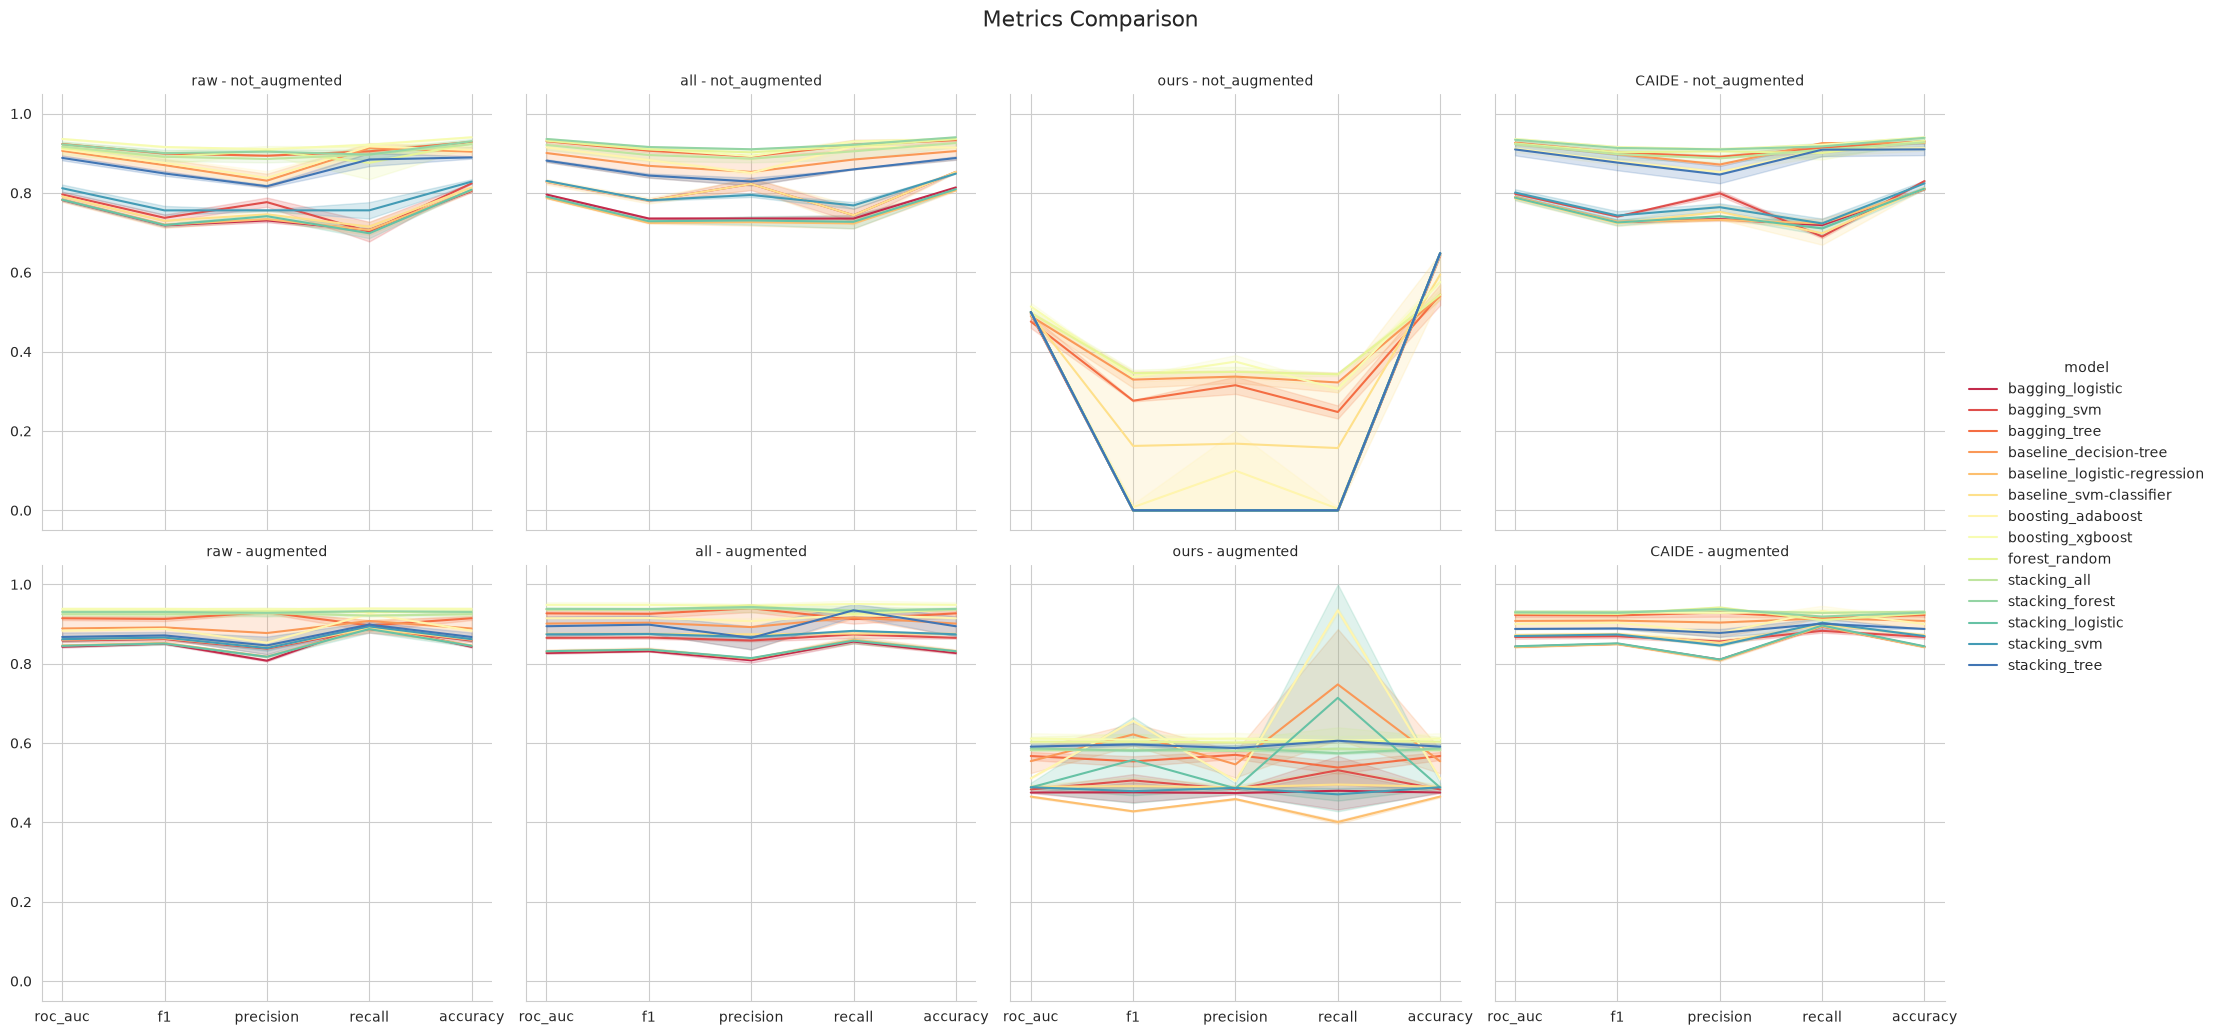

In [93]:
sns.set_style("whitegrid")
g = sns.relplot(
    kind='line',
    data=df_metrics_test,
    x='metric',
    y='value',
    hue='model',
    row='dataset_type',
    col='columns',
    palette='Spectral'
)
for ax in g.axes.flat:
  ax.grid(True, axis="x") 
g.set_titles(template="{col_name} - {row_name}")
g.set_axis_labels("", "")
plt.suptitle('Metrics Comparison', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('comparison_metrics_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

In [94]:
best_models = pd.DataFrame(columns=("dataset_type", "columns", "model"))

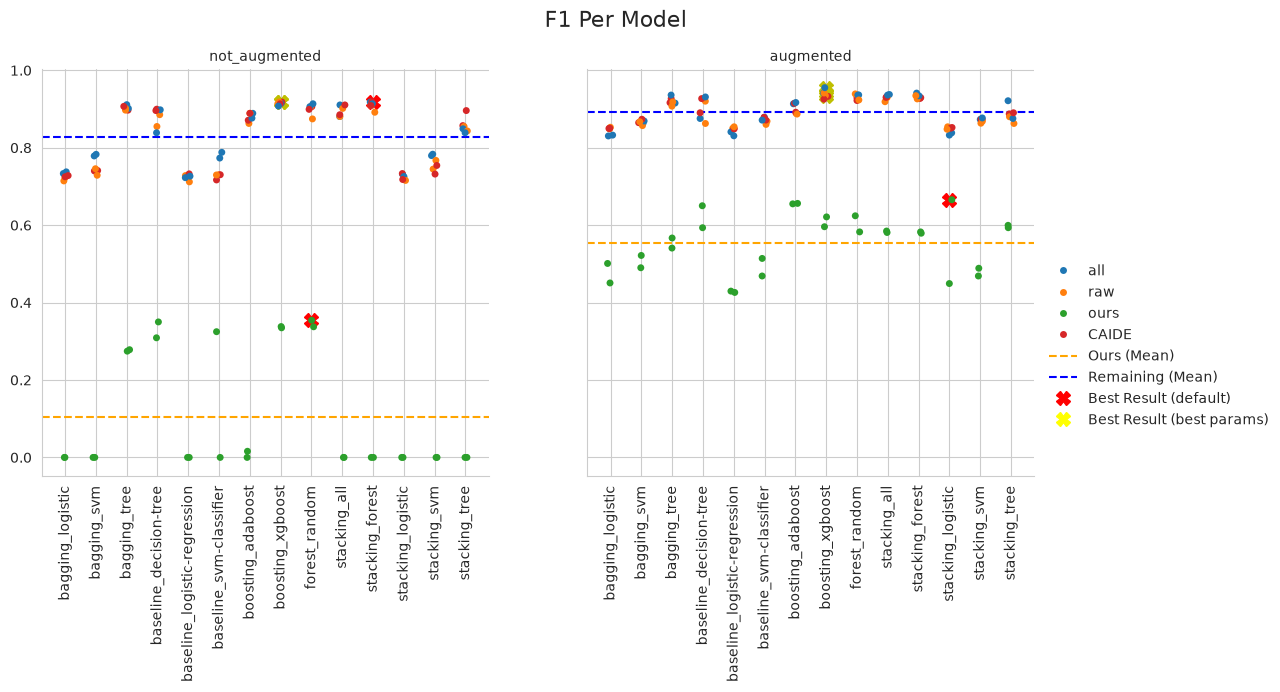

In [95]:
sns.set_style("whitegrid")
f1_data = df_metrics_test.loc[(df_metrics_test['metric'] == 'f1')]

g = sns.catplot(
    kind="strip", 
    data=f1_data, 
    x="model", 
    y='value',
    col='dataset_type',
    hue='columns',
)

for ax in g.axes.flat:
  ax.grid(
      True, axis="x",
  ) 

not_agumented_ax = g.axes[0,0]
agumented_ax = g.axes[0,1]

for dataset_type, ax in zip(('augmented', 'not_augmented'), (agumented_ax, not_agumented_ax)):
    for features in FEATURES_NAMES:
        d = f1_data[(f1_data['dataset_type'] == dataset_type)&(f1_data['columns'] == features)]
        pos = d['value'].idxmax()

        ax.plot(
            d.loc[pos]['model'], 
            d.loc[pos]['value'], 
            'rX' if d.loc[pos]['params_type'] == 'default' else 'yX',
            markersize=10
        )

        best_models.loc[len(best_models)] = {
            "dataset_type":dataset_type,
            "columns":features,
            "model":d.loc[pos]['model'],
        }
        

not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='orange',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='orange',
)

g.set_xticklabels(rotation=90)
g.set_axis_labels('', '')
g.set_titles(template="{col_name}")

ours = plt.Line2D([], [], color='orange', linestyle='--')
not_ours = plt.Line2D([], [], color='blue', linestyle='--')
best_default = plt.Line2D([],[], color='red', marker="X", linestyle='None', markersize=10)
best_params = plt.Line2D([],[], color='yellow', marker="X", linestyle='None', markersize=10)

g._legend_data['Ours (Mean)'] = ours
g._legend_data['Remaining (Mean)'] = not_ours
g._legend_data['Best Result (default)'] = best_default
g._legend_data['Best Result (best params)'] = best_params
g._legend.remove()
g.add_legend()

plt.suptitle('F1 Per Model', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('f1_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

In [96]:
def xgboost_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)
        return {
            'eta': clf.get_params()['eta'],
            'gamma': clf.gamma,
            'max_depth': clf.max_depth
        }

def forest_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)

        return {
            'criterion': clf.criterion,
            'min_samples_split': clf.min_samples_split,
            'max_depth': clf.max_depth,
            'max_features': clf.max_features
        }

def stacking_log_parser(model:str) -> Dict[str,Any]:
    with open(model, "rb") as f:
        clf = load(f)

        return {
            'stack_method': clf.stack_method,
        }


In [97]:
def get_best_params_for_model(path:str, parser:Callable) -> Tuple[Dict[str,Any], Dict[str,Any]]:
    output_search = os.path.join(path, 'grid_search_output.csv')
    output_metrics = os.path.join(path, 'output_test_metrics.json')
    model = os.path.join(path, 'model.pkl')

    cv_output = pd.read_csv(output_search)

    cv_params = parser(model)

    query = ' and '.join([
            f'param_{k.strip()} == {float(v)}' 
                if float('nan') != v and v is not None
                else f'(param_{k.strip()}.isna() or param_{k.strip()}.isnull())' 
            for k,v in cv_params.items()
        ])
    cv_portion = cv_output.query(query)

    assert len(cv_portion) > 0, f"Failed on get dataframe: {path}\nquery: {query}\ncv metrics: {cv_metrics_data}"


    metrics = {}

    for step in ['train', 'test']:
        for metric in ['precision', 'recall', 'f1']:
            k = f'mean_{step}_{metric}'
            v = cv_portion[k].item()
            metrics[k] = v

    with open(output_metrics, 'r') as file:
        j_file = json.load(file)
        for metric in ['precision', 'recall', 'f1']:
            metrics[f'eval_{metric}'] = j_file[metric]

    return cv_params, metrics

In [98]:
data = {}

table = """
<table>
    <caption>XGBoost best params outcomes</caption>
    <thead>
        <tr>
            <th>dataset</th>
            <th>columns</th>
            <th>params</th>
            
            <th>mean_train_recall</th>
            <th>mean_train_f1</th>
            <th>mean_train_precision</th>
            
            <th>mean_test_recall</th>
            <th>mean_test_f1</th>
            <th>mean_test_precision</th>

            <th>eval_recall</th>
            <th>eval_f1</th>
            <th>eval_precision</th>
        </tr>
    </thead>
    <tbody>
"""

for i,dataset_type in enumerate(['augmented', 'not_augmented']):
    data[dataset_type] = {}
    
    for j,columns in enumerate(FEATURES_NAMES):
        path = os.path.join(OUTPUTS_PATH, dataset_type, 'best-params', columns, 'boosting_xgboost')

        params, metrics = get_best_params_for_model(path, xgboost_parser)
        
        data[dataset_type][columns] = {
            "params": params,
            "metrics":metrics
        }

        table += f"""
            <tr>
                <td>{dataset_type}</td>
                <td>{columns}</td>
                <td>{json.dumps(params)}</td>

                <td>{metrics['mean_train_recall']}</td>
                <td>{metrics['mean_train_f1']}</td>
                <td>{metrics['mean_train_precision']}</td>
                
                <td>{metrics['mean_test_recall']}</td>
                <td>{metrics['mean_test_f1']}</td>
                <td>{metrics['mean_test_precision']}</td>
    
                <td>{metrics['eval_recall']}</td>
                <td>{metrics['eval_f1']}</td>
                <td>{metrics['eval_precision']}</td>
            </tr>
        """
        
table += "</tbody></table>"

with open(os.path.join(OUTPUTS_PATH, 'table.html'), 'w') as file:
    file.write(table)
with open(os.path.join(OUTPUTS_PATH, 'table.json'), 'w') as file:
    json.dump(data,file)
        
display(HTML(table))

dataset,columns,params,mean_train_recall,mean_train_f1,mean_train_precision,mean_test_recall,mean_test_f1,mean_test_precision,eval_recall,eval_f1,eval_precision
augmented,raw,"{""eta"": 0.1, ""gamma"": 0.5, ""max_depth"": 5}",0.9983146067415728,0.9977543854119754,0.9971953415685576,0.897752808988764,0.9274437154564876,0.959317974019909,0.9414414414414415,0.9414414414414415,0.9414414414414415
augmented,ours,"{""eta"": 0.7, ""gamma"": 0, ""max_depth"": 6}",0.9143258426966292,0.9113731372151824,0.9085367464744872,0.6269662921348316,0.6140746238477087,0.6027768036729564,0.6171171171171171,0.6213151927437641,0.6255707762557078
augmented,CAIDE,"{""eta"": 0.5, ""gamma"": 0, ""max_depth"": 6}",1.0,1.0,1.0,0.901123595505618,0.9248206045075716,0.9502521594623364,0.9369369369369369,0.9327354260089686,0.9285714285714286
augmented,all,"{""eta"": 0.5, ""gamma"": 0, ""max_depth"": 6}",1.0,1.0,1.0,0.9235955056179774,0.9431135460343334,0.9637550614424786,0.9594594594594594,0.9551569506726457,0.9508928571428571
not_augmented,raw,"{""eta"": 0.1, ""gamma"": 0, ""max_depth"": 2}",0.9254140937640792,0.942368675370234,0.9600009911535542,0.9177151272880288,0.9339682405139342,0.9512607719028692,0.9256198347107438,0.9180327868852459,0.9105691056910569
not_augmented,ours,"{""eta"": 0.7, ""gamma"": 0, ""max_depth"": 6}",0.8235351019001935,0.8672651892813509,0.9167617622201588,0.3004628655585946,0.3212657004830918,0.3482839193913217,0.3140495867768595,0.33480176211453744,0.3584905660377358
not_augmented,CAIDE,"{""eta"": 0.1, ""gamma"": 0, ""max_depth"": 2}",0.9248986298465536,0.9420902207698733,0.9599727584895442,0.9177361666316012,0.9329866489759684,0.9492335743628406,0.9256198347107438,0.9180327868852459,0.9105691056910569
not_augmented,all,"{""eta"": 0.3, ""gamma"": 1, ""max_depth"": 2}",0.9279874380515728,0.9442432202160992,0.961132725517847,0.9218388386282348,0.9351805056306356,0.9493972474893526,0.9338842975206612,0.9076305220883534,0.8828125


In [14]:
def confusion_matrix_plot(model:str):
    fig,ax = plt.subplots(2,len(FEATURES_NAMES), figsize=(20,10))
    
    for i,dataset in enumerate(['default', 'best-params']):
        for j,column in enumerate(FEATURES_NAMES):
            path_data = os.path.join(OUTPUTS_PATH, 'augmented', dataset, column, model, 'output_test_metrics.json')
            
            with open(path_data, 'r') as file:
                cm = json.load(file)['confusion_matrix']
            
            sns.heatmap(cm, annot=True, fmt='.0f', ax=ax[i,j], cbar=False)
            ax[i,j].set_title(f'{dataset} - {column}')
            ax[i,j].set_xticklabels([])
            ax[i,j].set_yticklabels([])
            
    fig.suptitle(f'Confusion Matrix - {model}')
    fig.savefig(PLOTS_PATH(f'confusion_matrix_{model}.png'), dpi=300, bbox_inches='tight')
    plt.show()

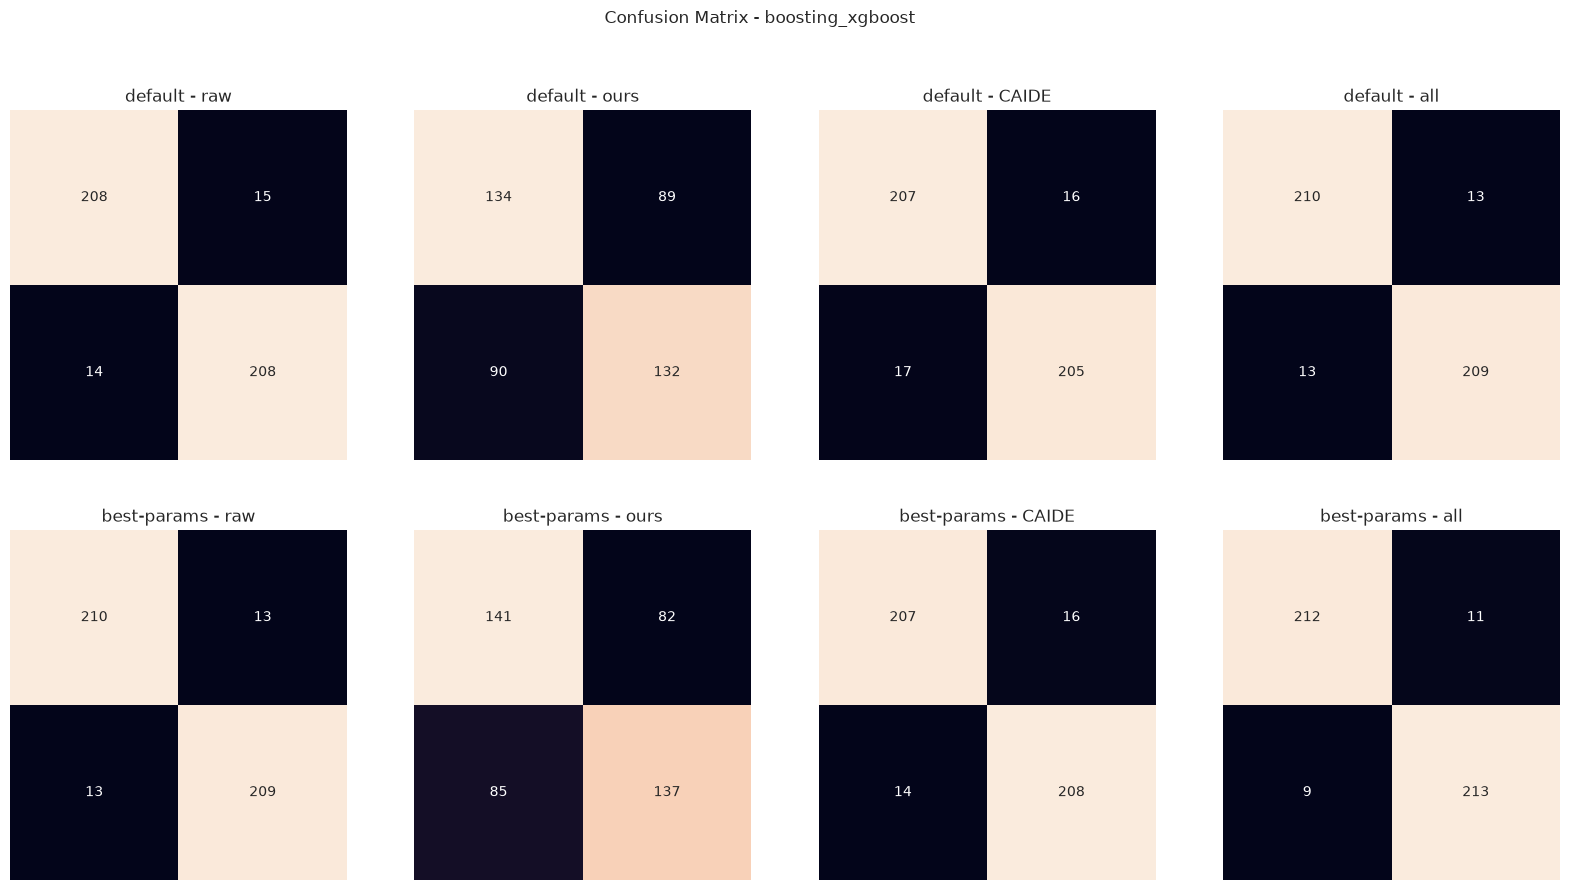

In [15]:
confusion_matrix_plot('boosting_xgboost')

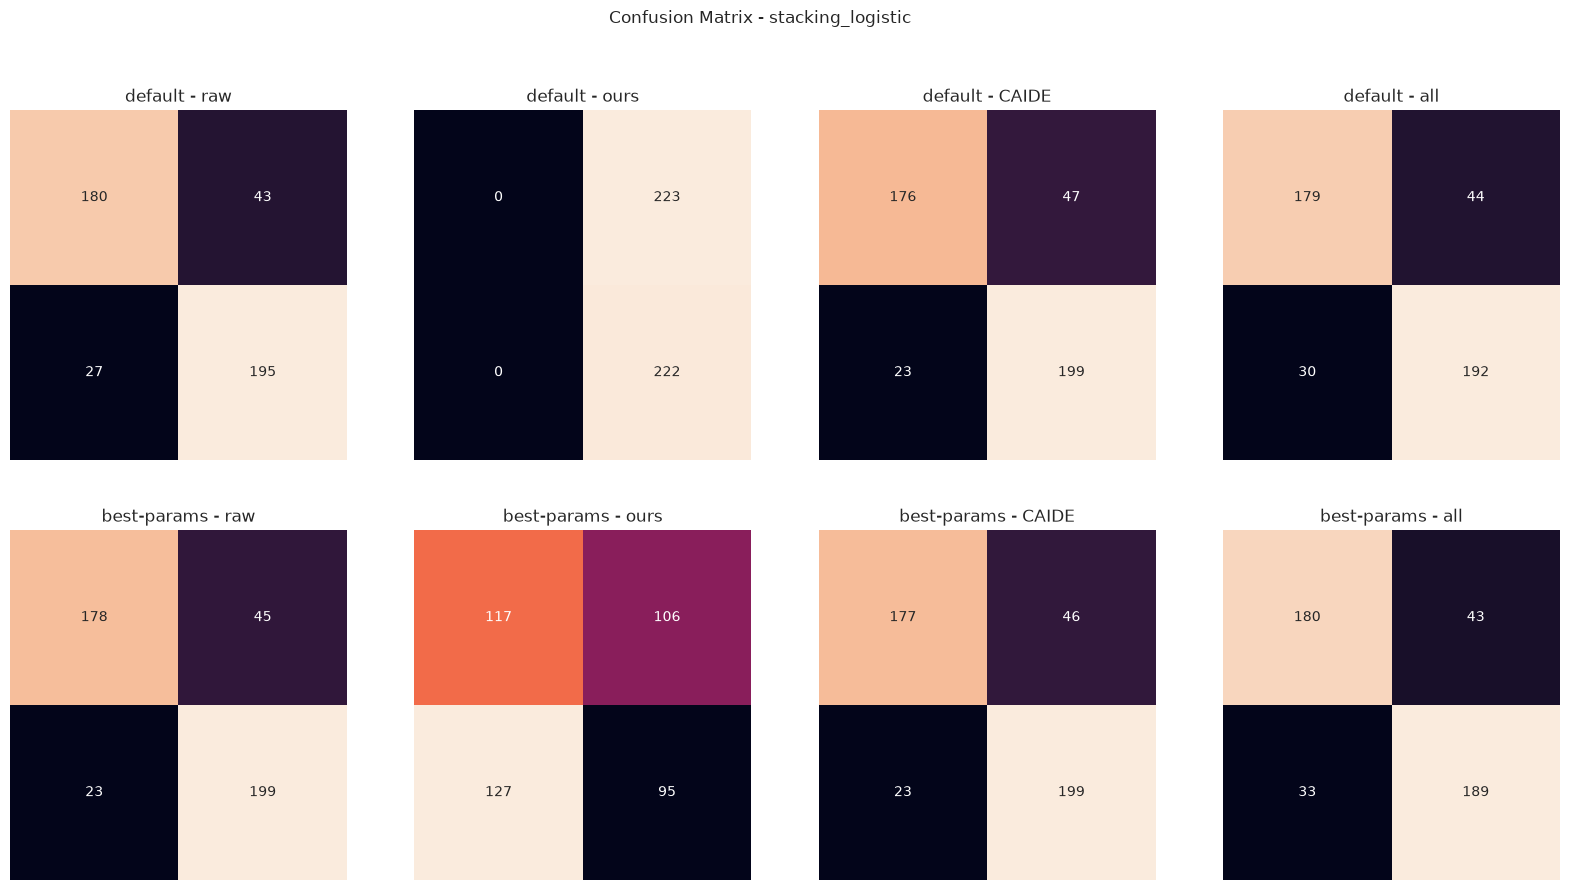

In [16]:
confusion_matrix_plot('stacking_logistic')

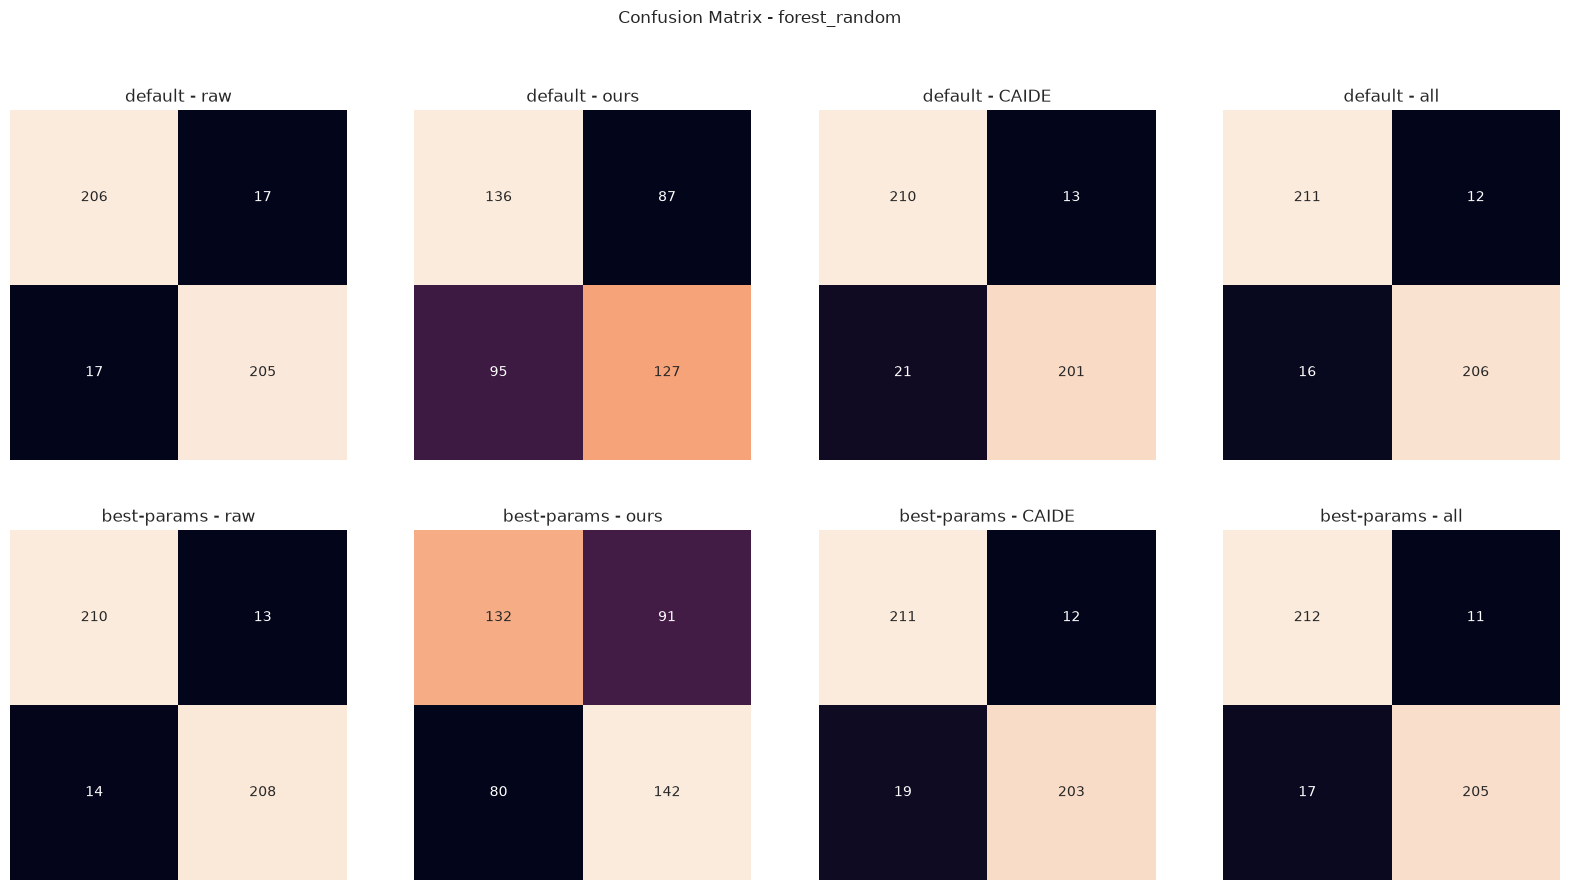

In [17]:
confusion_matrix_plot('forest_random')

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/default/raw/boosting_xgboost/shap_plot.png


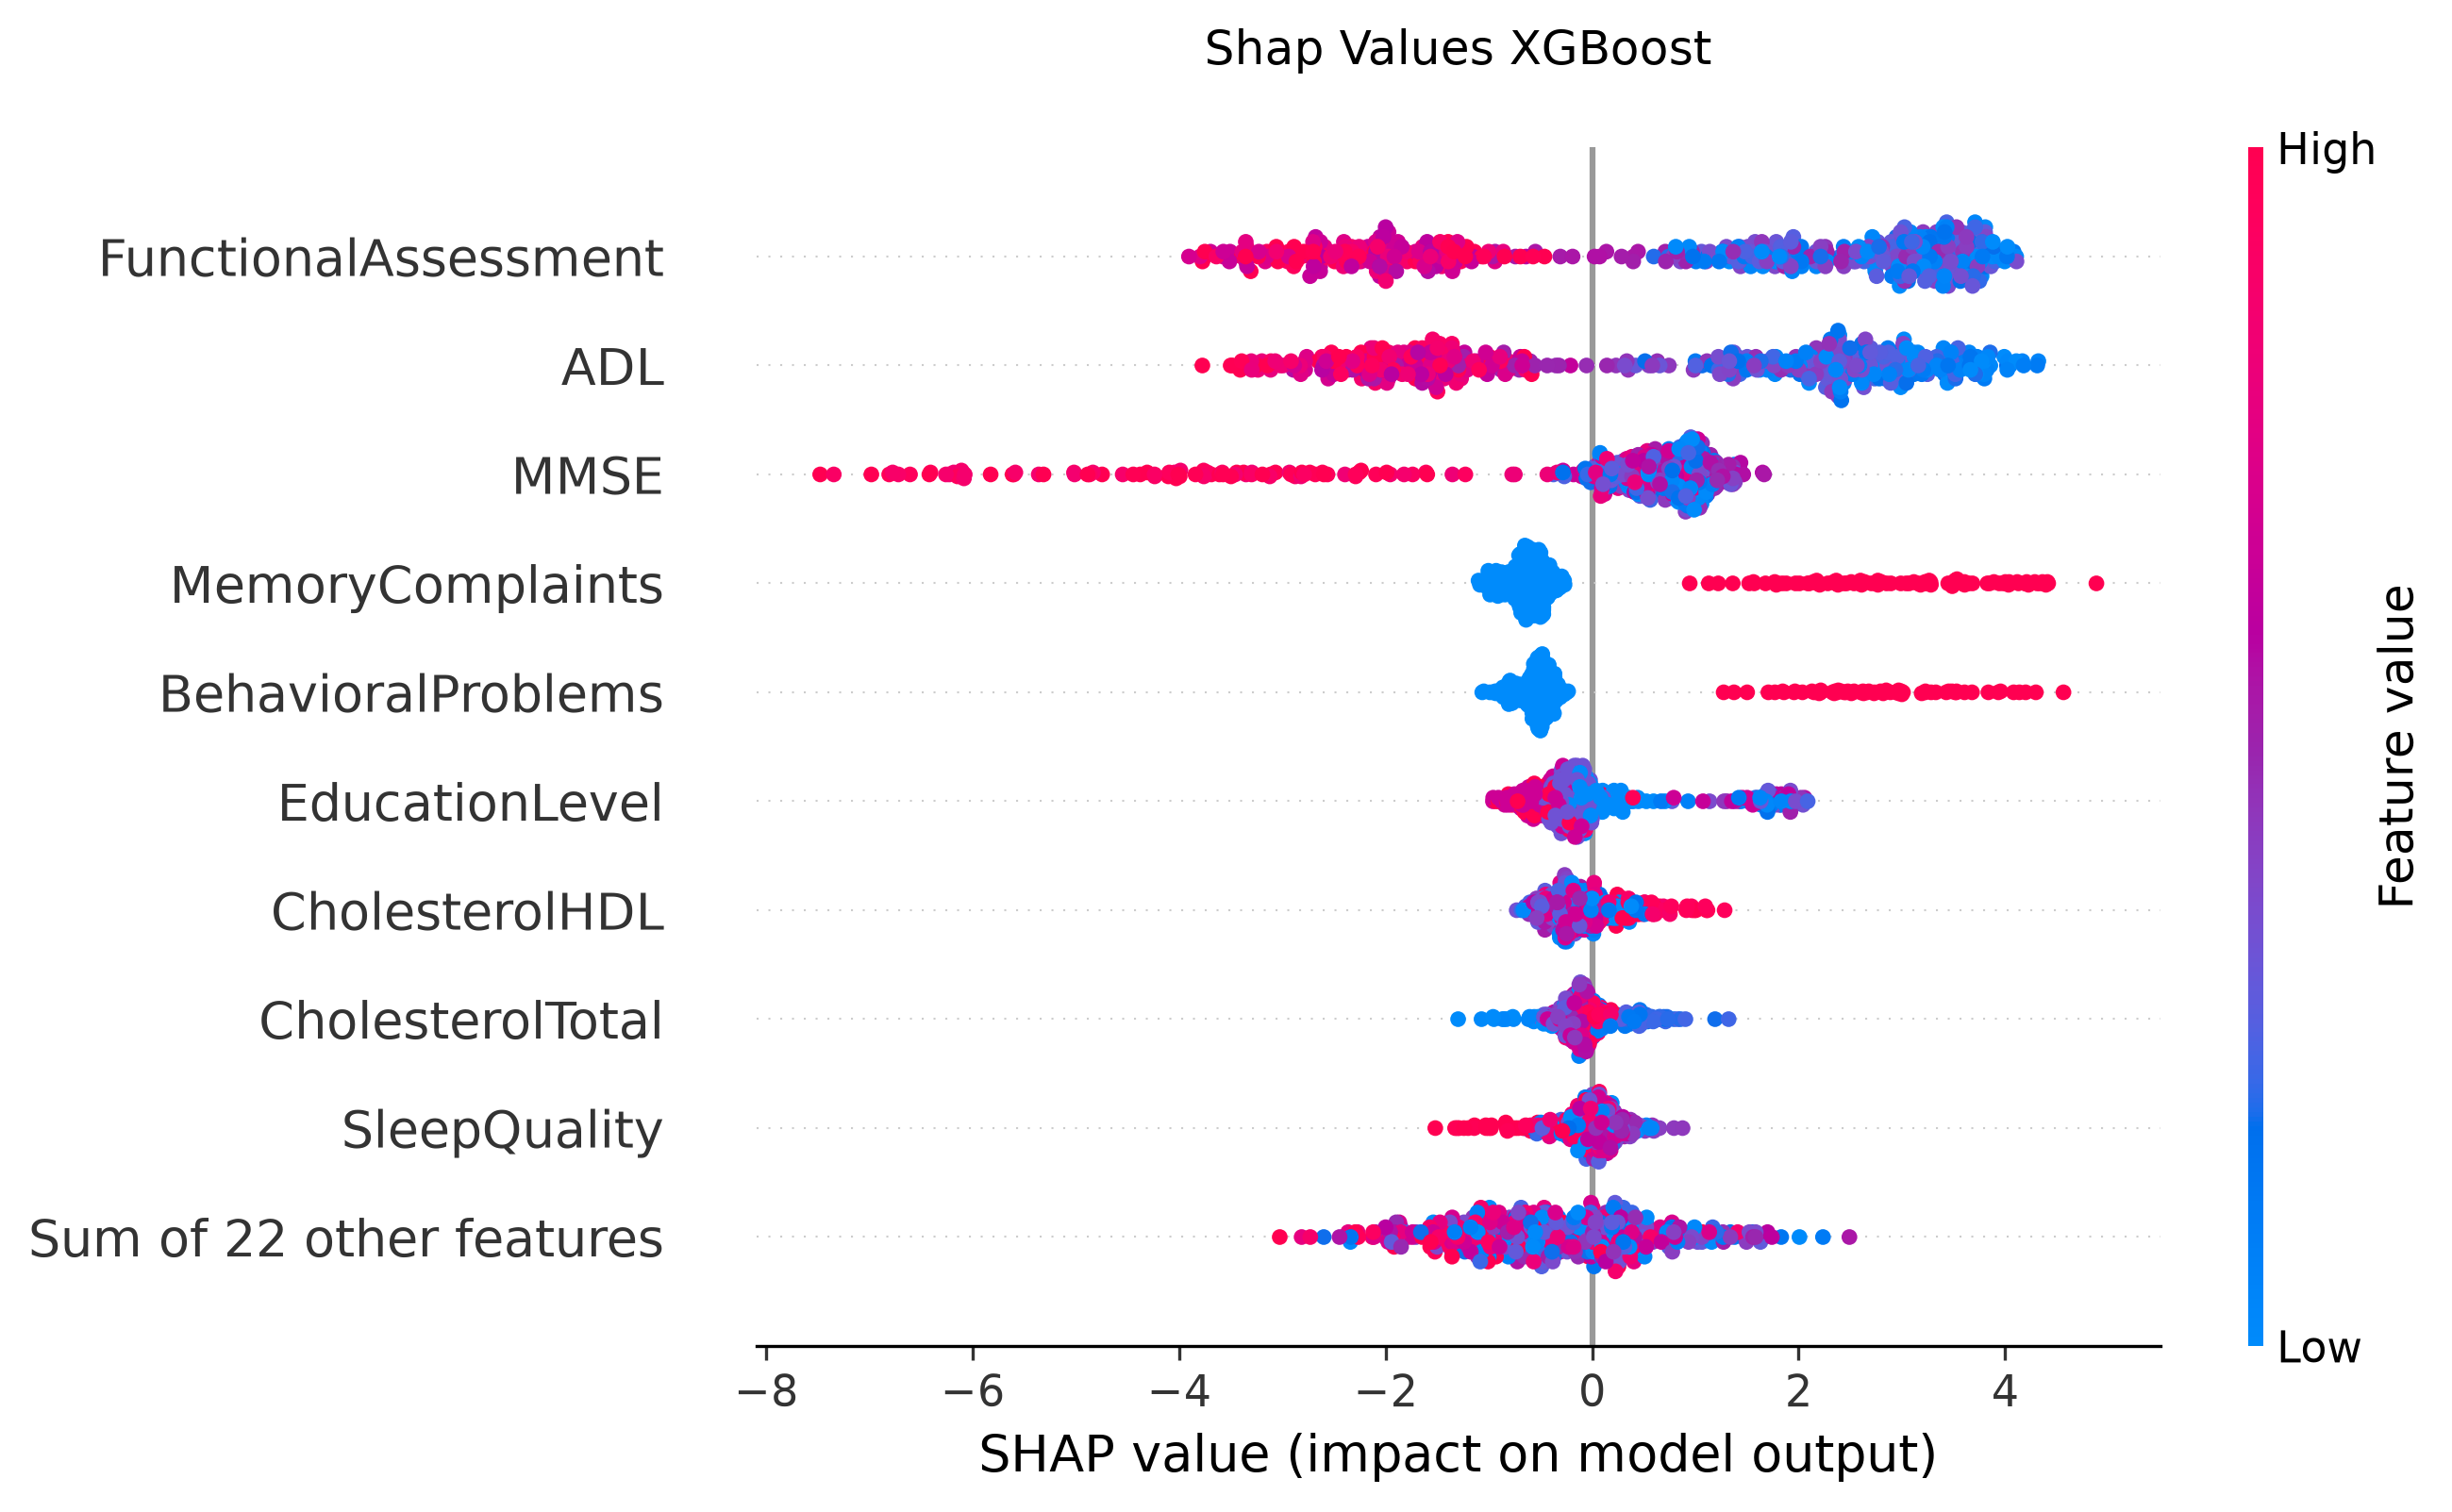

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/default/raw/boosting_xgboost/shap_plot.png


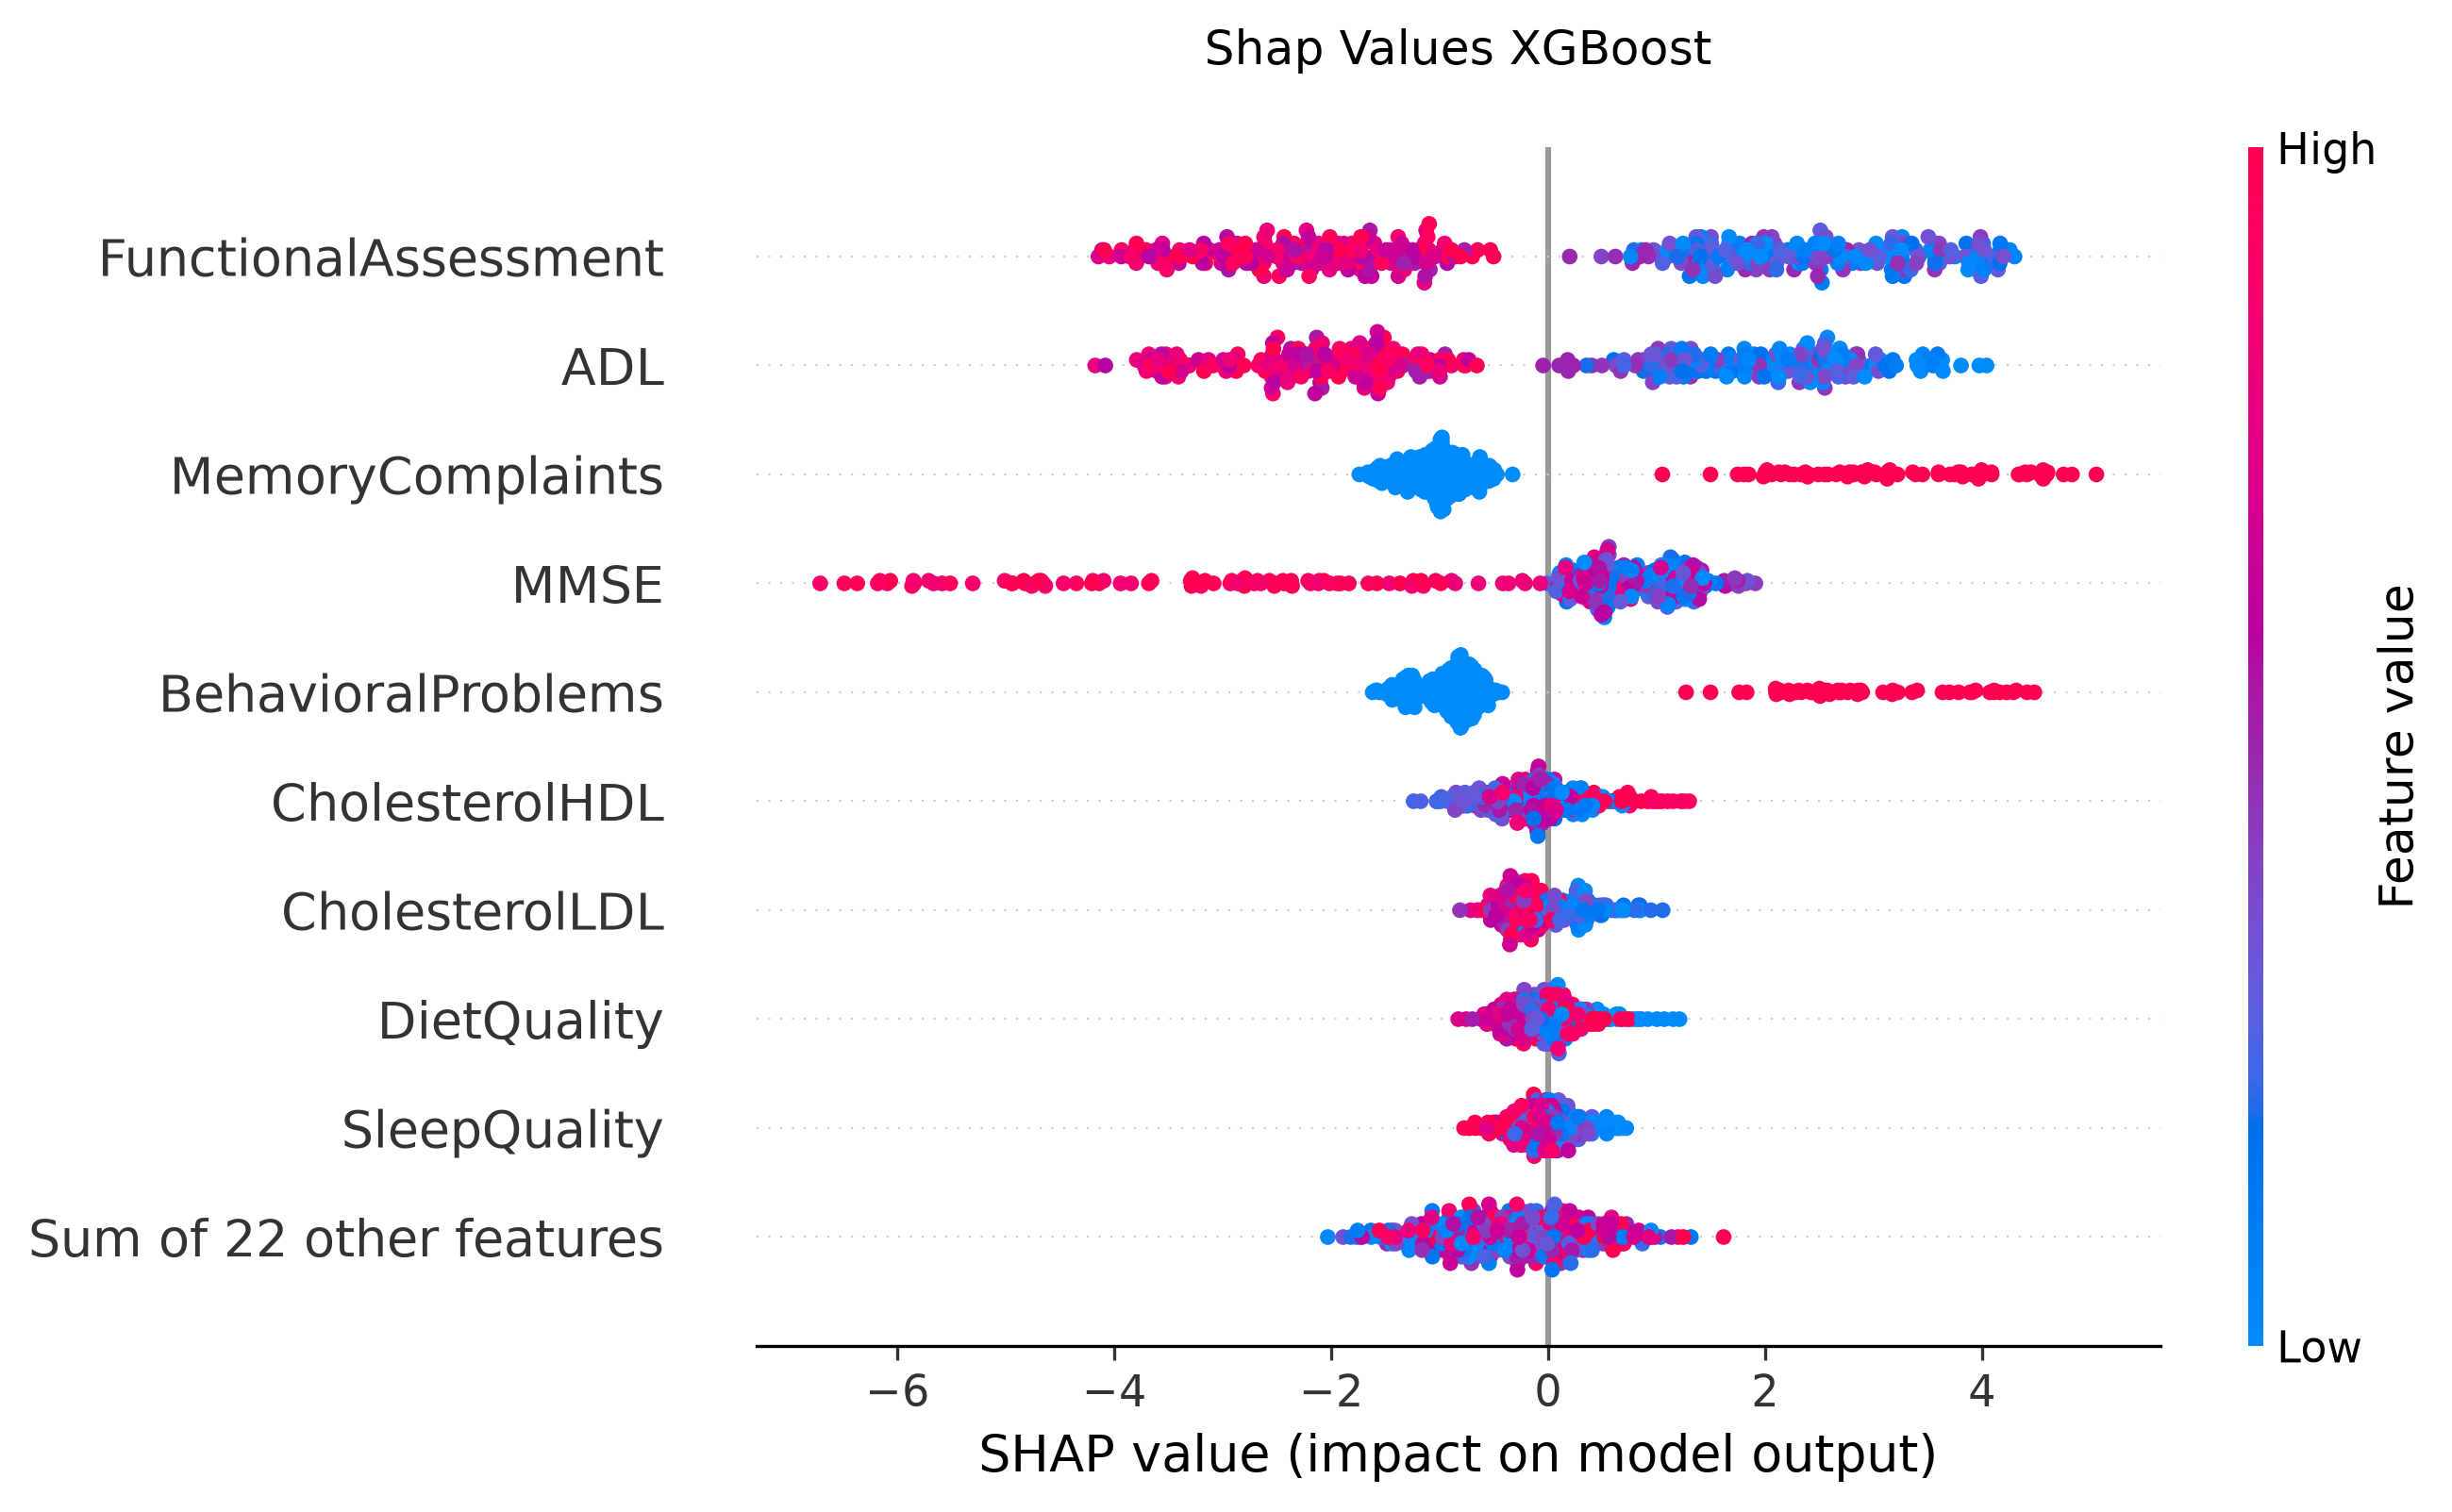

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/best-params/raw/boosting_xgboost/shap_plot.png


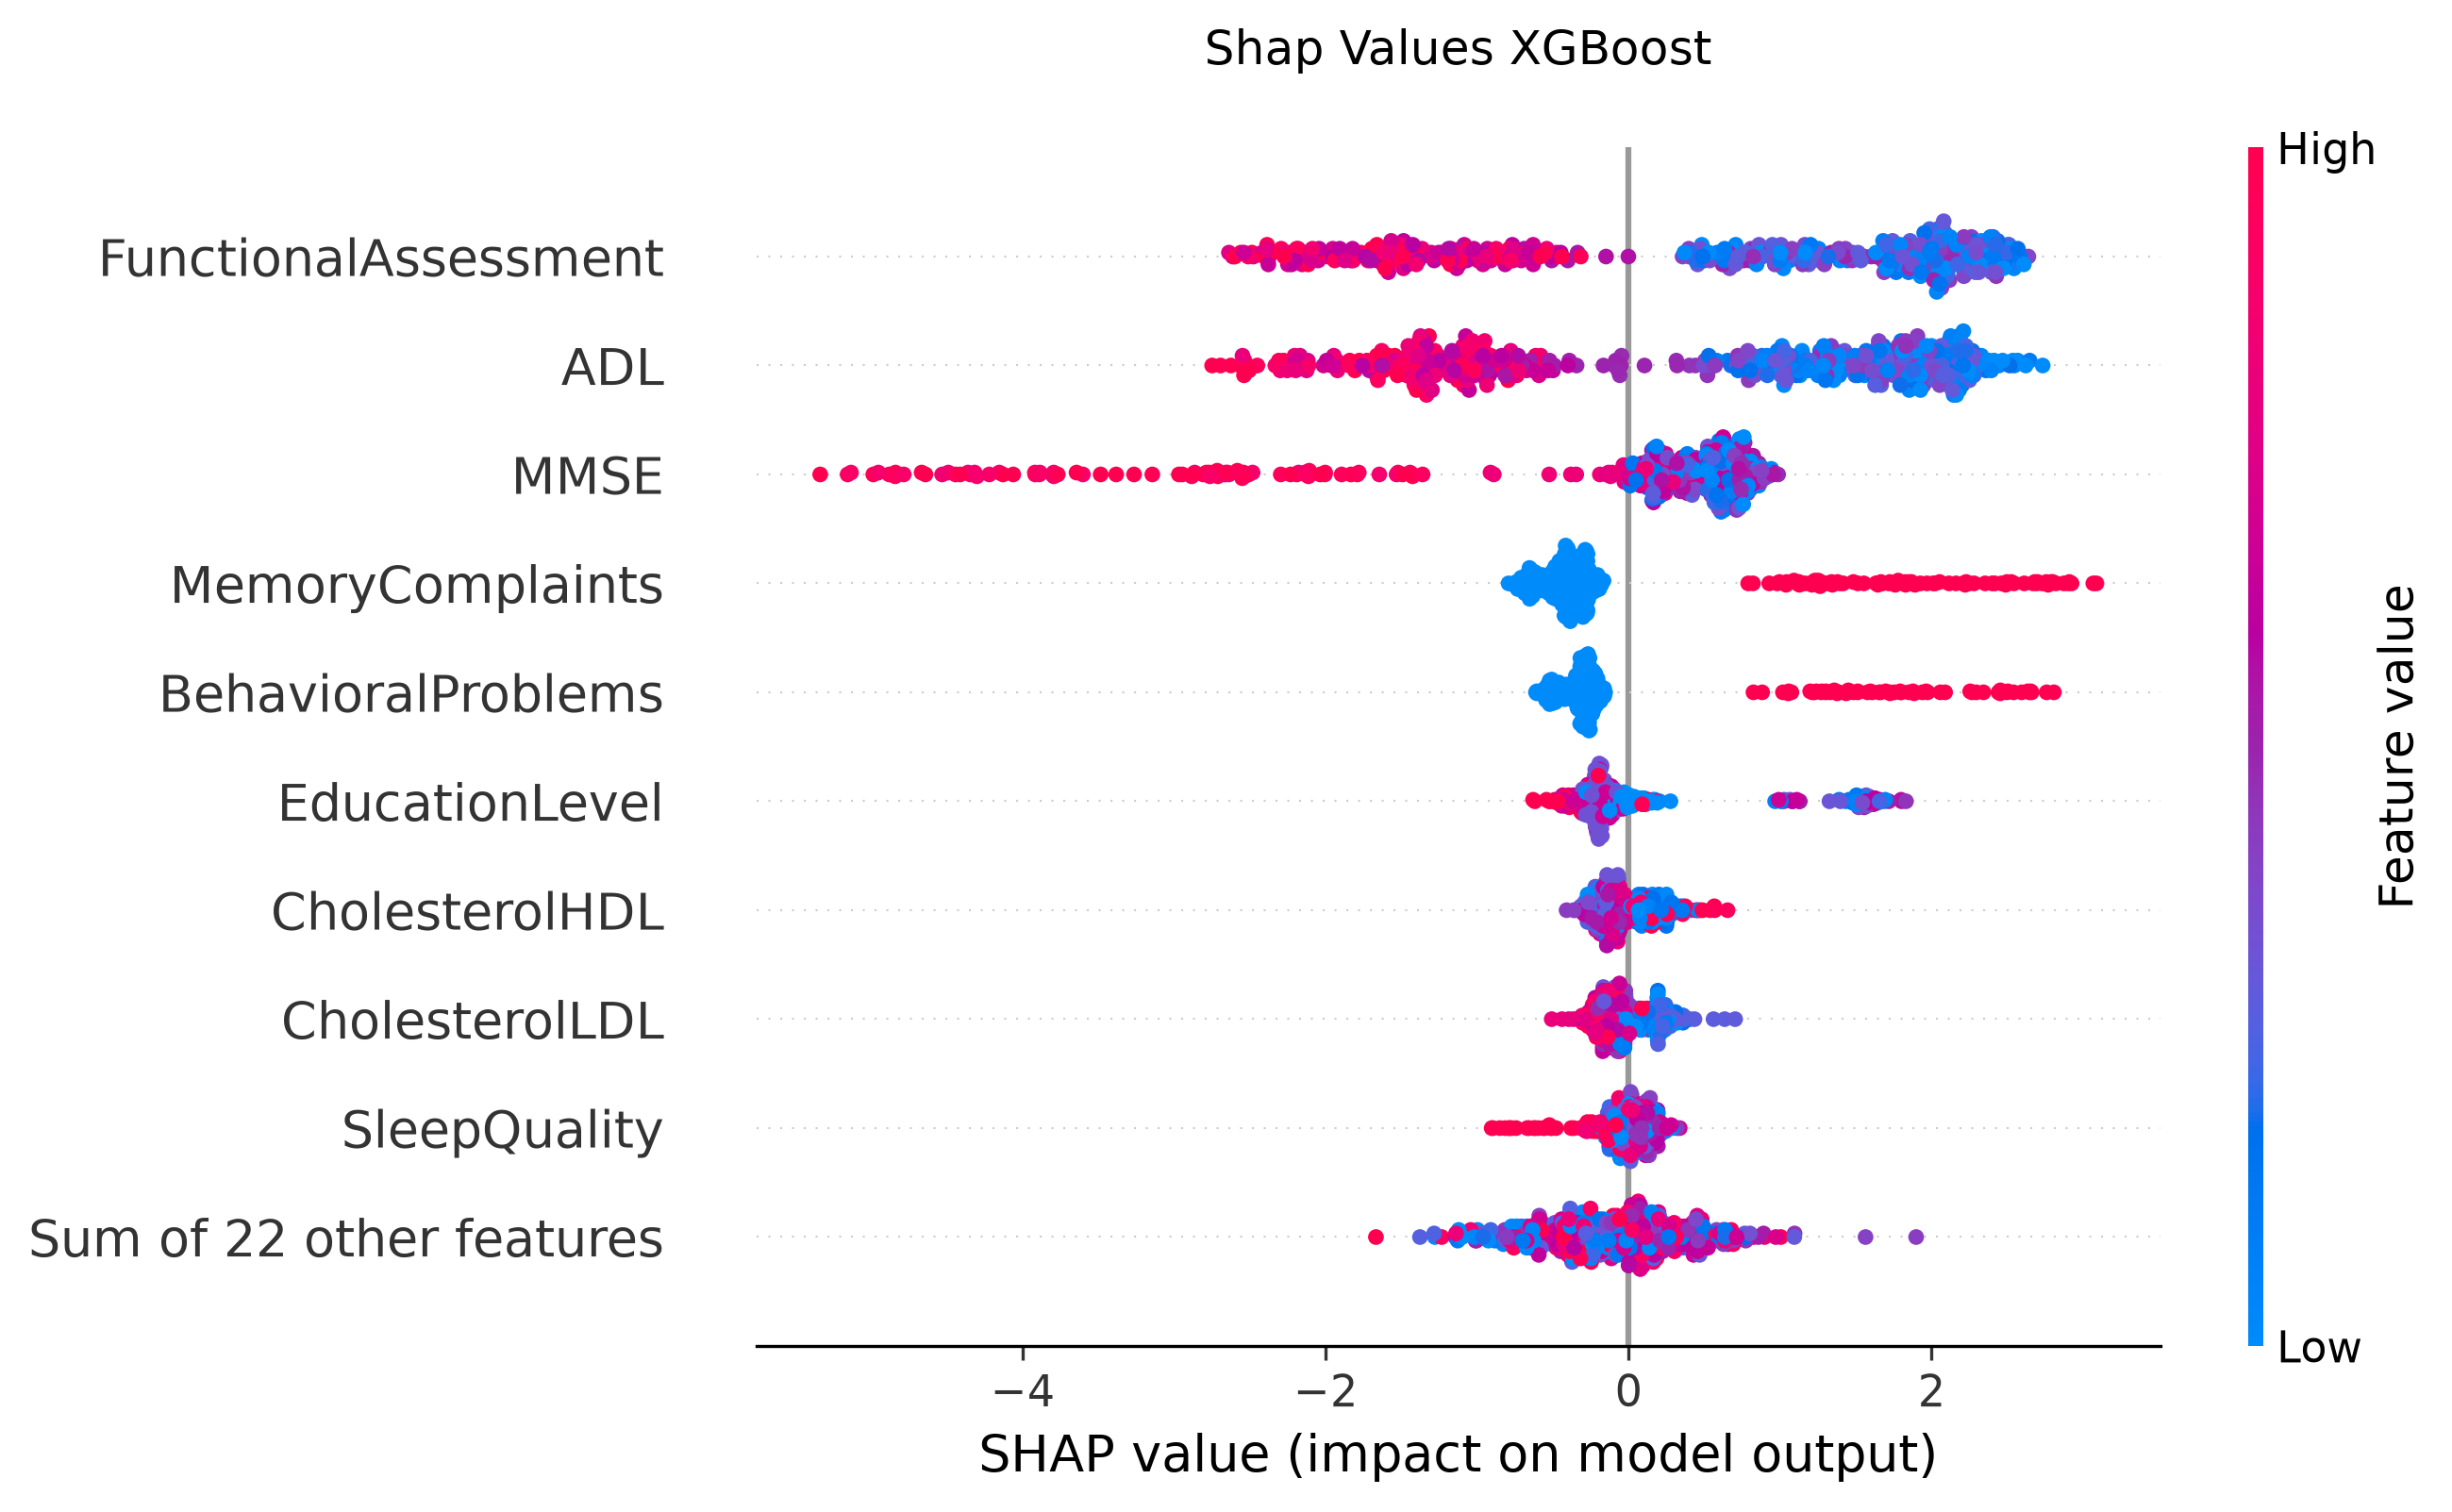

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/best-params/raw/boosting_xgboost/shap_plot.png


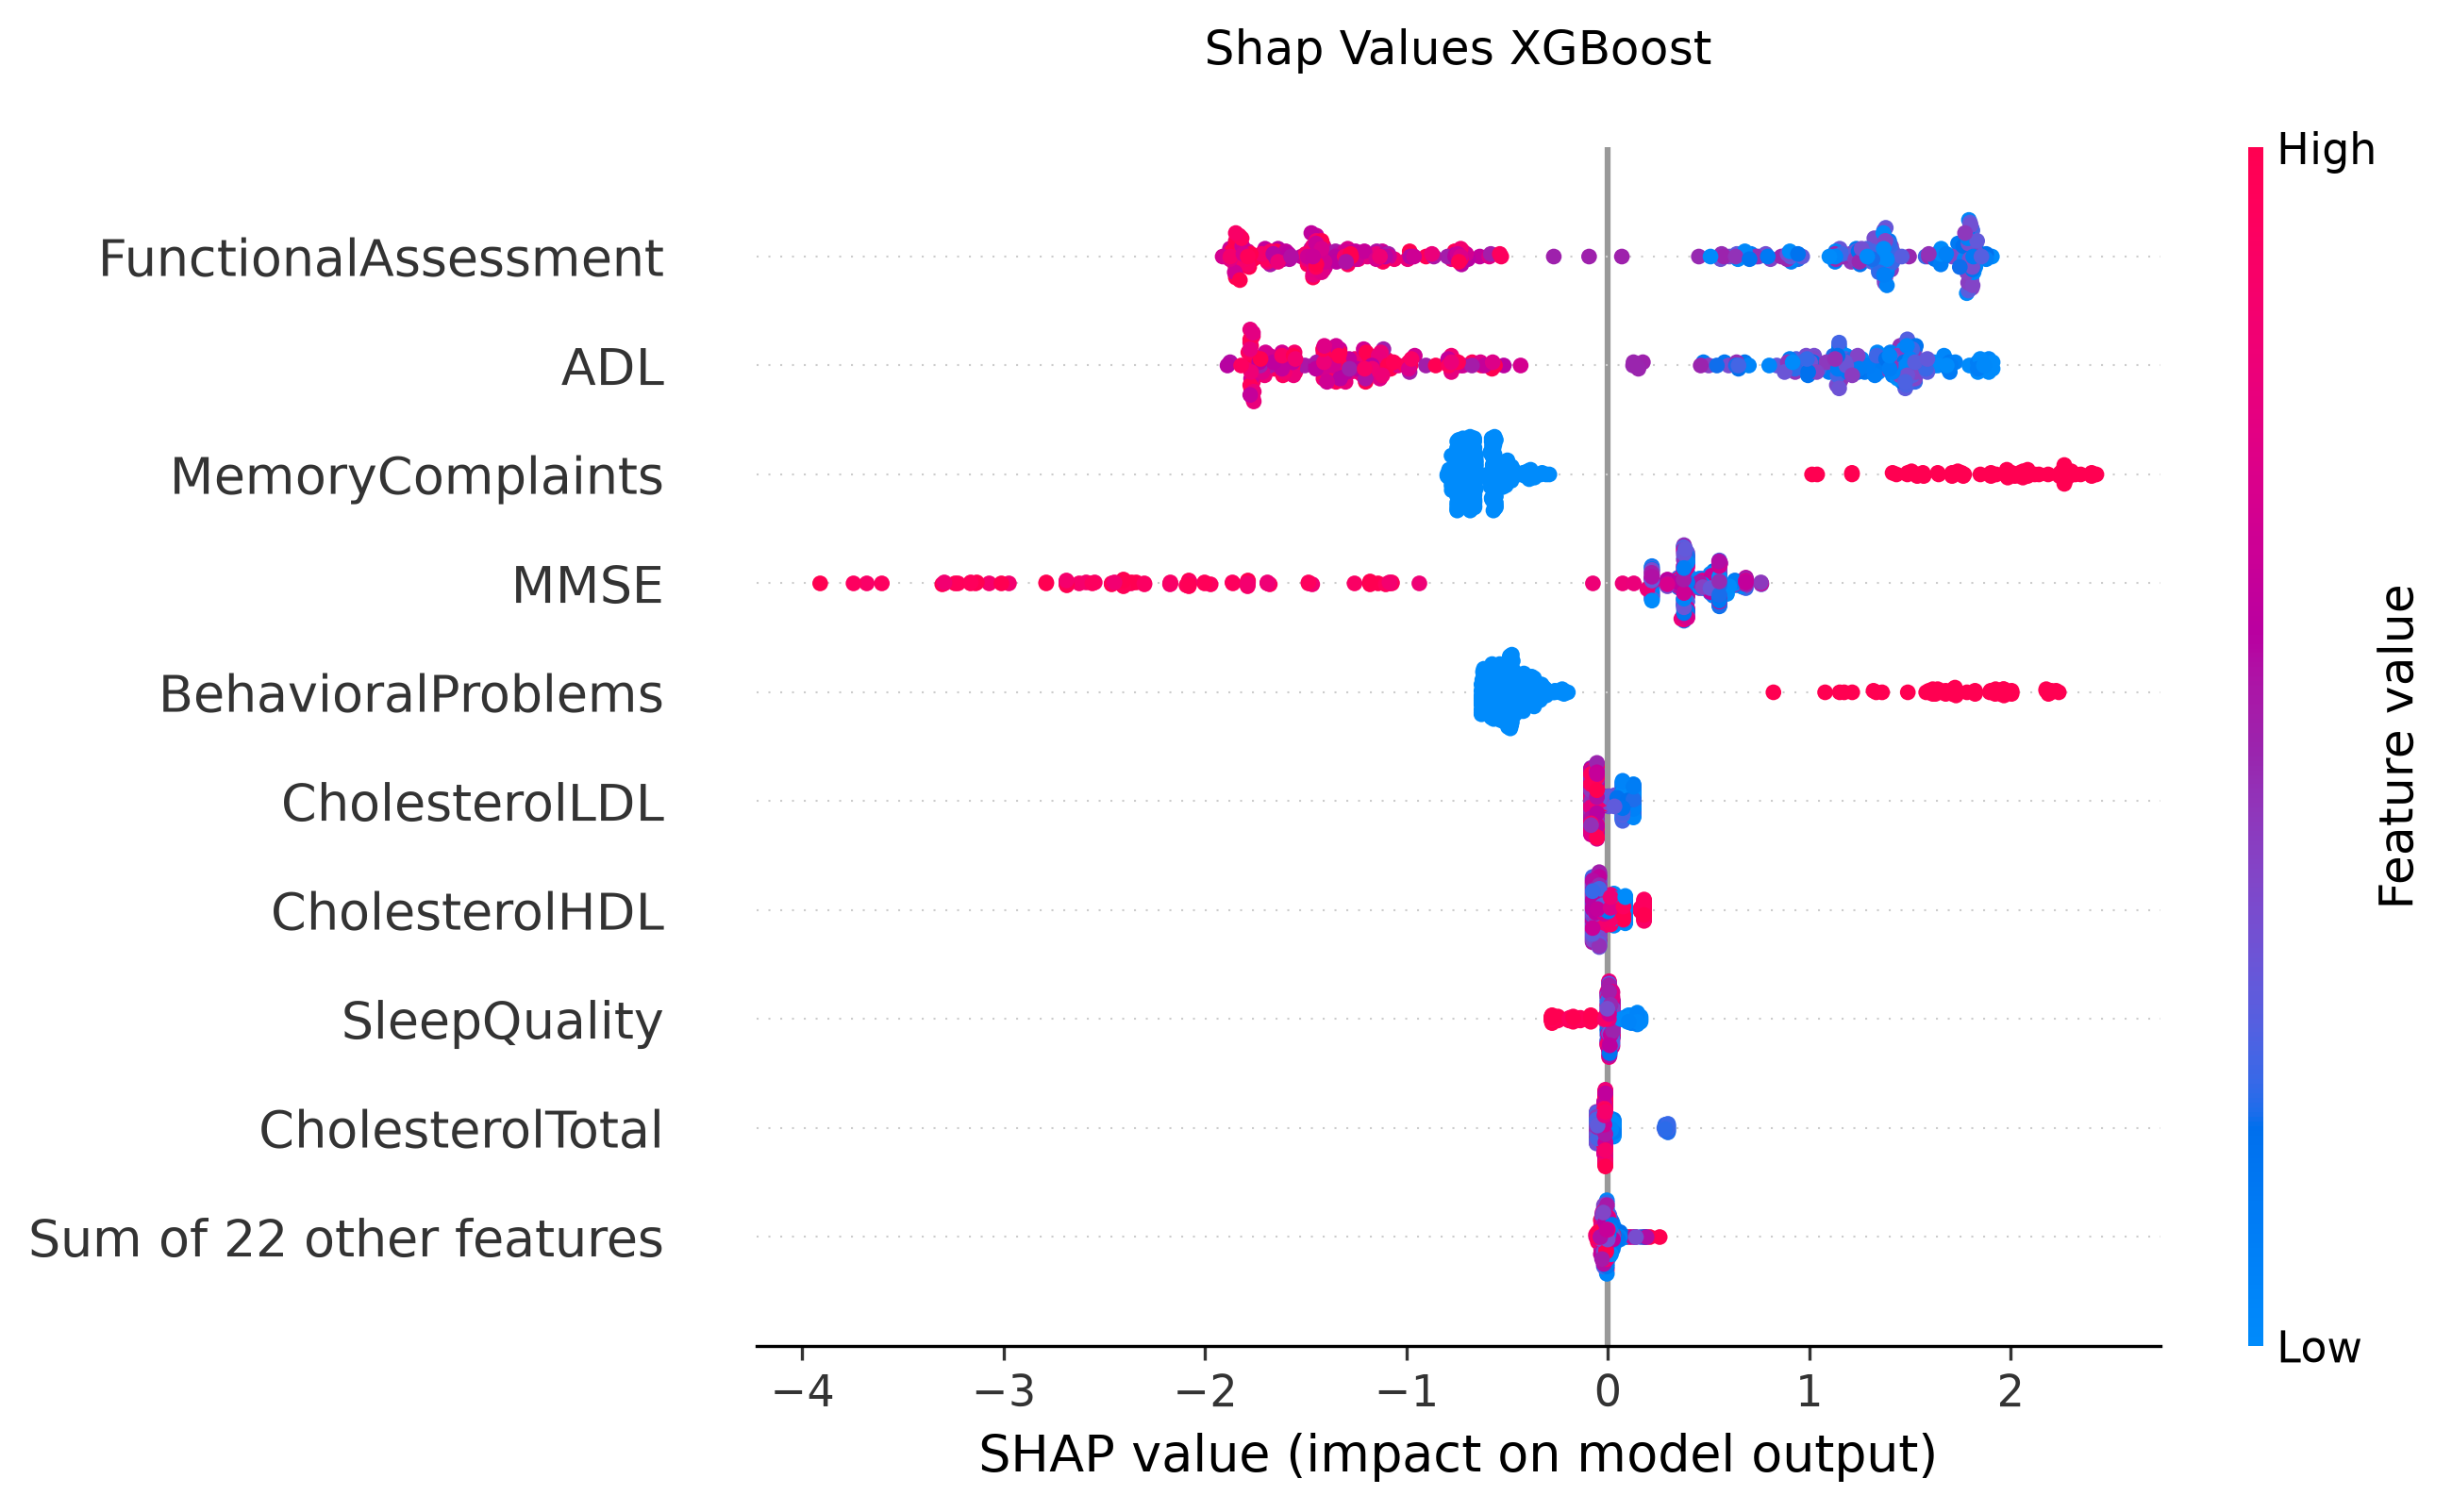

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/default/ours/boosting_xgboost/shap_plot.png


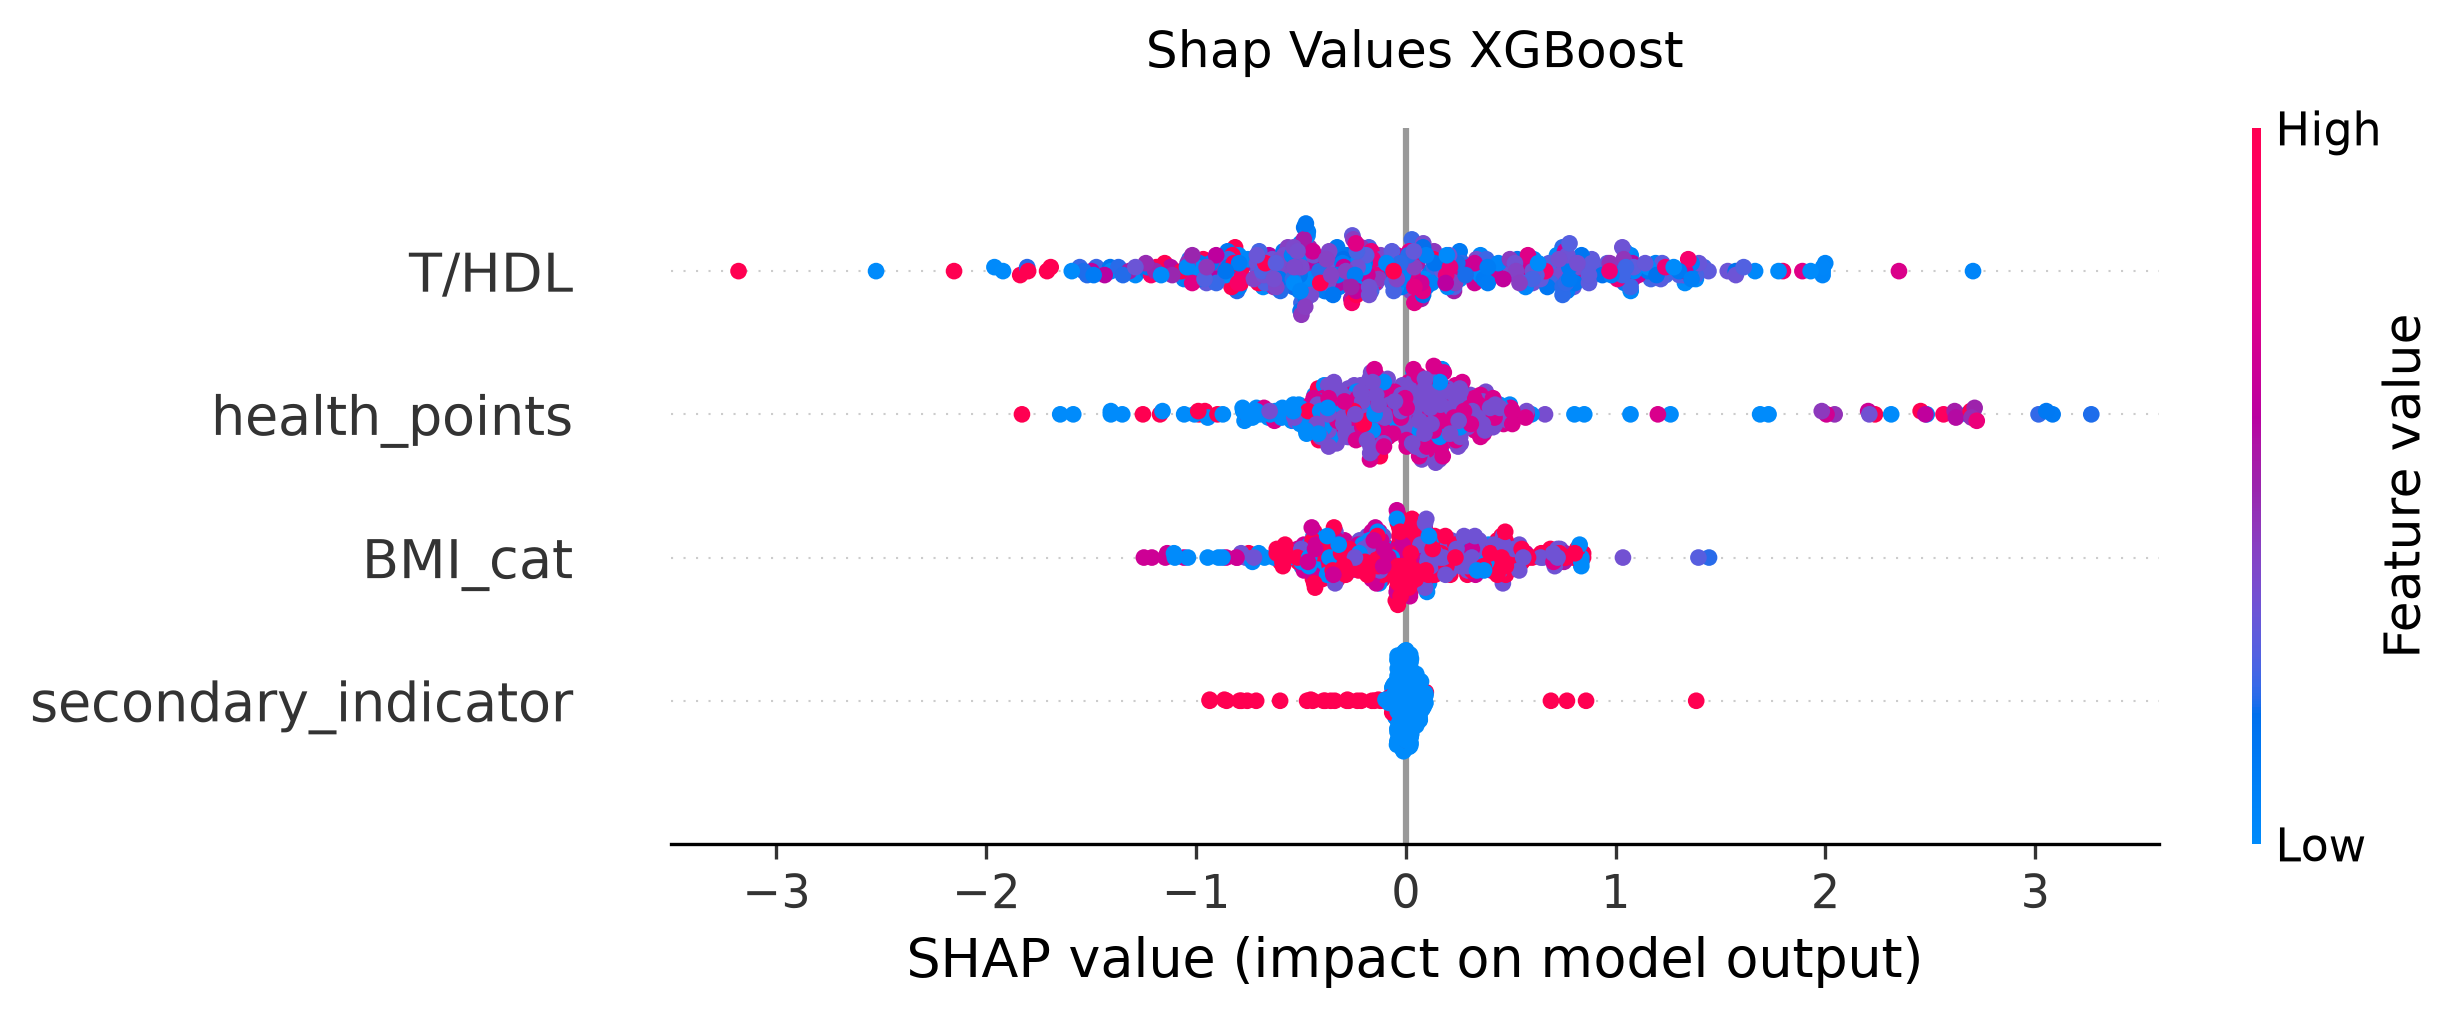

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/default/ours/boosting_xgboost/shap_plot.png


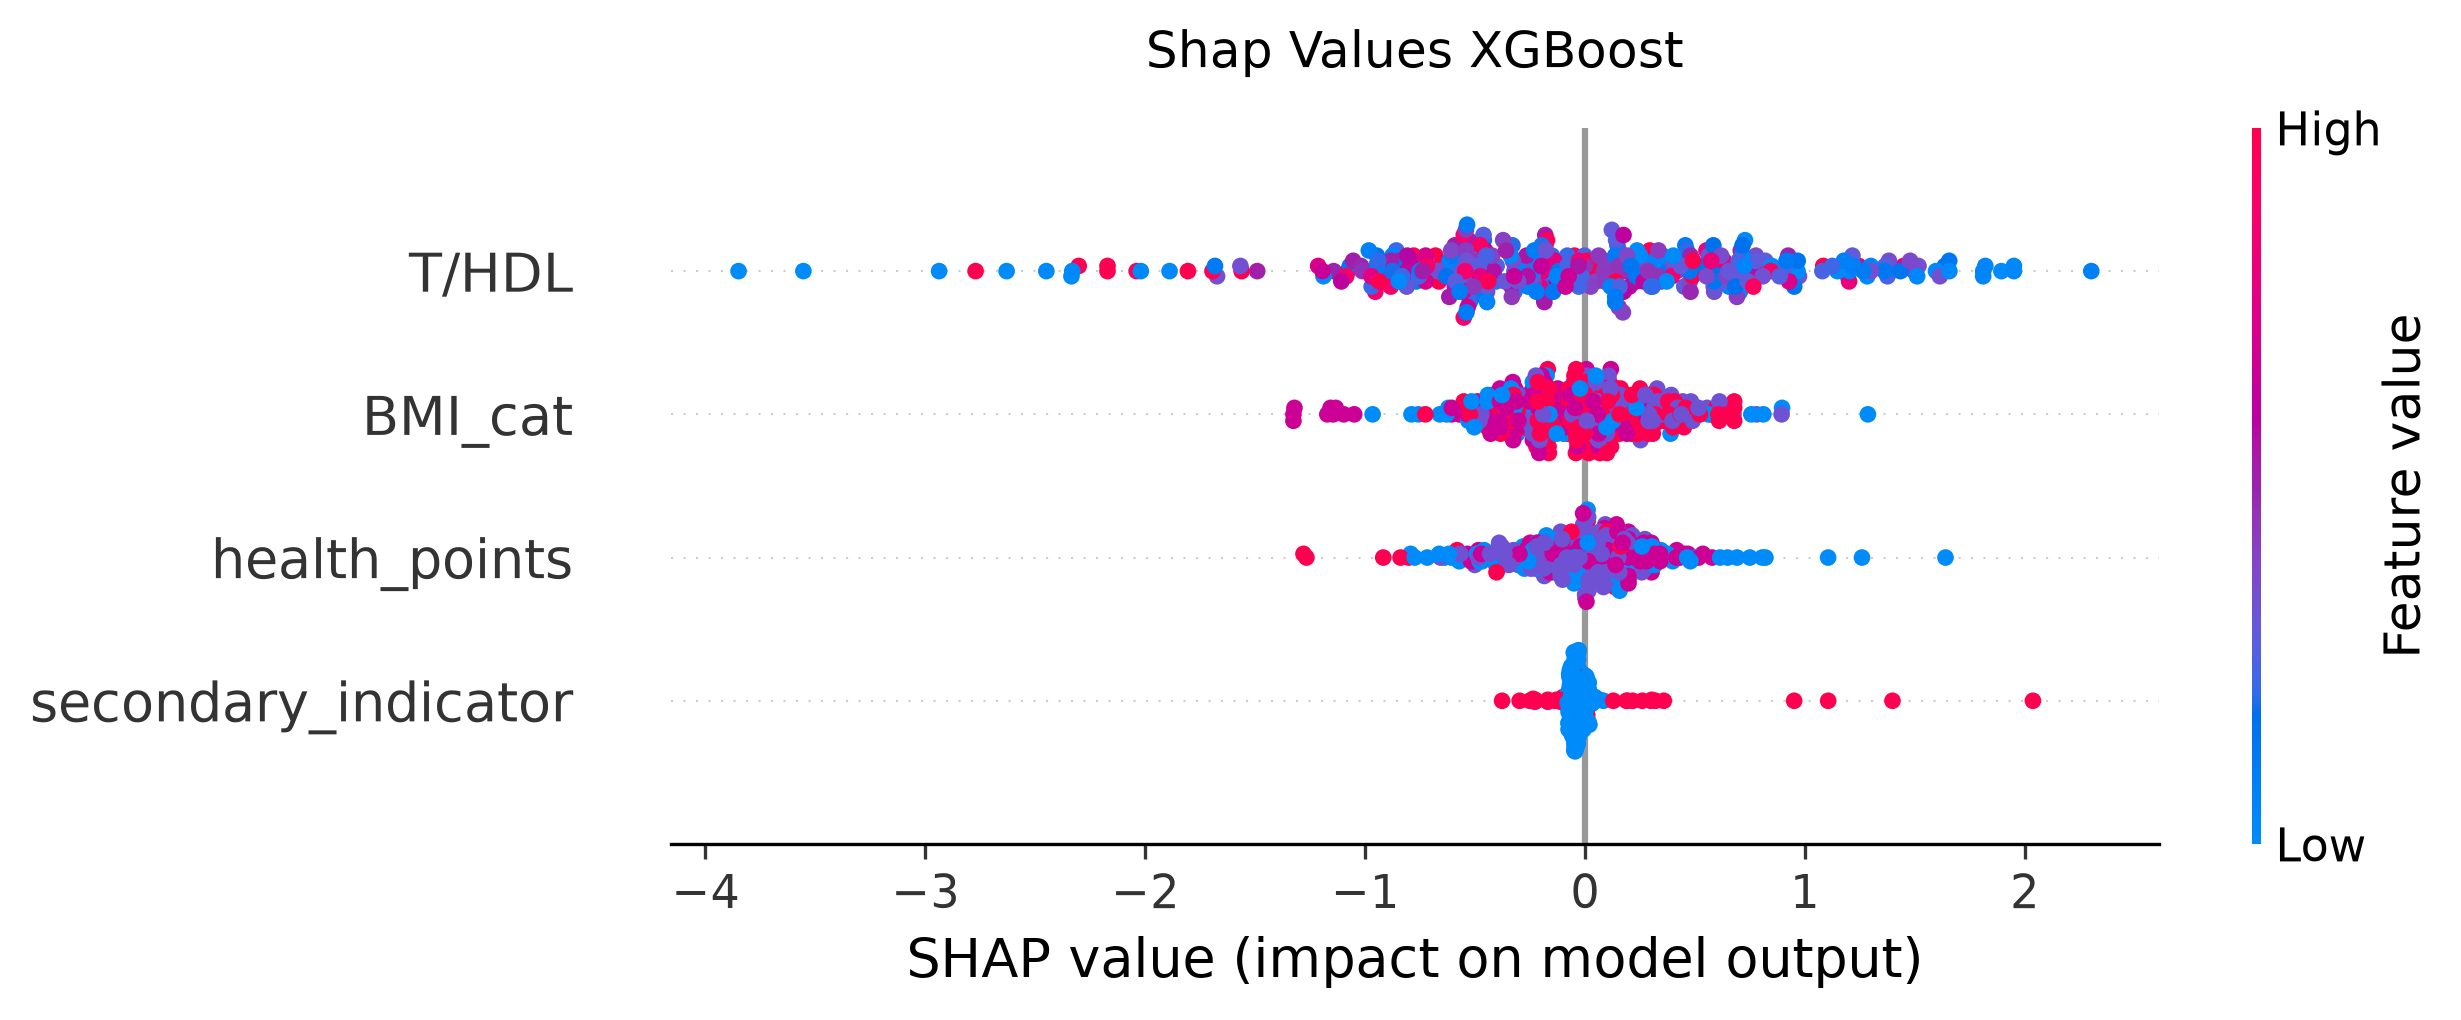

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/best-params/ours/boosting_xgboost/shap_plot.png


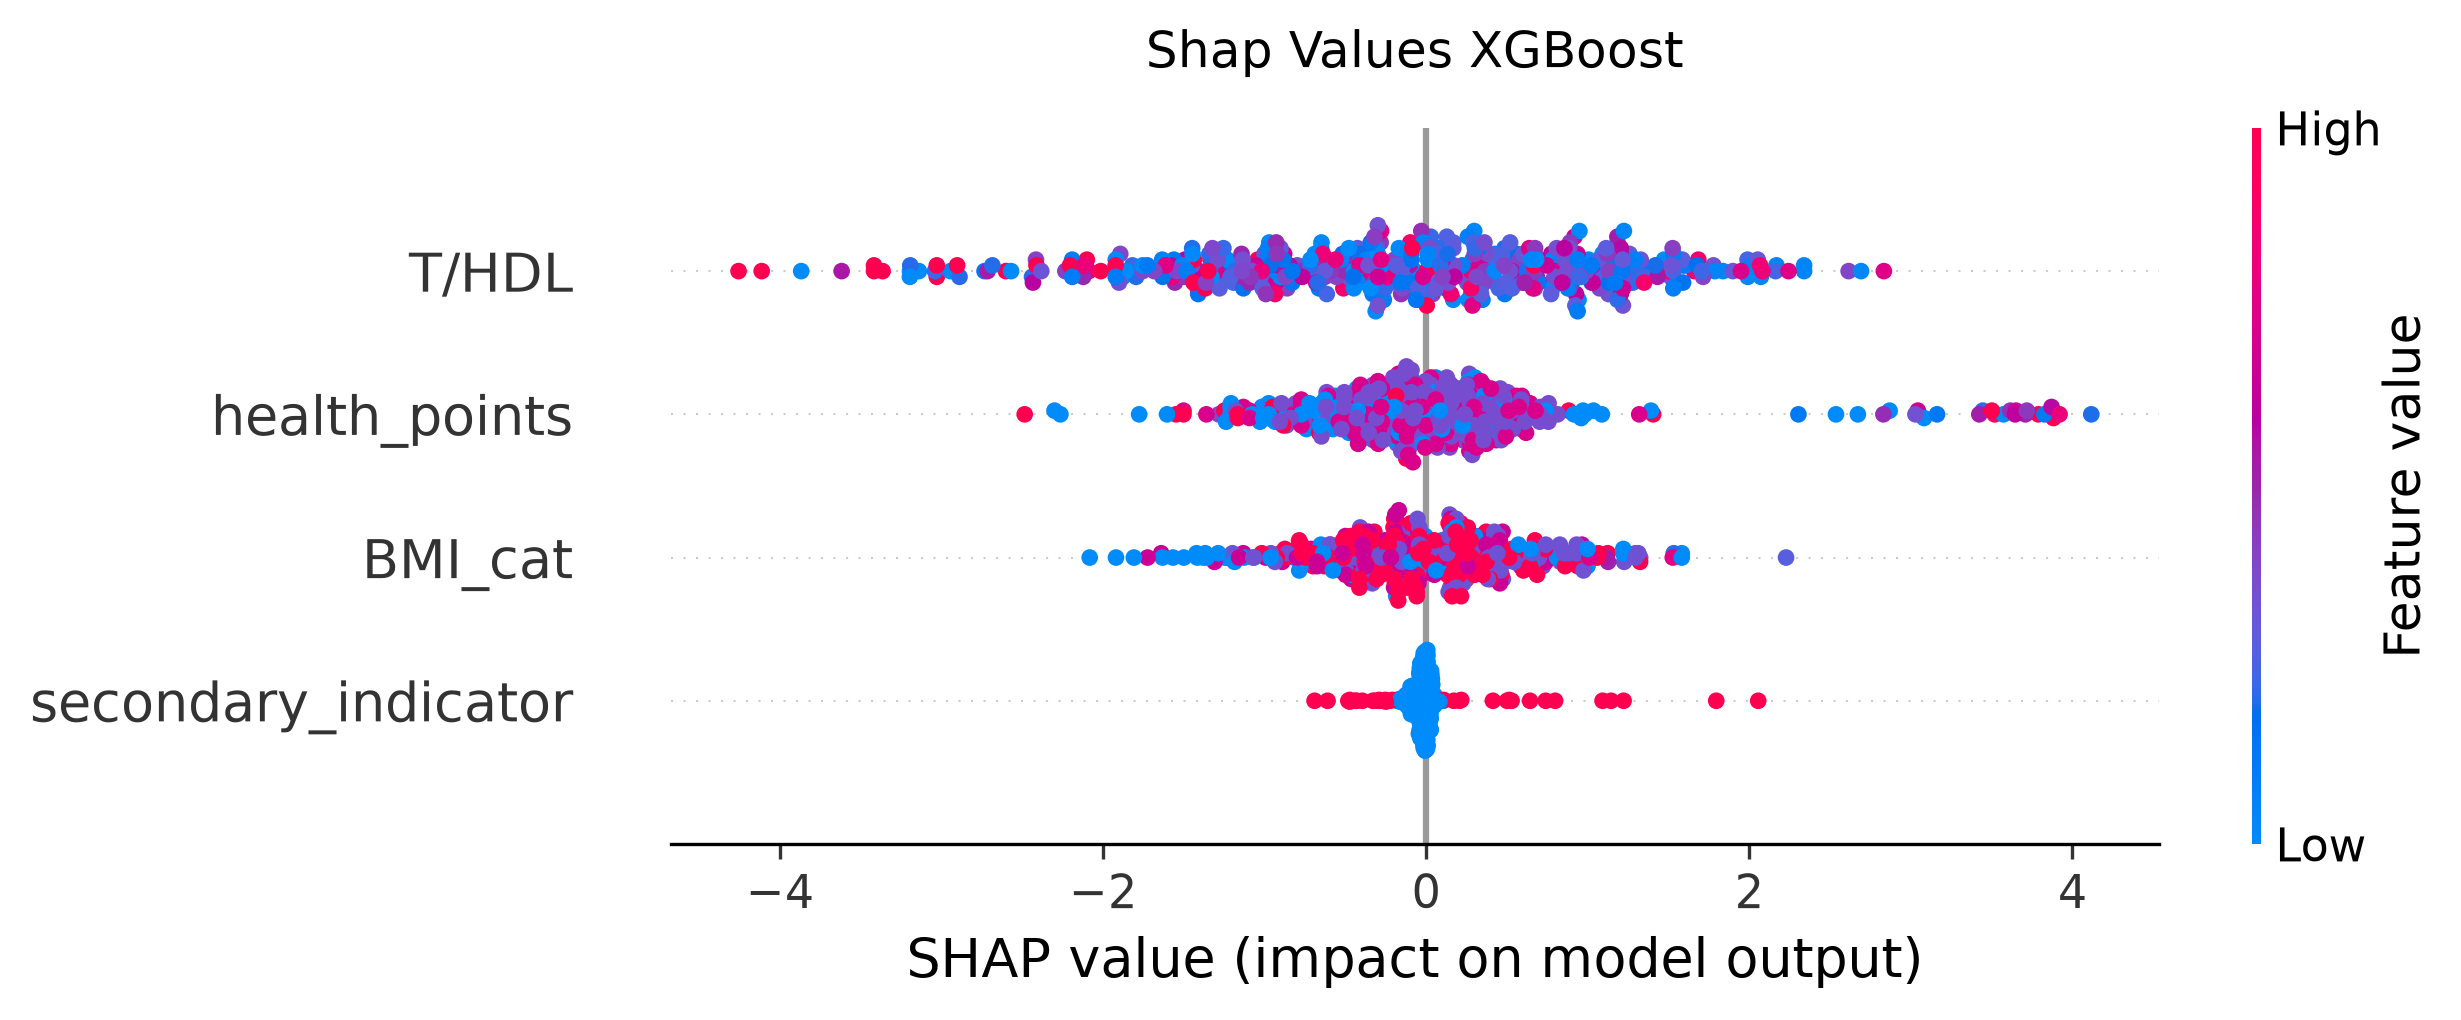

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/best-params/ours/boosting_xgboost/shap_plot.png


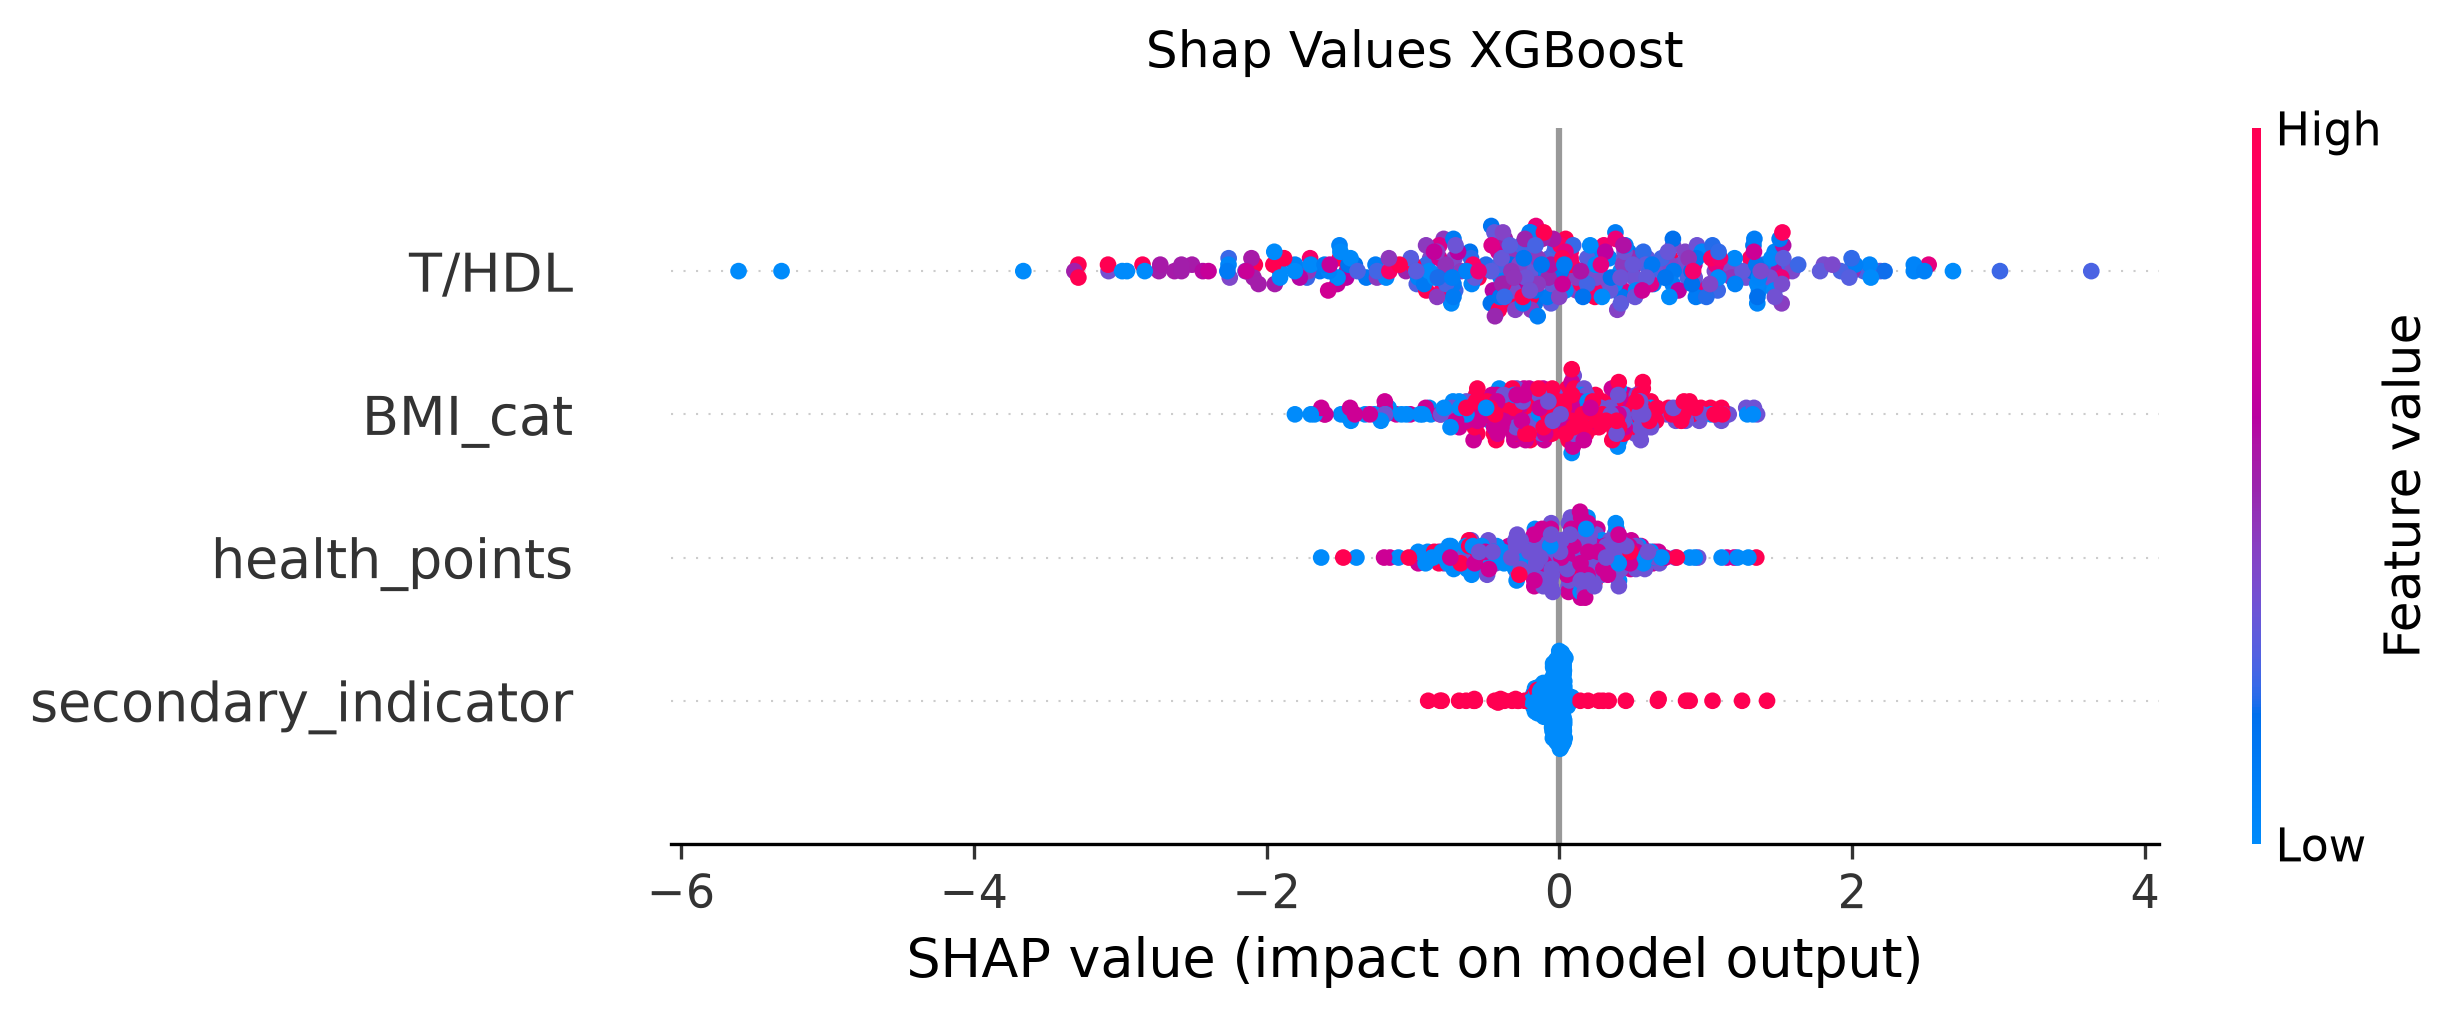

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/default/CAIDE/boosting_xgboost/shap_plot.png


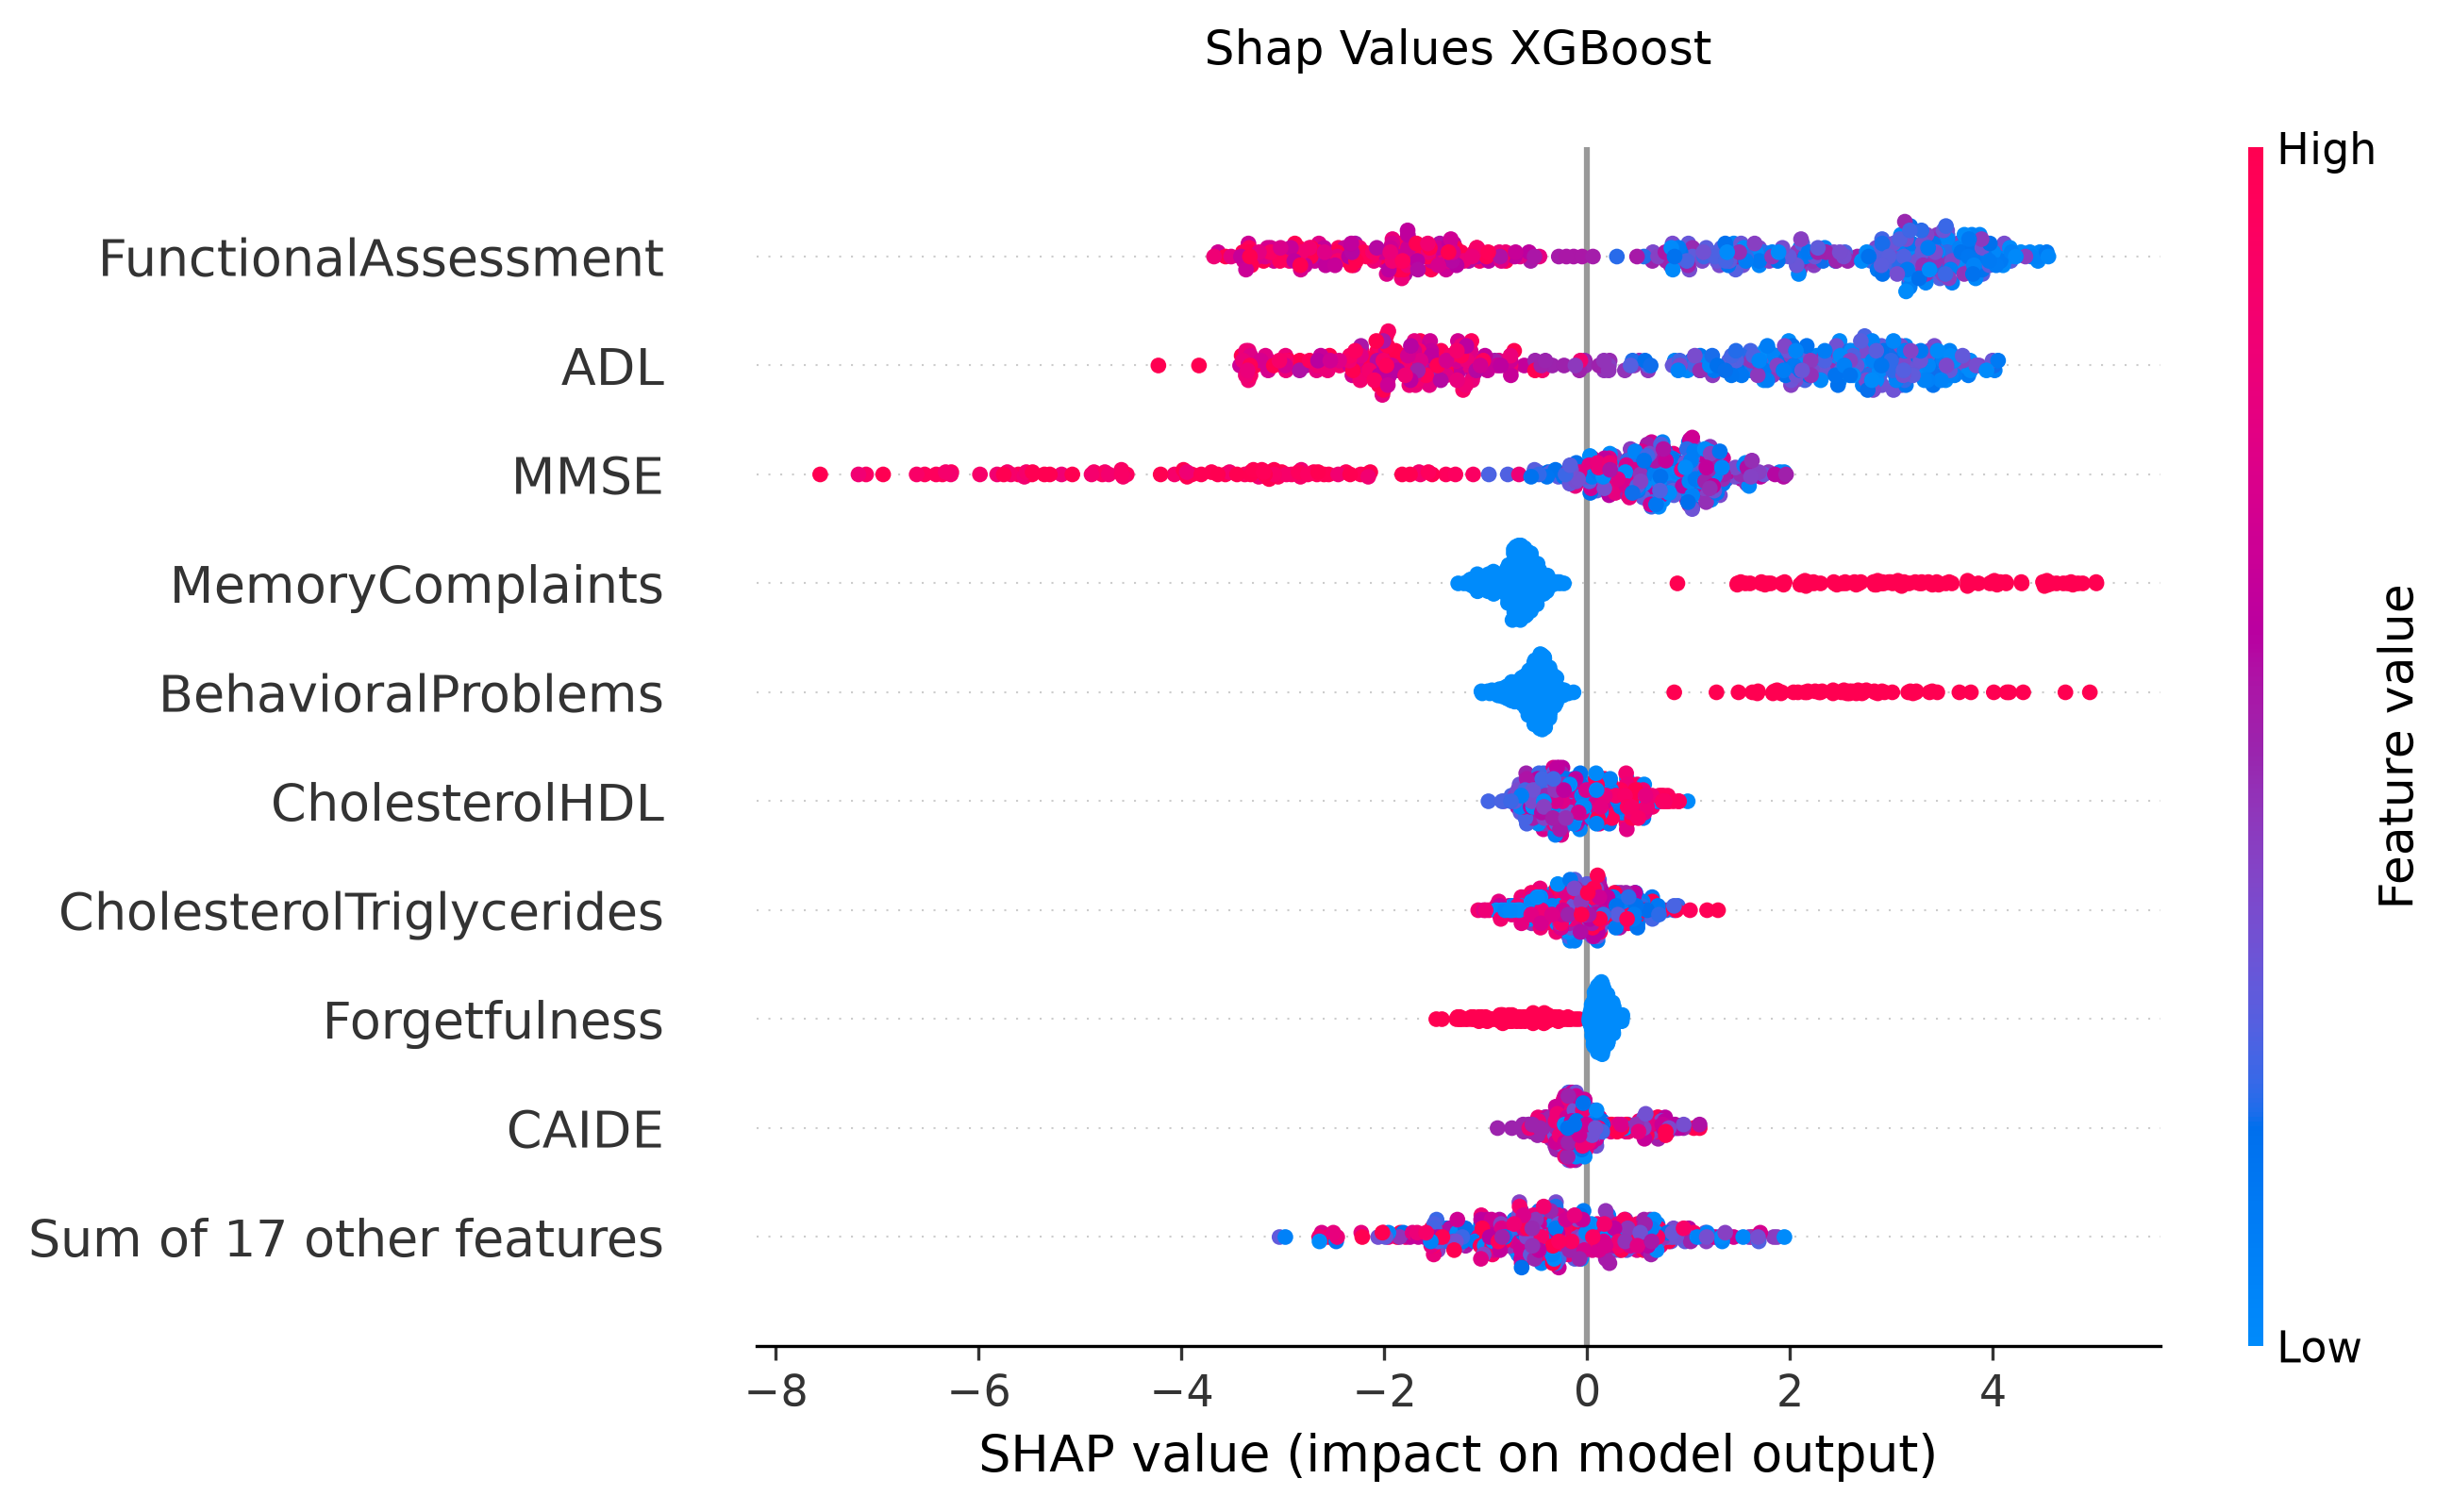

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/default/CAIDE/boosting_xgboost/shap_plot.png


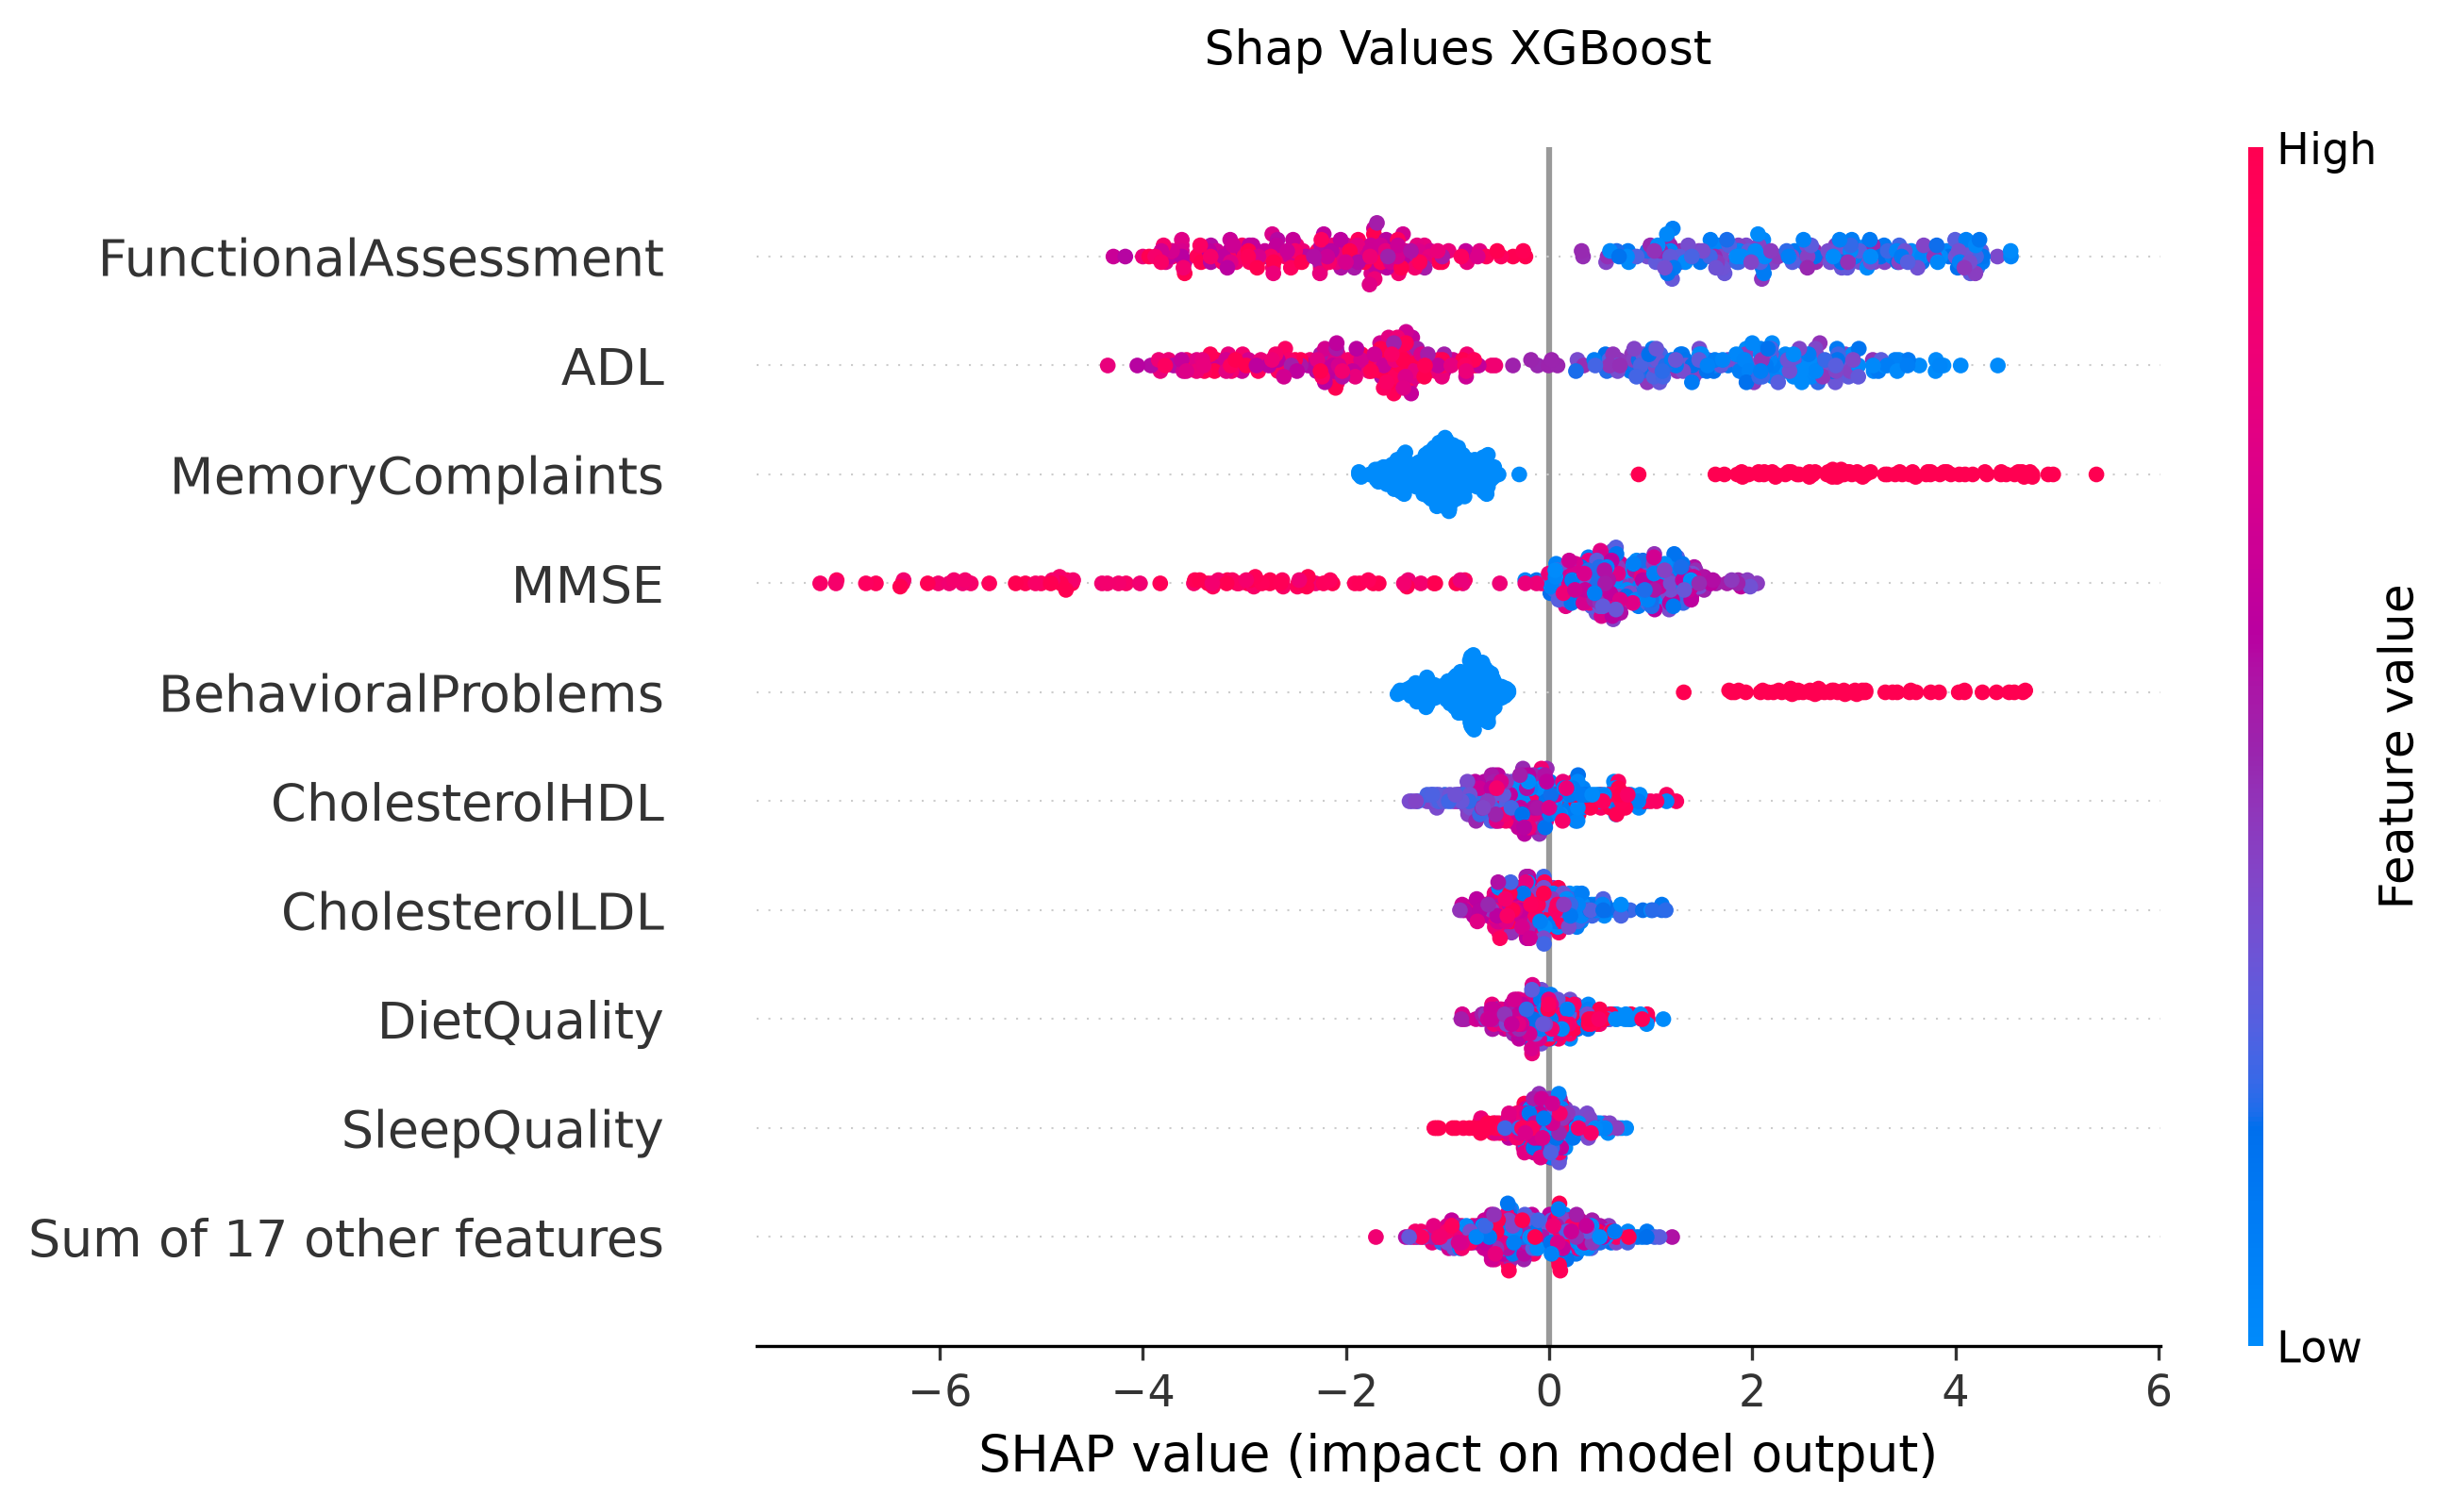

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/best-params/CAIDE/boosting_xgboost/shap_plot.png


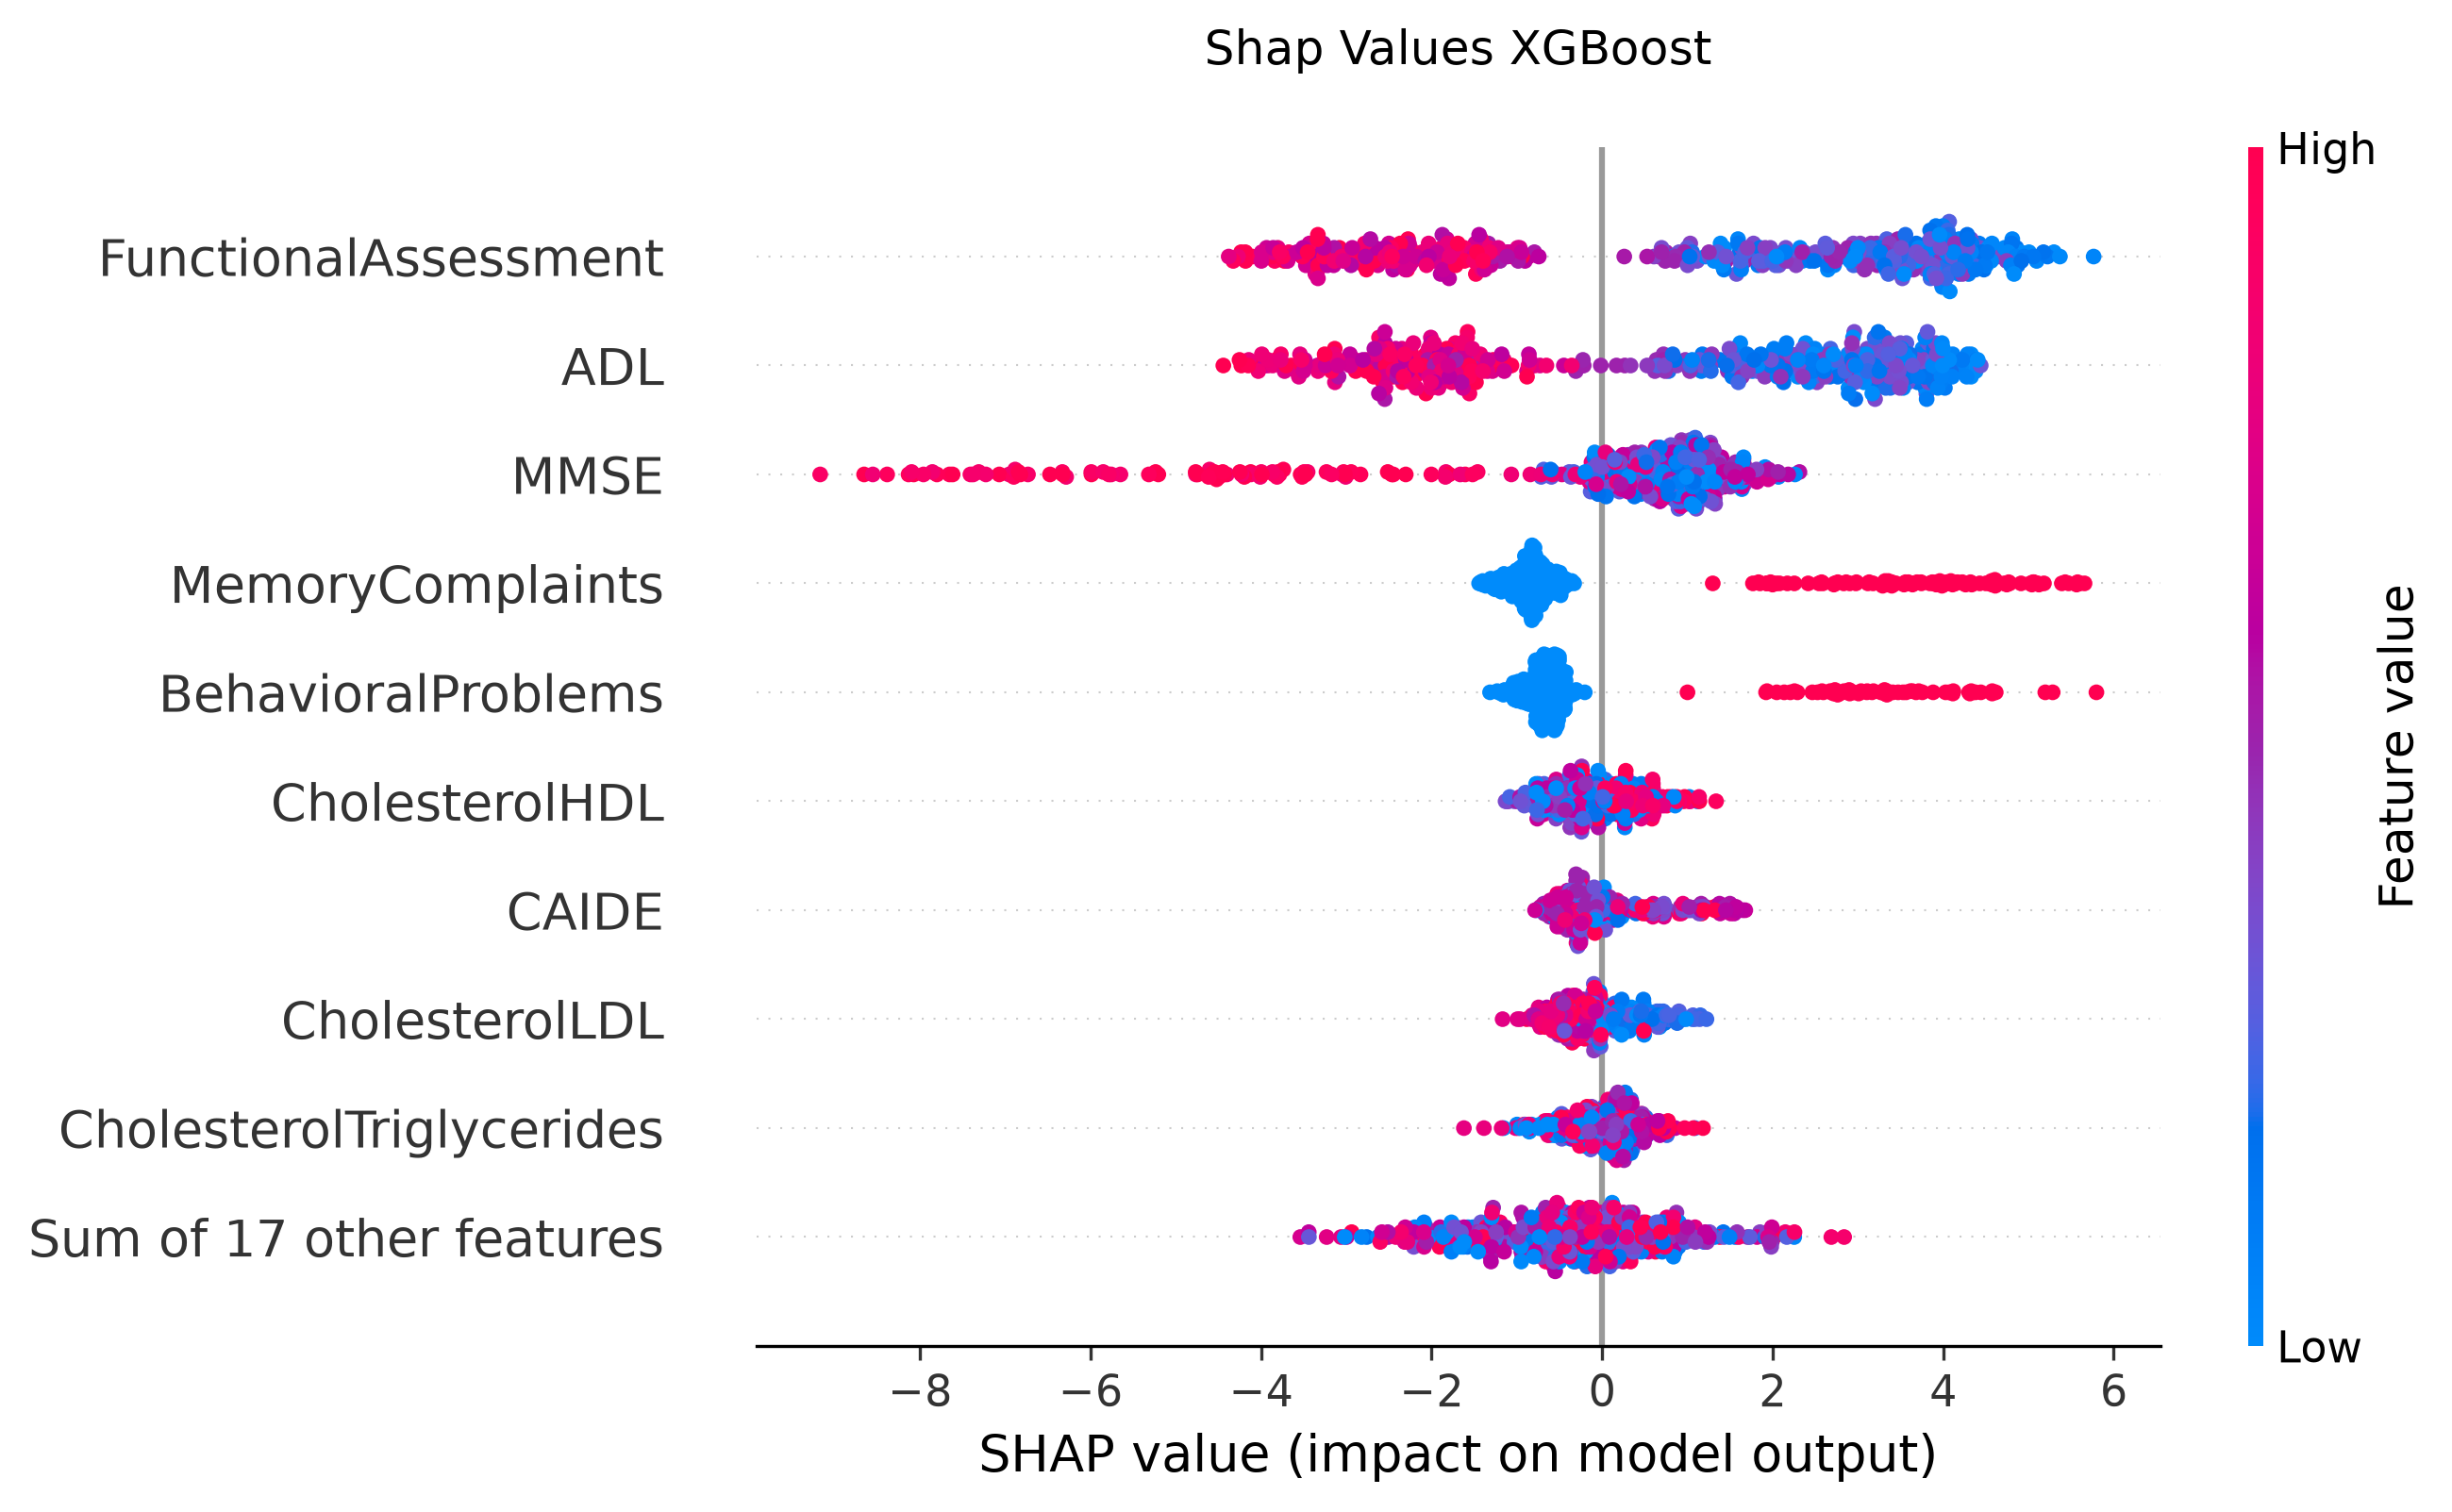

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/best-params/CAIDE/boosting_xgboost/shap_plot.png


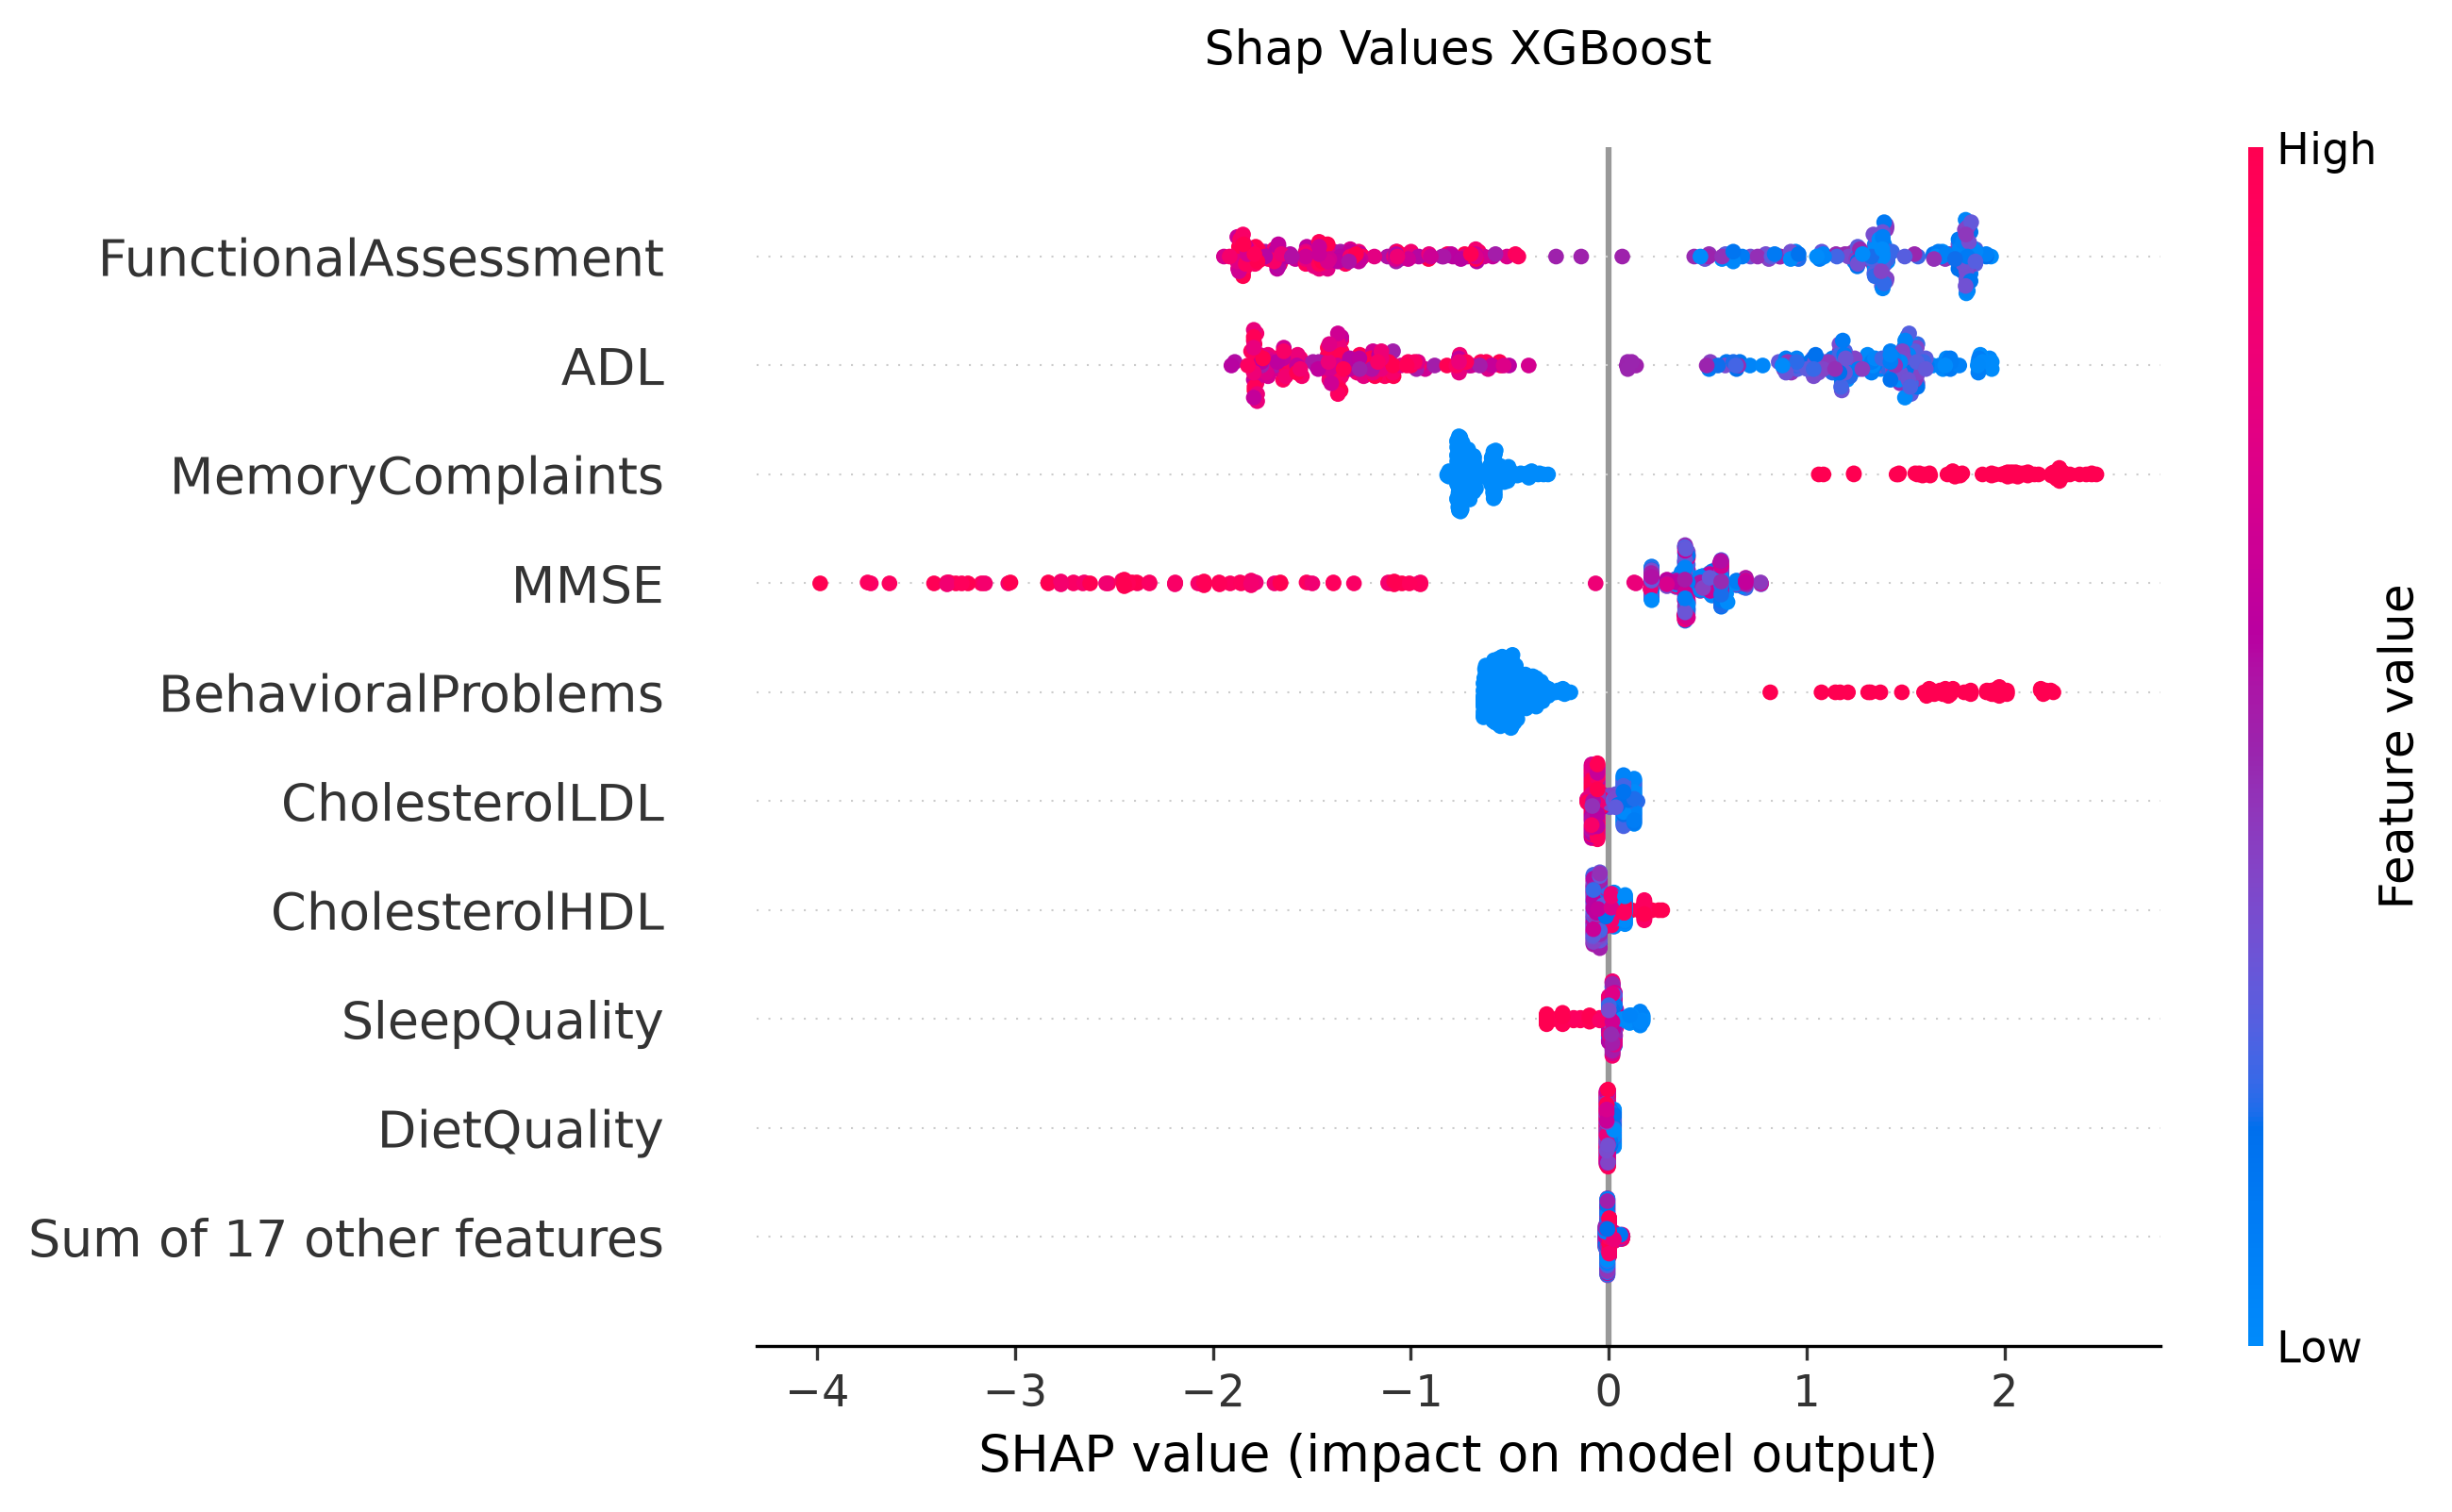

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/default/all/boosting_xgboost/shap_plot.png


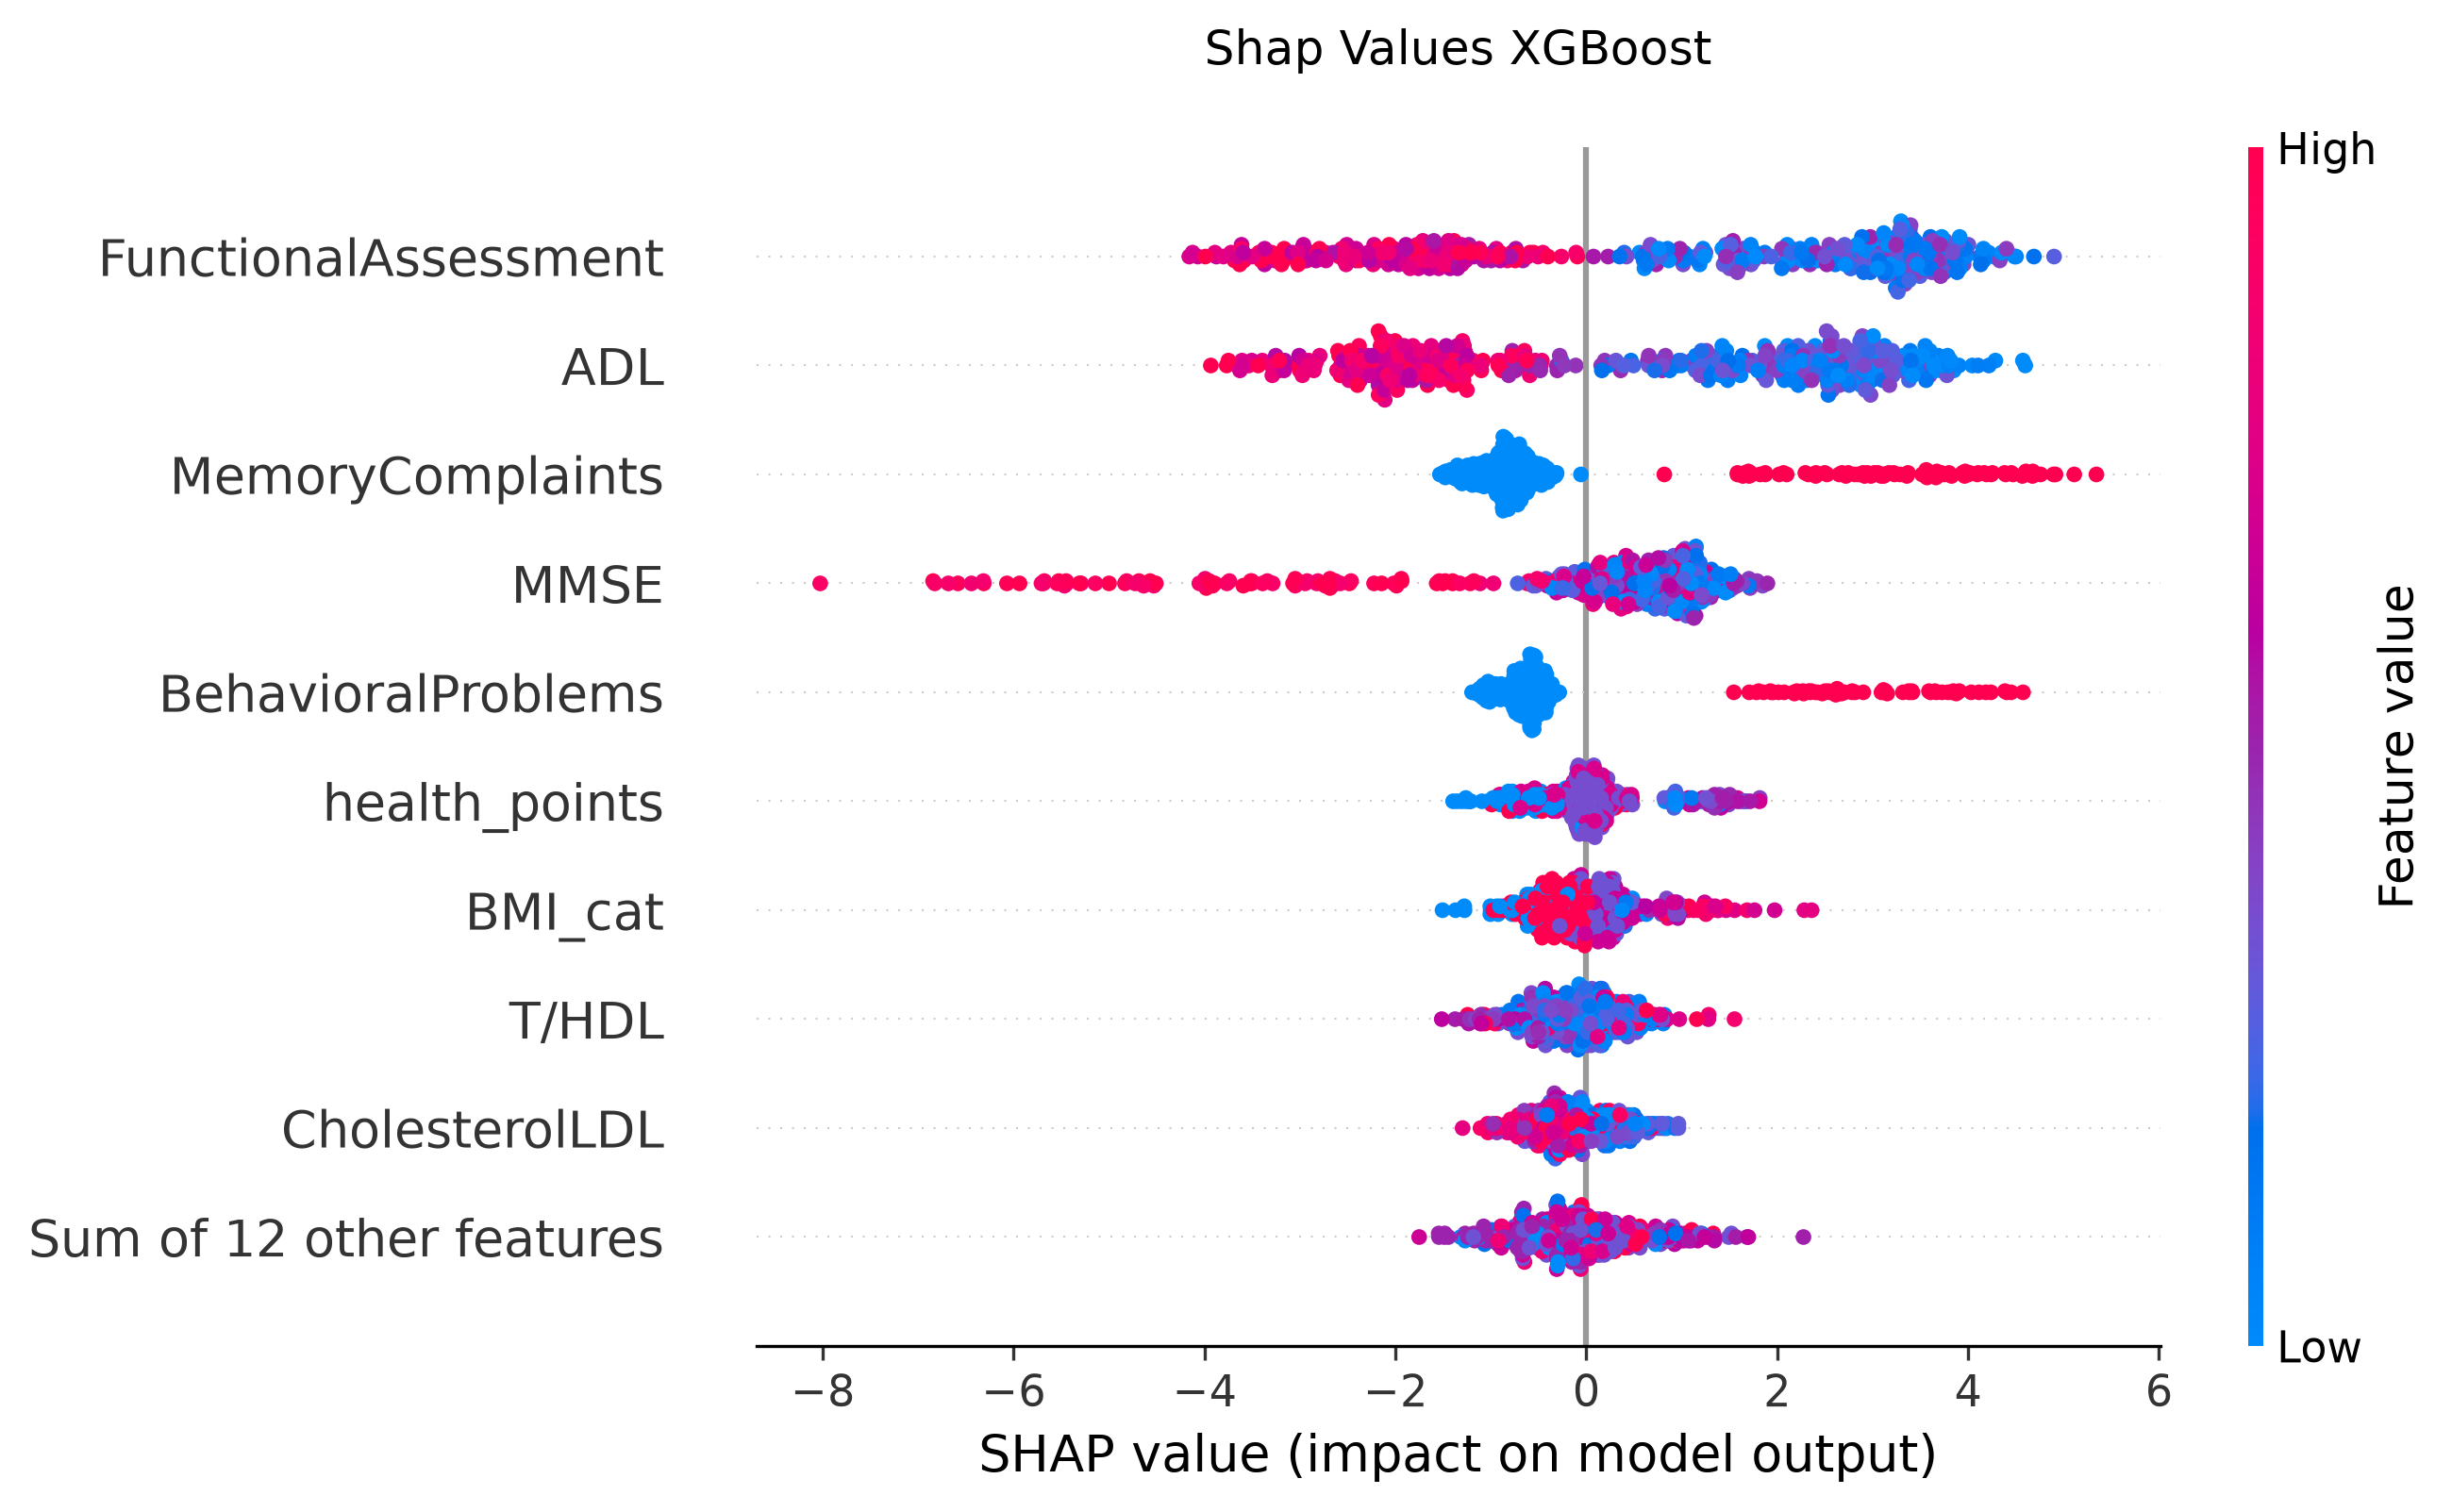

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/default/all/boosting_xgboost/shap_plot.png


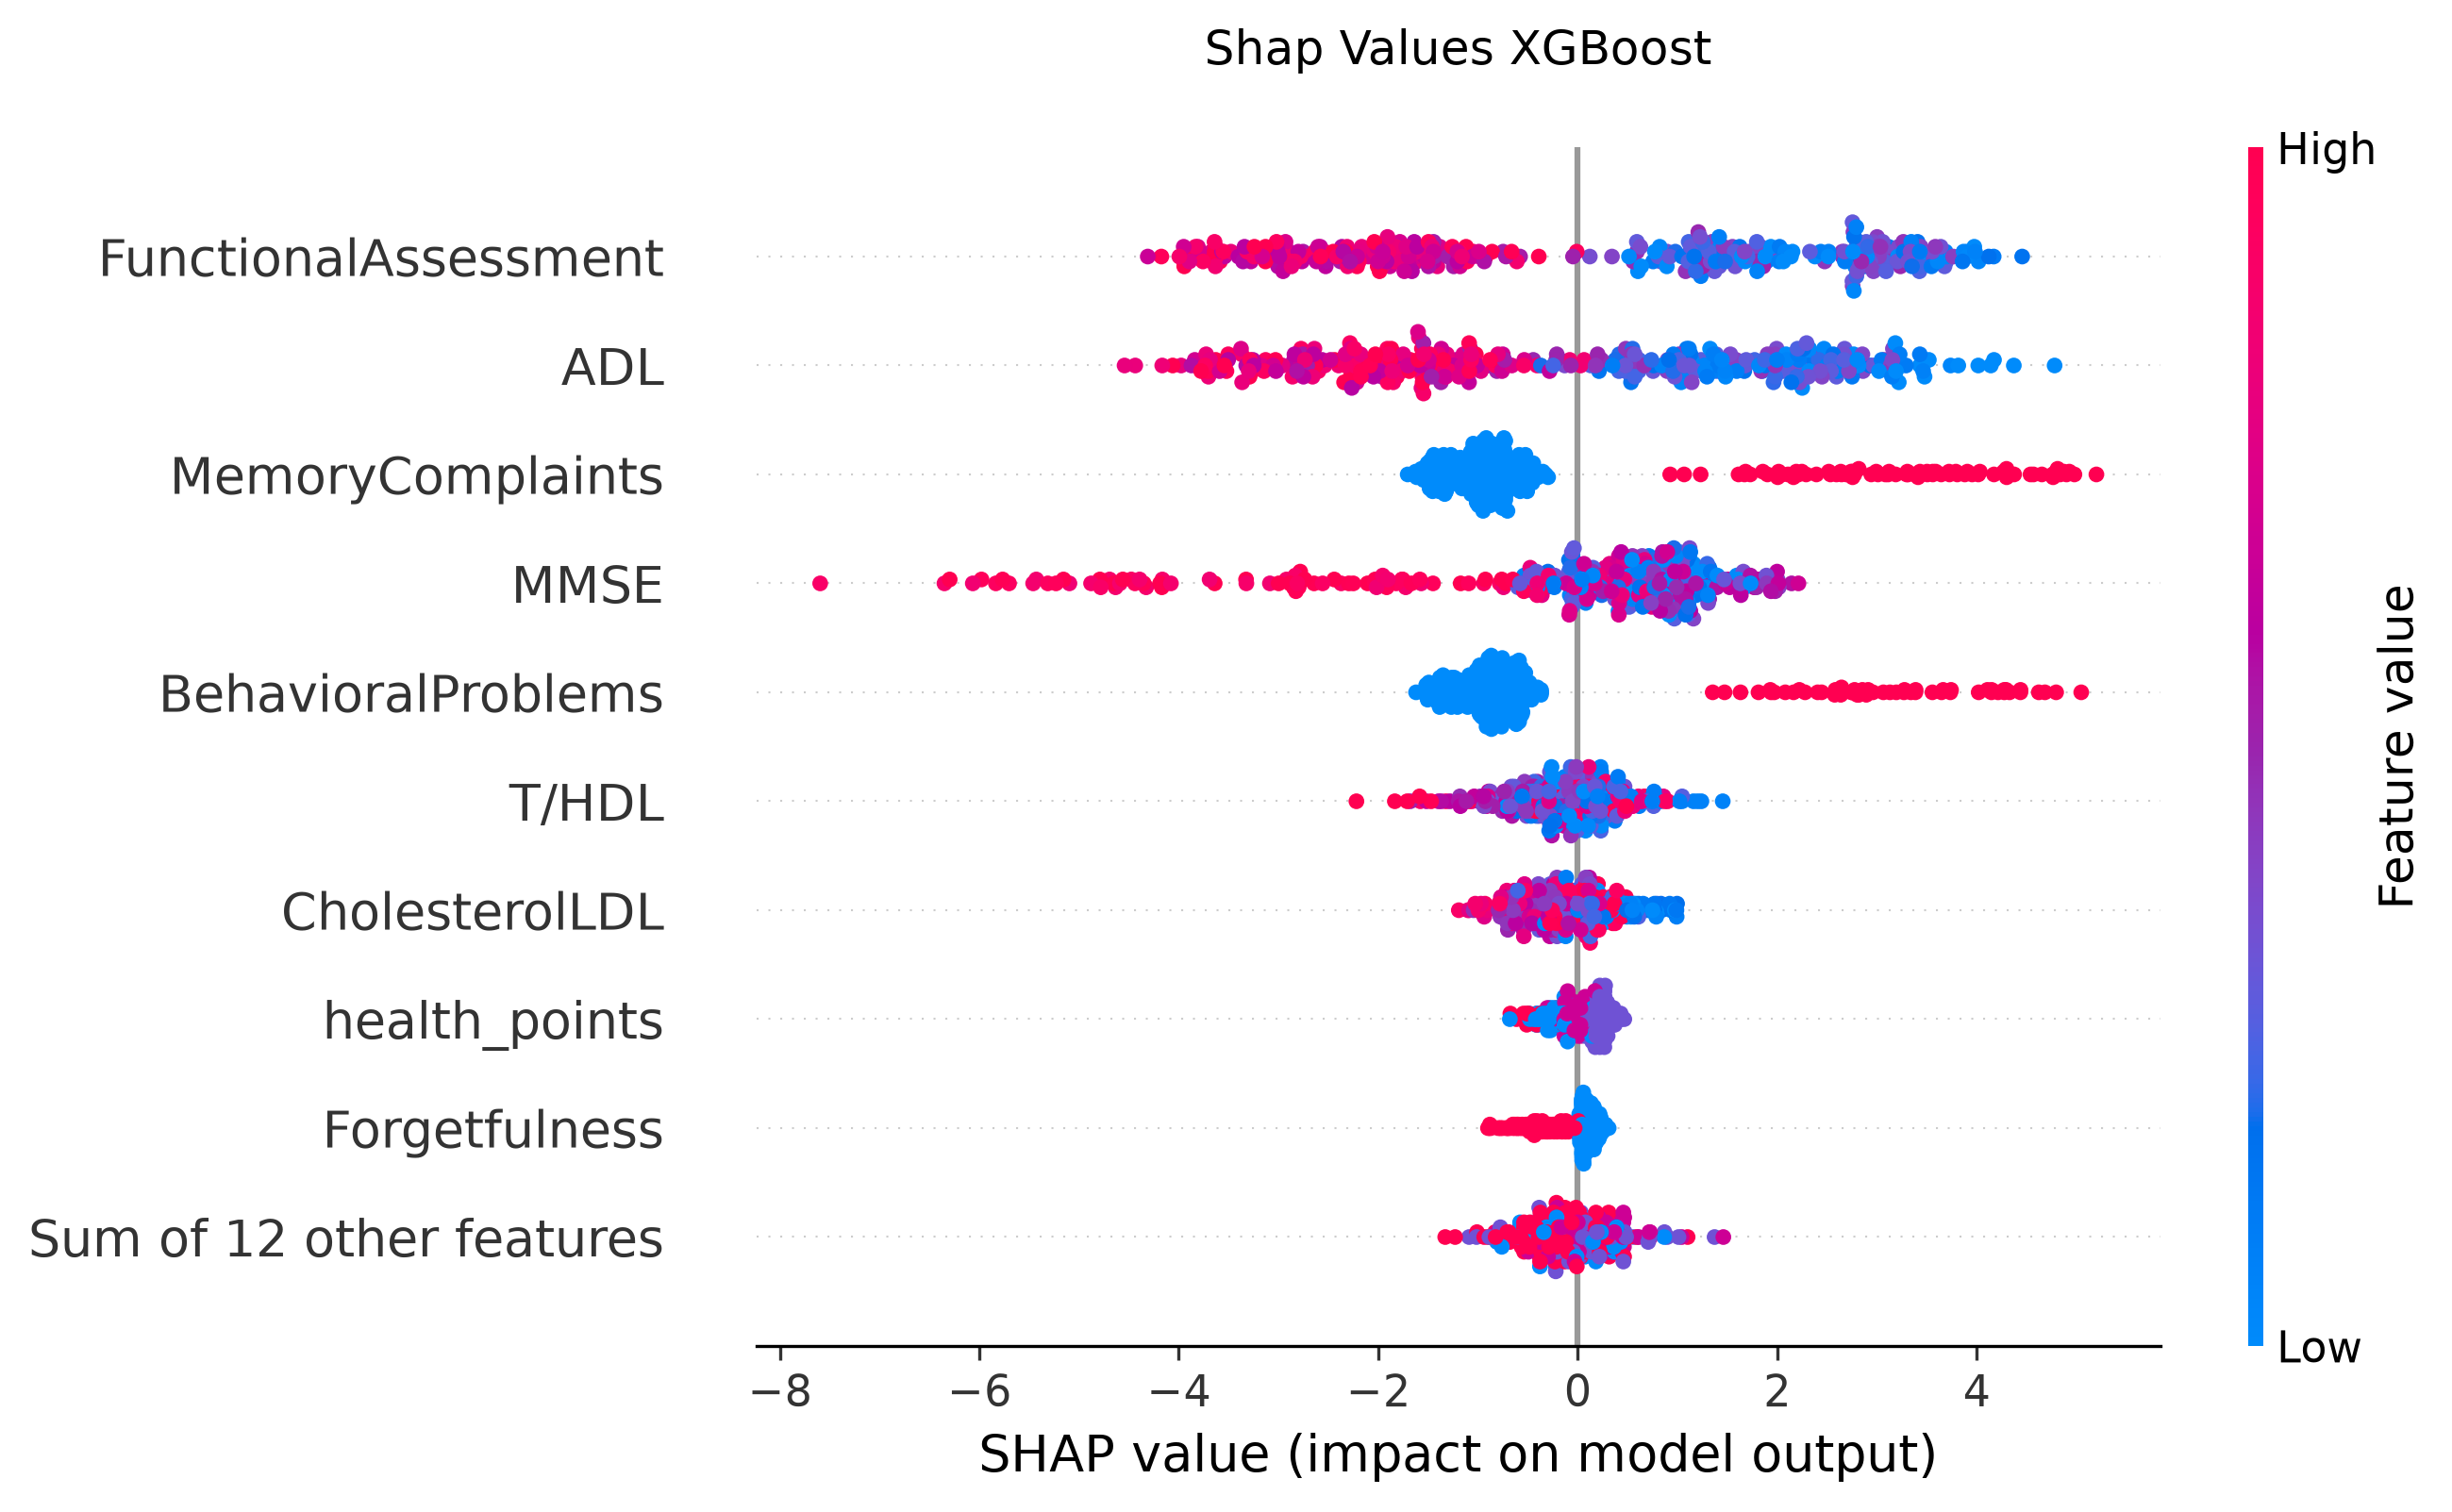

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/augmented/best-params/all/boosting_xgboost/shap_plot.png


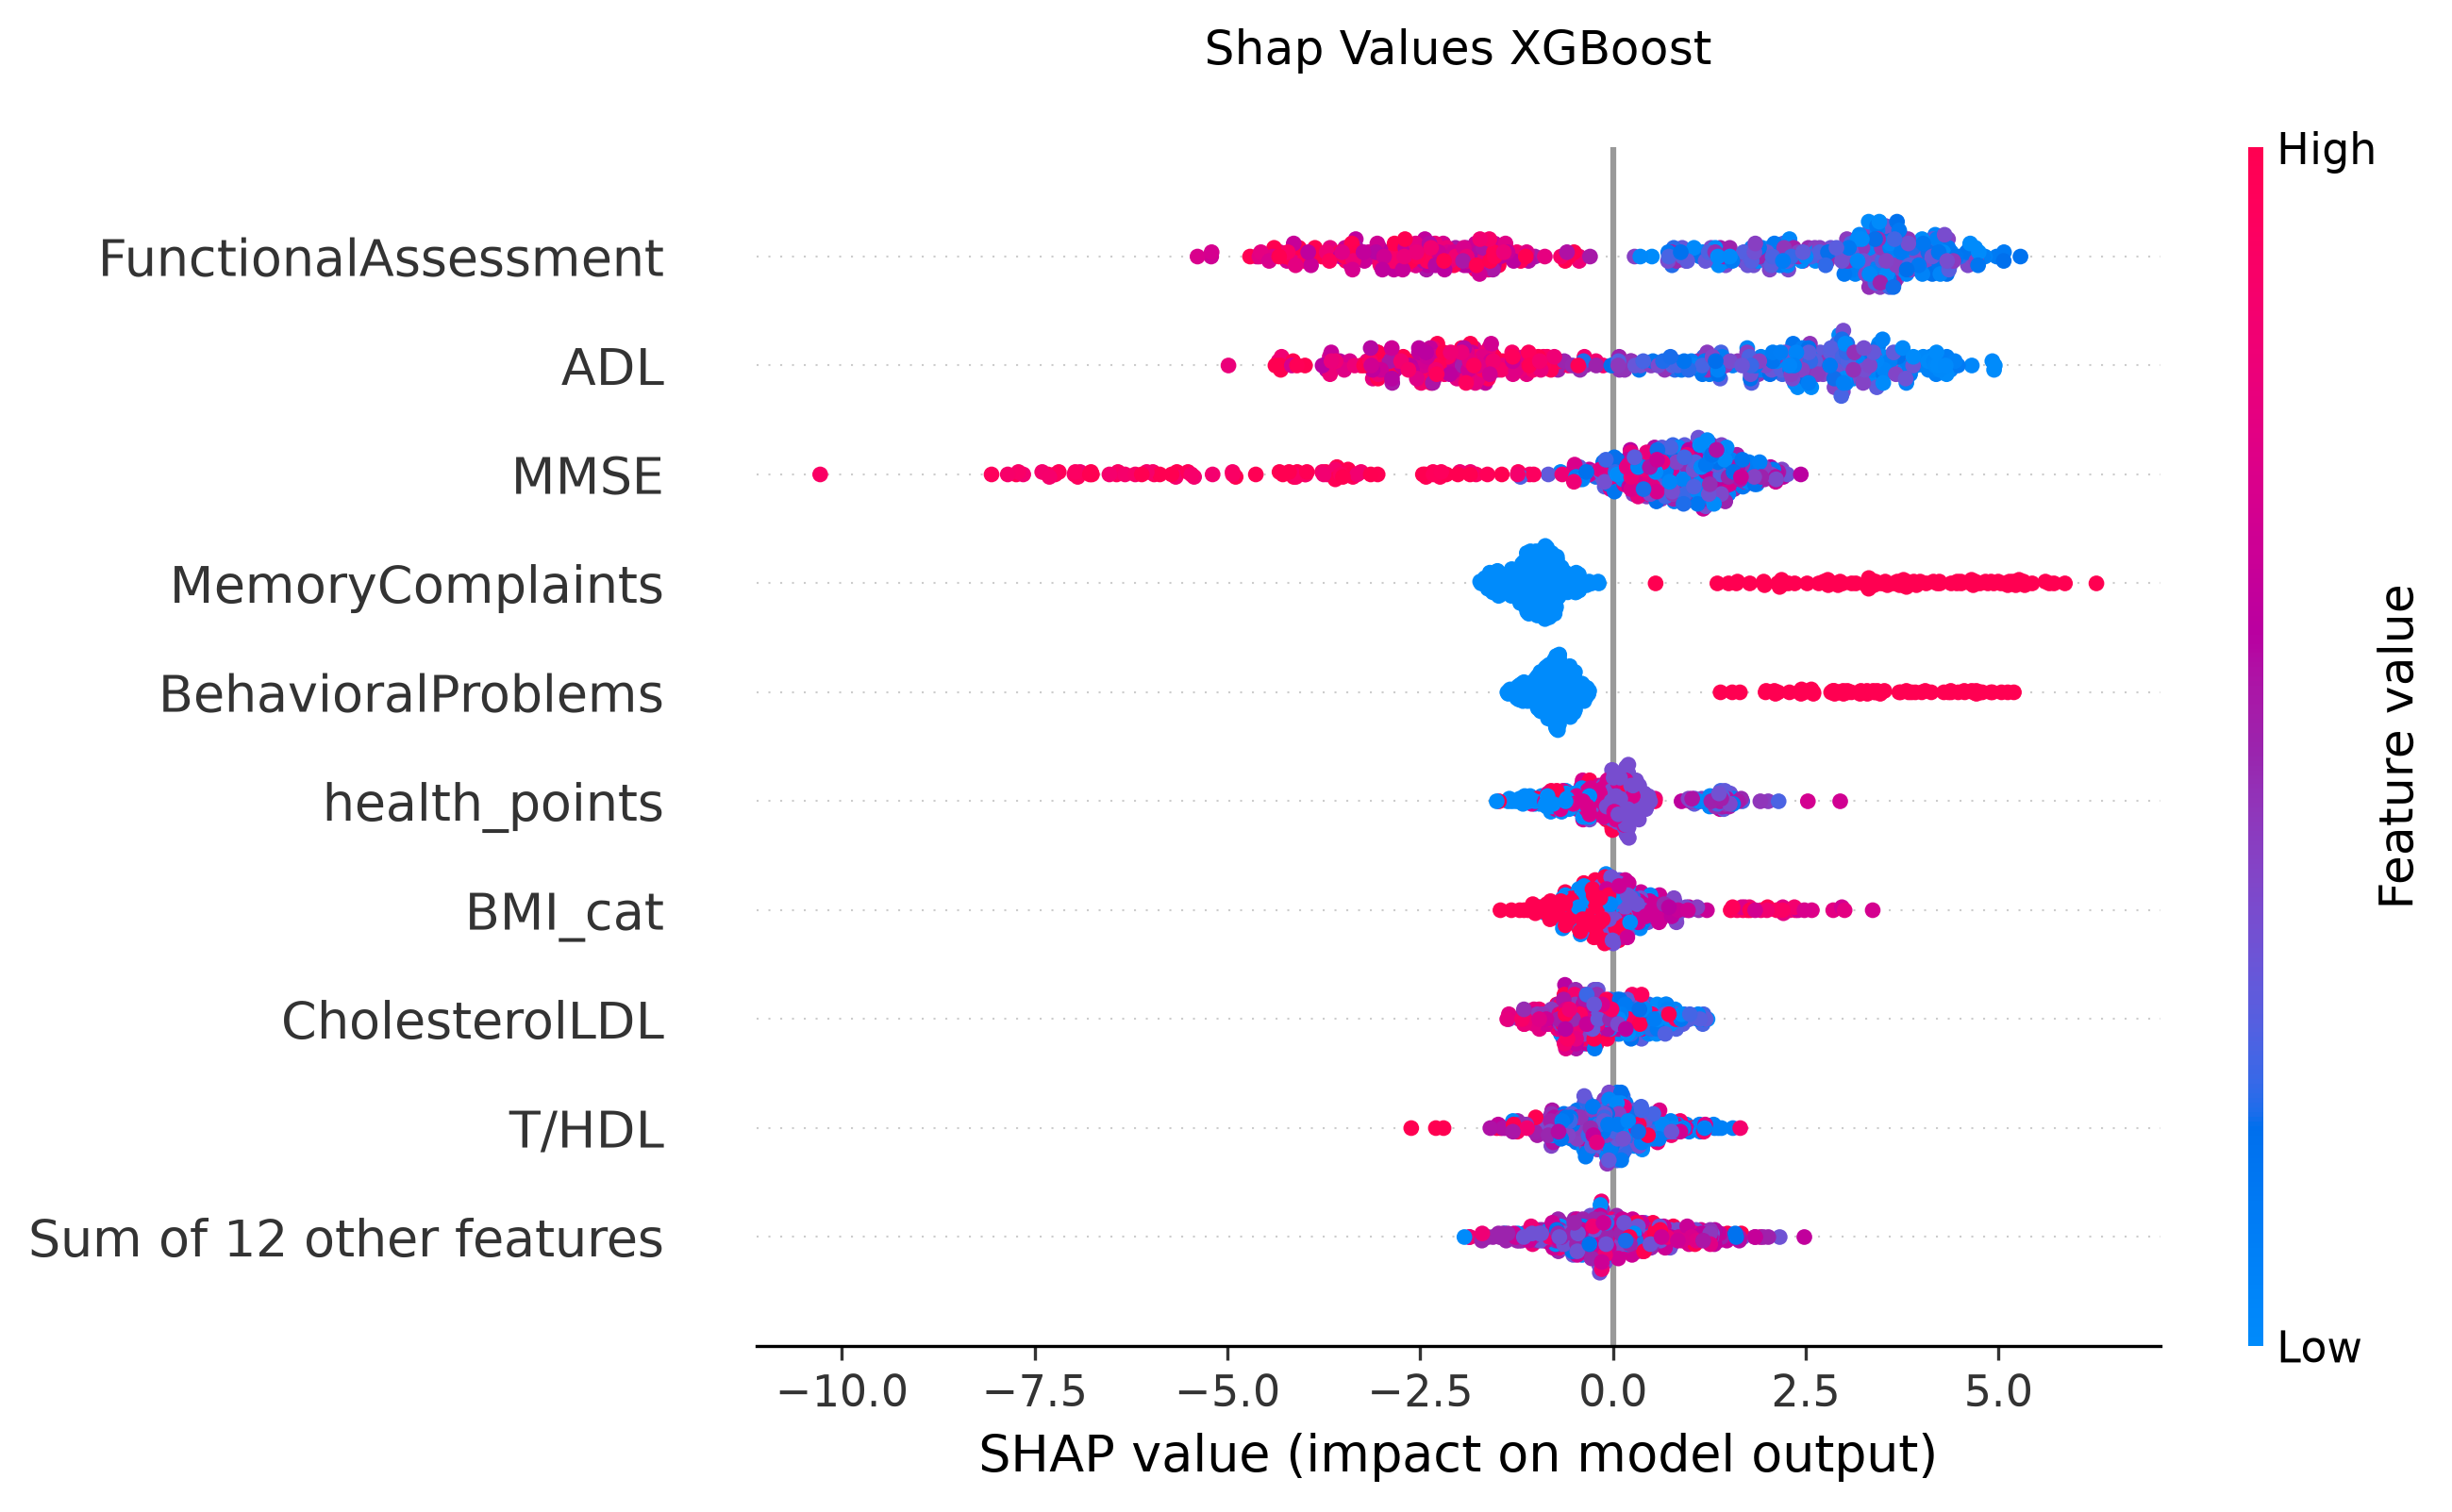

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/outputs/not_augmented/best-params/all/boosting_xgboost/shap_plot.png


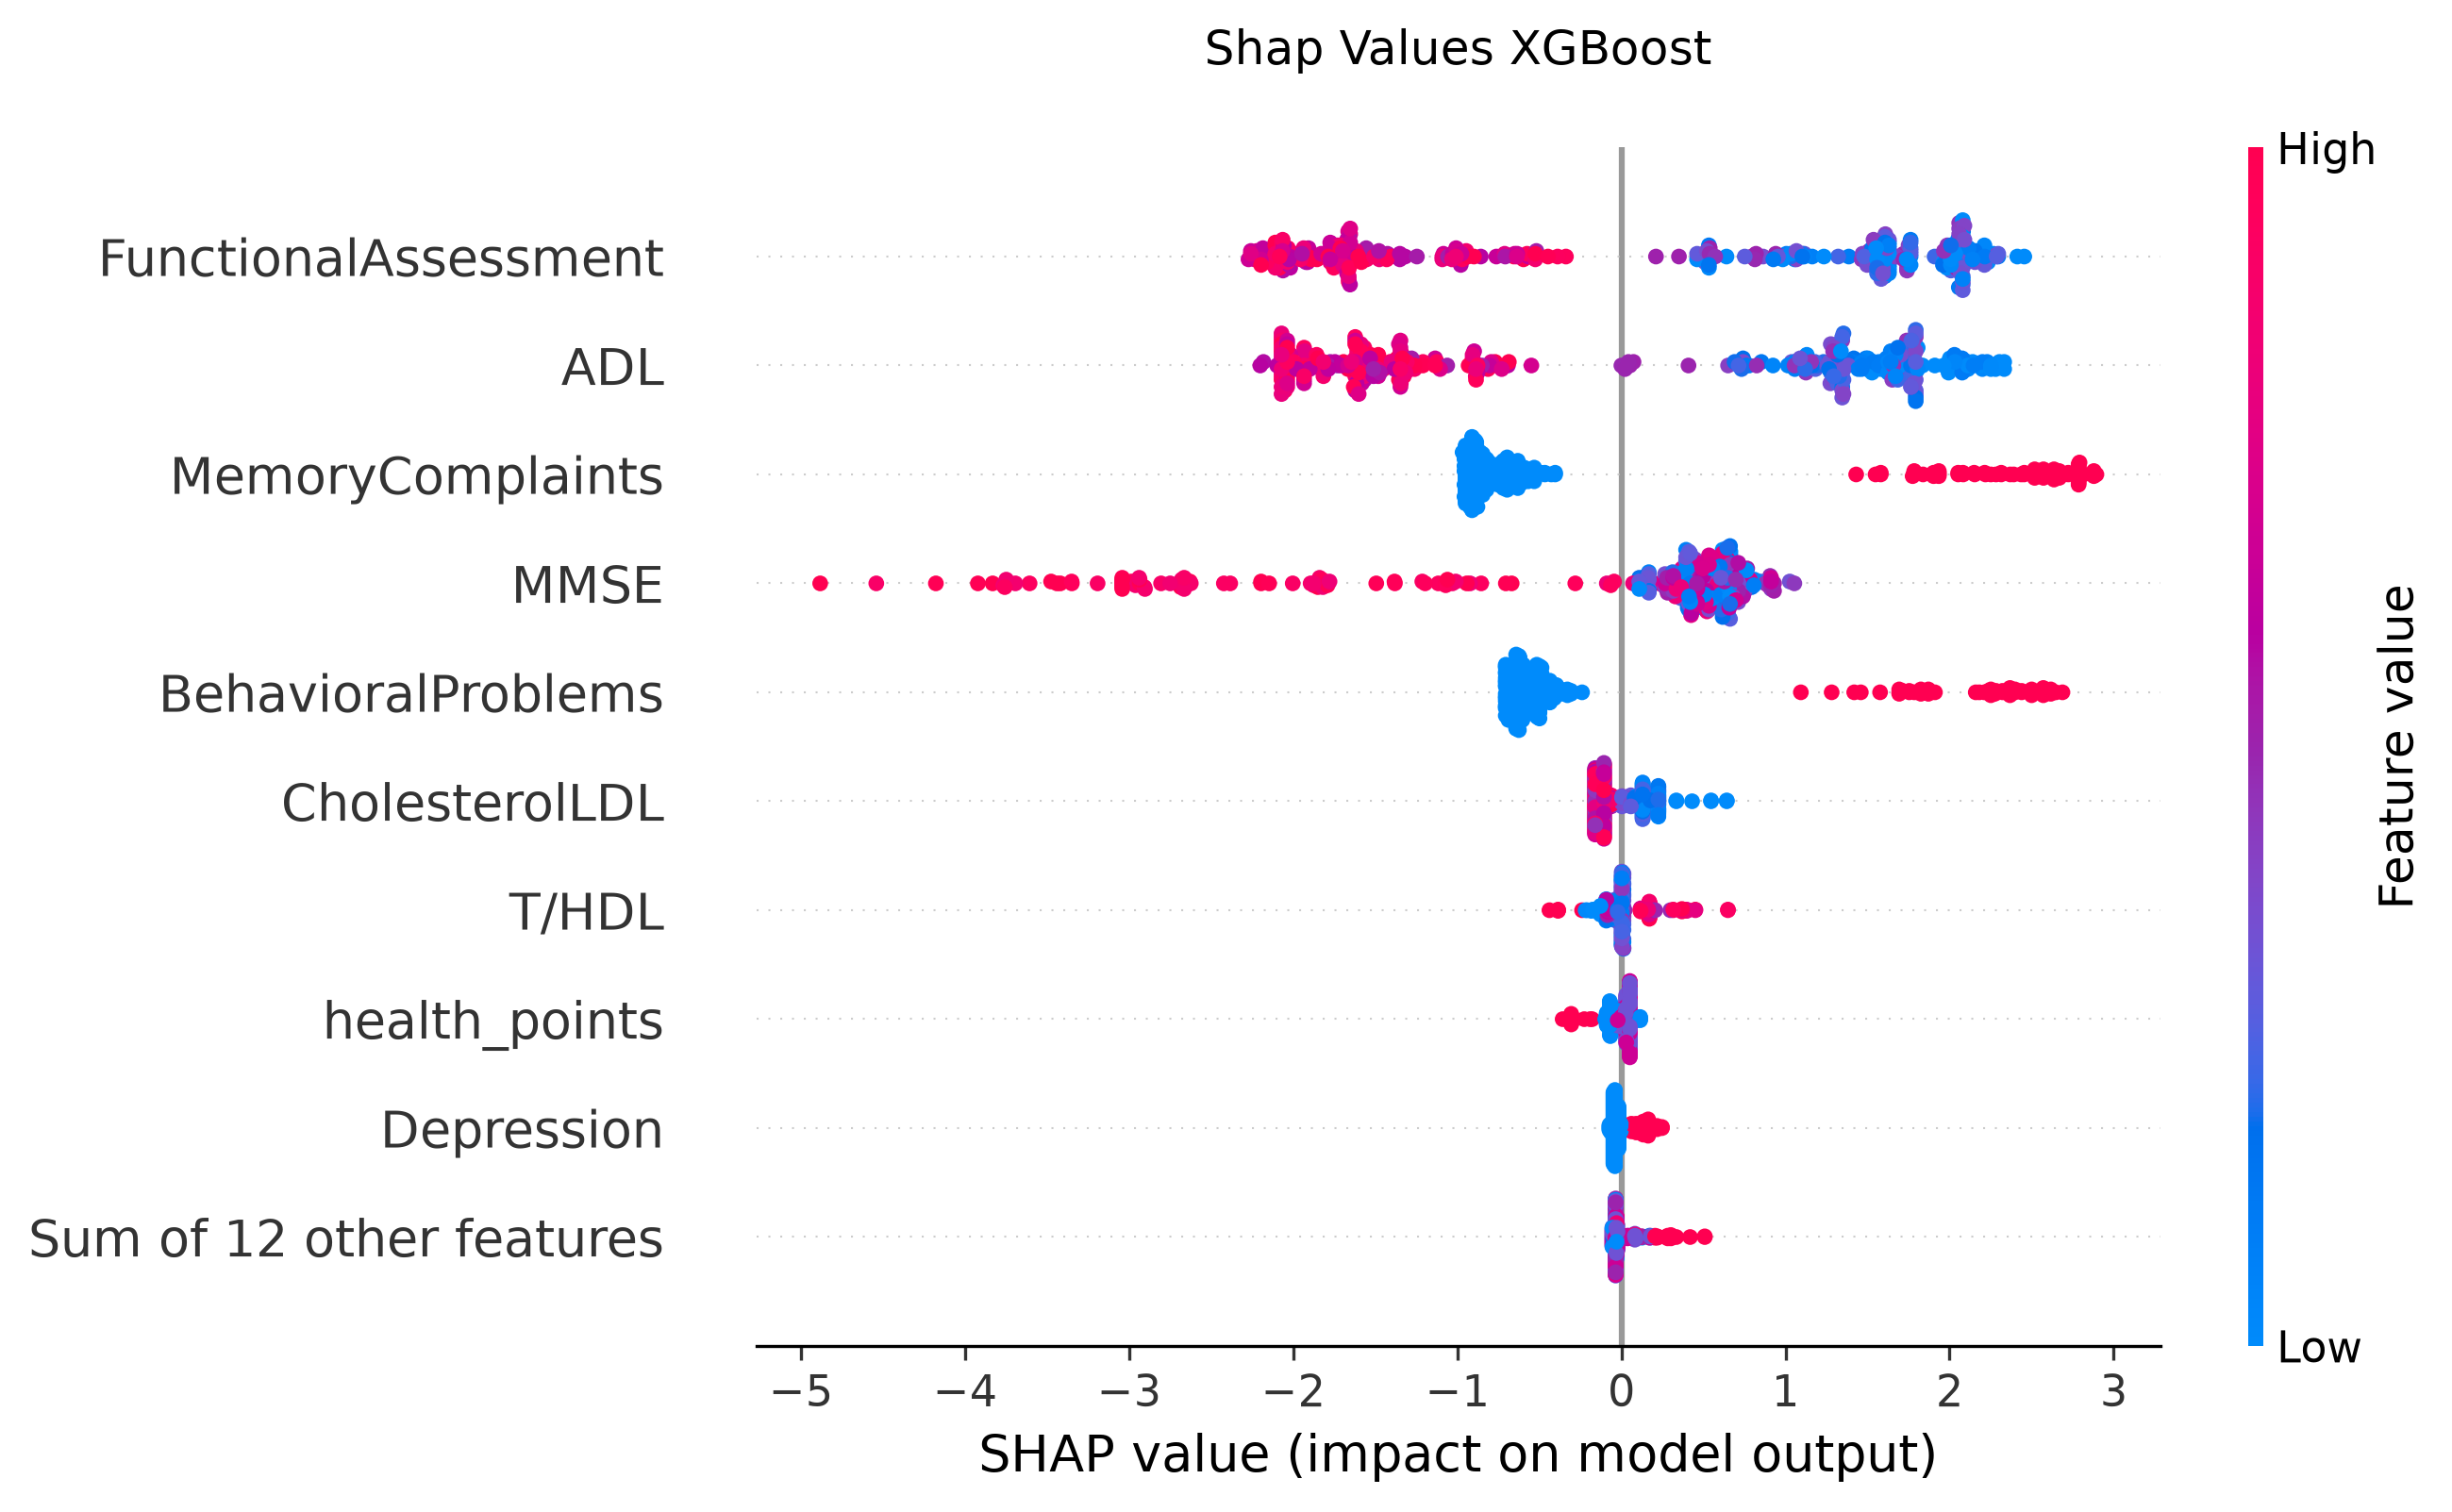

In [18]:

for img in [
    os.path.join(OUTPUTS_PATH, aug, dataset, features, 'boosting_xgboost', 'shap_plot.png')
    for features in FEATURES_NAMES
    for dataset in ['default', 'best-params']

    for aug in ['augmented', 'not_augmented']
]:
    print(img)
    display(Image(filename=img, width=600))


---

# Testing Best Features from SHAP

In [99]:
df_metrics_test_best = pd.DataFrame(columns=('dataset_type', 'params_type', 'metric', 'value', 'model'))

row_i = 0
for aug in os.listdir(BEST_PATH):
    if 'npy' in aug:
        continue
    for params_type in os.listdir(os.path.join(BEST_PATH, aug)):
        for model in os.listdir(os.path.join(BEST_PATH, aug, params_type, 'best-features')):
            metrics_file = os.path.join(BEST_PATH, aug, params_type, 'best-features', model, 'output_test_metrics.json')

            with open(metrics_file, 'r') as file:
                json_data = json.load(file)

                for k in json_data.keys():
                    if ('confusion_matrix' == k) or \
                        ('macro' in k) or \
                        ('micro' in k) or \
                        ('jaccard' in k):
                        continue
                    df_metrics_test_best.loc[row_i] = {
                        'dataset_type': aug,
                        'params_type':params_type,
                        'metric': k,
                        'value': json_data[k],
                        'model':model
                    }
                    row_i += 1
                    
df_metrics_test_best = df_metrics_test_best.sort_values(by='model')
df_metrics_test_best.head()


,dataset_type,params_type,metric,value,model
52,not_augmented,default,precision,0.739496,bagging_logistic
120,not_augmented,best-params,accuracy,0.813953,bagging_logistic
123,not_augmented,best-params,recall,0.719008,bagging_logistic
124,not_augmented,best-params,roc_auc,0.792240,bagging_logistic
194,augmented,default,roc_auc,0.824809,bagging_logistic


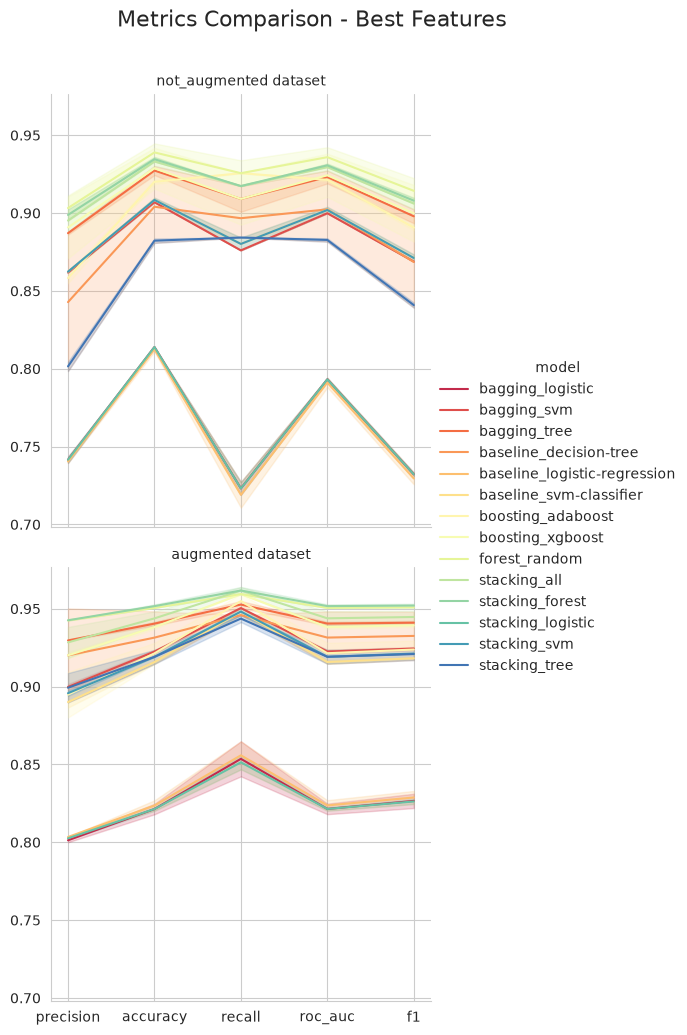

In [100]:
sns.set_style("whitegrid")
g = sns.relplot(
    kind='line',
    data=df_metrics_test_best,
    x='metric',
    y='value',
    hue='model',
    row='dataset_type',
    palette='Spectral'
)
for ax in g.axes.flat:
  ax.grid(True, axis="x") 
g.set_titles(template="{row_name} dataset")
g.set_axis_labels("", "")
plt.suptitle('Metrics Comparison - Best Features', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('comparison_metrics_per_model_best_features.png'), dpi=300, bbox_inches='tight')
plt.show()

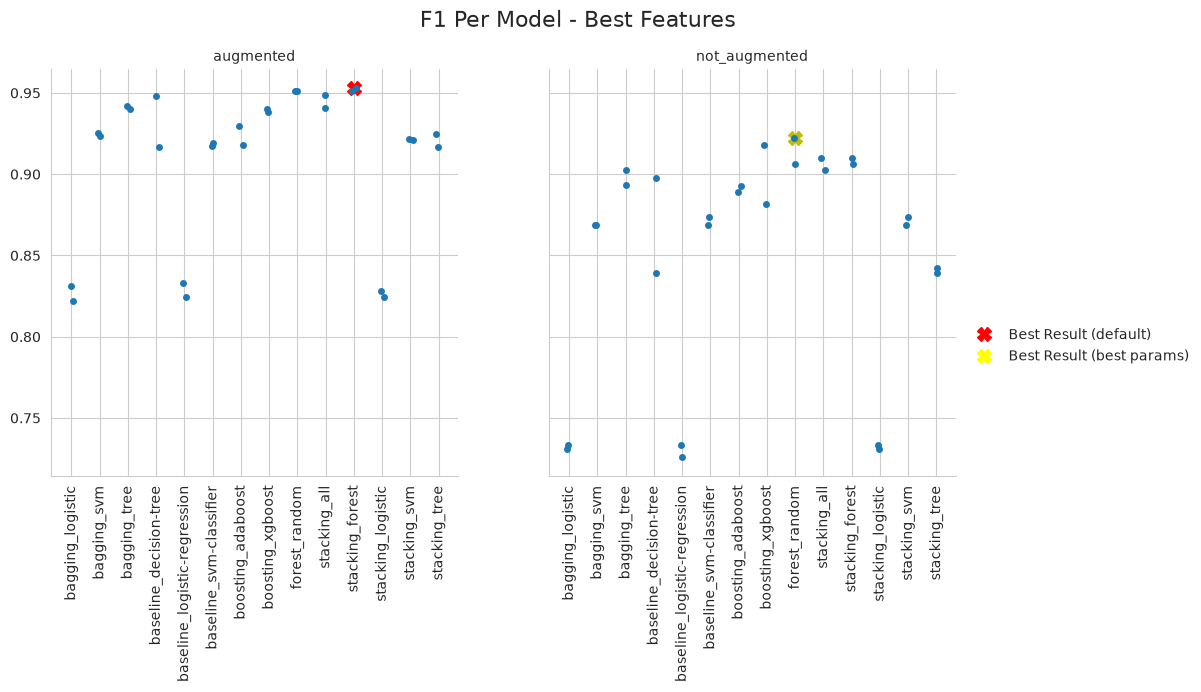

In [101]:
sns.set_style("whitegrid")
f1_data = df_metrics_test_best.loc[(df_metrics_test_best['metric'] == 'f1')]

g = sns.catplot(
    kind="strip", 
    data=f1_data, 
    x="model", 
    y='value',
    col='dataset_type',
)

for ax in g.axes.flat:
  ax.grid(
      True, axis="x",
  ) 

not_agumented_ax = g.axes[0,1]
agumented_ax = g.axes[0,0]

for dataset_type, ax in zip(('augmented', 'not_augmented'), (agumented_ax, not_agumented_ax)):
    d = f1_data[(f1_data['dataset_type'] == dataset_type)]
    pos = d['value'].idxmax()

    ax.plot(
        d.loc[pos]['model'], 
        d.loc[pos]['value'], 
        'rX' if d.loc[pos]['params_type'] == 'default' else 'yX',
        markersize=10
    )

    best_models.loc[len(best_models)] = {
        "dataset_type":dataset_type,
        "columns":"best",
        "model":d.loc[pos]['model']
    }

g.set_xticklabels(rotation=90)
g.set_axis_labels('', '')
g.set_titles(template="{col_name}")

best_default = plt.Line2D([],[], color='red', marker="X", linestyle='None', markersize=10)
best_params = plt.Line2D([],[], color='yellow', marker="X", linestyle='None', markersize=10)

g._legend_data['Best Result (default)'] = best_default
g._legend_data['Best Result (best params)'] = best_params
g._legend.remove()
g.add_legend()

plt.suptitle('F1 Per Model - Best Features', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('f1_per_model_best_features.png'), dpi=300, bbox_inches='tight')
plt.show()




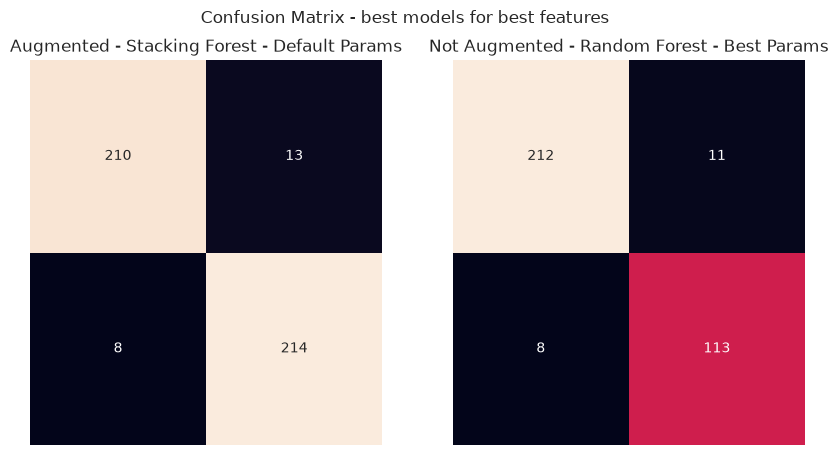

In [35]:
cm_stacking_forest_aug = None
cm_forest_radom_not_aug = None

with open(os.path.join(BEST_PATH, 'augmented', 'default', 'best-features', 'stacking_forest', 'output_test_metrics.json'), 'r') as file:
    d = json.load(file)
    cm_stacking_forest_aug = d['confusion_matrix']

with open(os.path.join(BEST_PATH, 'not_augmented', 'best-params', 'best-features', 'forest_random', 'output_test_metrics.json'), 'r') as file:
    d = json.load(file)
    cm_forest_radom_not_aug = d['confusion_matrix']

fig,ax = plt.subplots(1,2, figsize=(10,5))
sns.heatmap(cm_stacking_forest_aug, annot=True, fmt='.0f', ax=ax[0], cbar=False)
sns.heatmap(cm_forest_radom_not_aug, annot=True, fmt='.0f', ax=ax[1], cbar=False)

ax[0].set_title('Augmented - Stacking Forest - Default Params')
ax[1].set_title('Not Augmented - Random Forest - Best Params')

for i in range(2):
    ax[i].set_xticklabels([])
    ax[i].set_yticklabels([])
            
fig.suptitle('Confusion Matrix - best models for best features')
fig.savefig(PLOTS_PATH('confusion_matrix_best_models_best_features.png'), dpi=300, bbox_inches='tight')
plt.show()

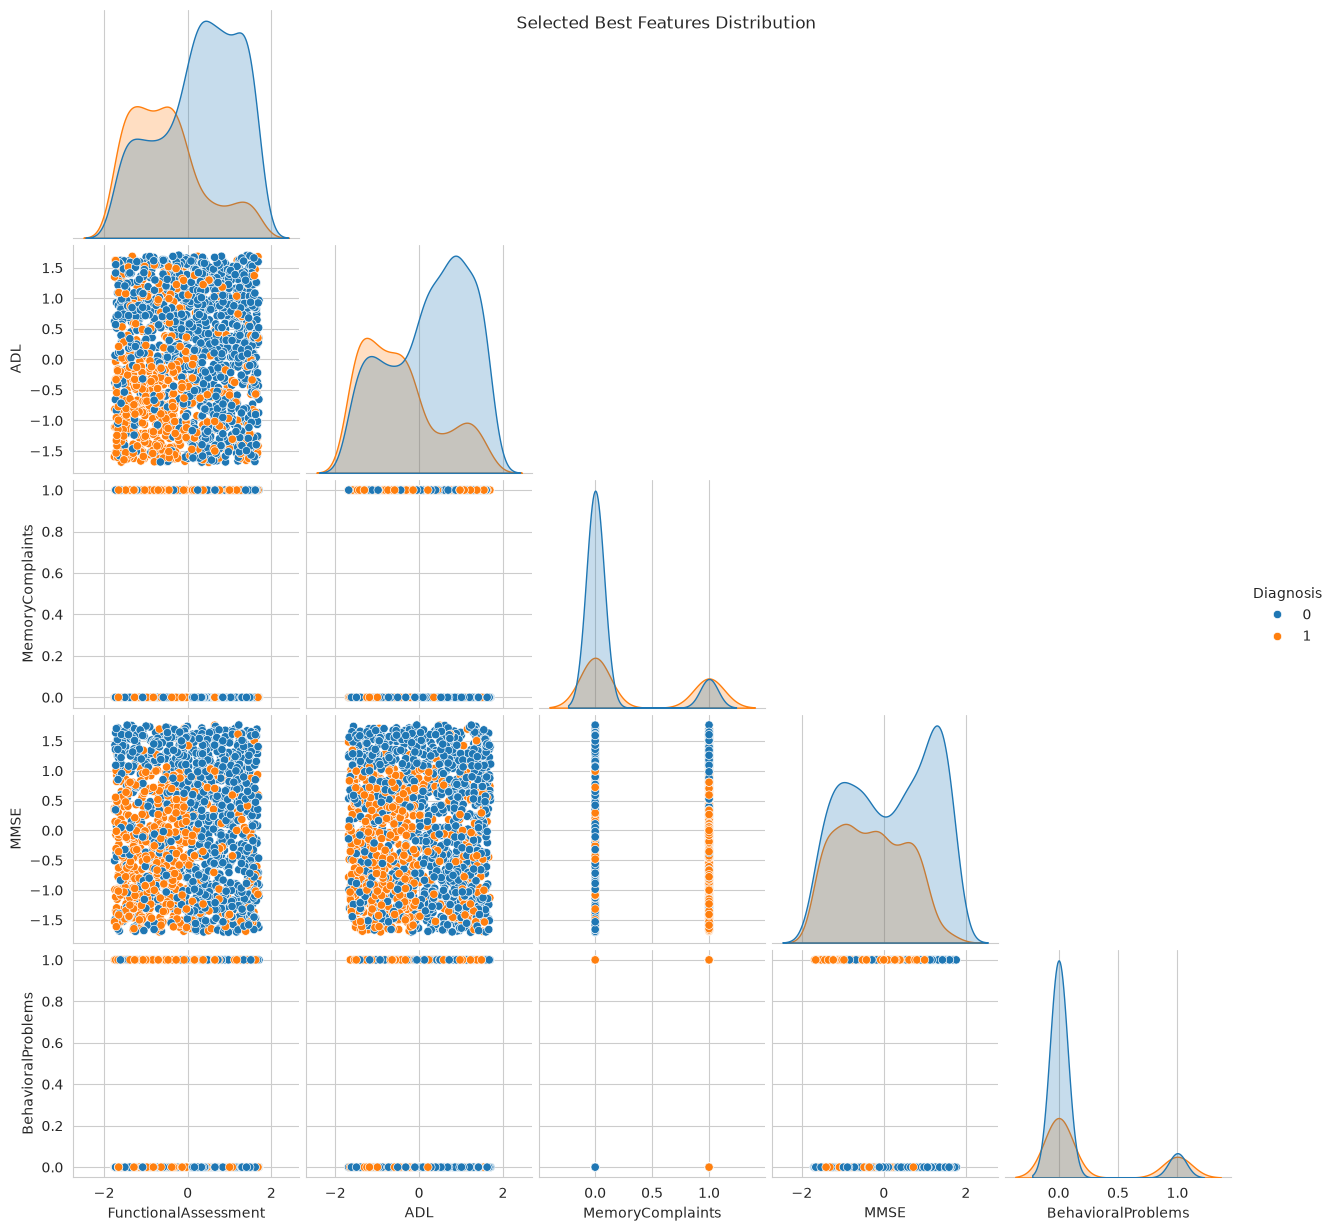

In [46]:
original_df = load_and_format_dataset()
important_part = original_df[[*SELECTED_BEST_FEATURES, TARGET]]

g = sns.pairplot(important_part, 
                corner=True,
                hue=TARGET)
plt.suptitle("Selected Best Features Distribution")
plt.savefig(PLOTS_PATH("best_features_dist.png"), dpi=300, bbox_inches='tight')
plt.show()

In [79]:
perf_df = pd.DataFrame(columns=('dataset_type', 'columns', 'params_type', 'time', 'model', 'task'))

row_i = 0
for dataset_type in os.listdir(OUTPUTS_PATH):
    if dataset_type in ['best-features', 'table.html', 'table.json', '.ipynb_checkpoints']:
        continue
    
    for params_type in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type)):
        for columns in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type)):
            for model in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type, columns)):
                
                if 'npy' in model:
                    continue
                    
                time_file = os.path.join(
                    OUTPUTS_PATH, dataset_type, params_type, columns, model, 'time.json'
                )

                with open(time_file, 'r') as file:
                    json_data = json.load(file)

                    perf_df.loc[row_i] = {
                        'dataset_type': dataset_type,
                        'columns':columns,
                        'params_type':params_type,
                        'time': json_data['elapsed_time'],
                        'model':model,
                        'task': 'train'
                    }
                    perf_df.loc[row_i+1] = {
                        'dataset_type': dataset_type,
                        'columns':columns,
                        'params_type':params_type,
                        'time': json_data['elapsed_time_inference'],
                        'model':model,
                        'task': 'eval'
                    }
                    row_i += 2
                    
for aug in os.listdir(BEST_PATH):
    if 'npy' in aug:
        continue
    for params_type in os.listdir(os.path.join(BEST_PATH, aug)):
        for model in os.listdir(os.path.join(BEST_PATH, aug, params_type, 'best-features')):
            time_file = os.path.join(BEST_PATH, aug, params_type, 'best-features', model, 'time.json')

            with open(time_file, 'r') as file:
                json_data = json.load(file)

                perf_df.loc[row_i] = {
                    'dataset_type': aug,
                    'columns':'best',
                    'params_type':params_type,
                    'time': json_data['elapsed_time'],
                    'model':model,
                    'task': 'train'
                }
                perf_df.loc[row_i+1] = {
                    'dataset_type': aug,
                    'columns':'best',
                    'params_type':params_type,
                    'time': json_data['elapsed_time_inference'],
                    'model':model,
                    'task': 'eval'
                }
                row_i += 2
perf_df = perf_df.sort_values(by='model')
perf_df.head()

,dataset_type,columns,params_type,time,model,task
300,augmented,CAIDE,default,24.635531,bagging_logistic,train
132,not_augmented,ours,best-params,76.052948,bagging_logistic,train
77,not_augmented,CAIDE,default,0.020290,bagging_logistic,eval
105,not_augmented,all,default,0.020860,bagging_logistic,eval
469,not_augmented,best,default,0.025203,bagging_logistic,eval


In [105]:
c_pallete = { model: 'orange' if model in best_models.model.unique() else 'blue'  for model in perf_df.model.unique() }

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=Fals

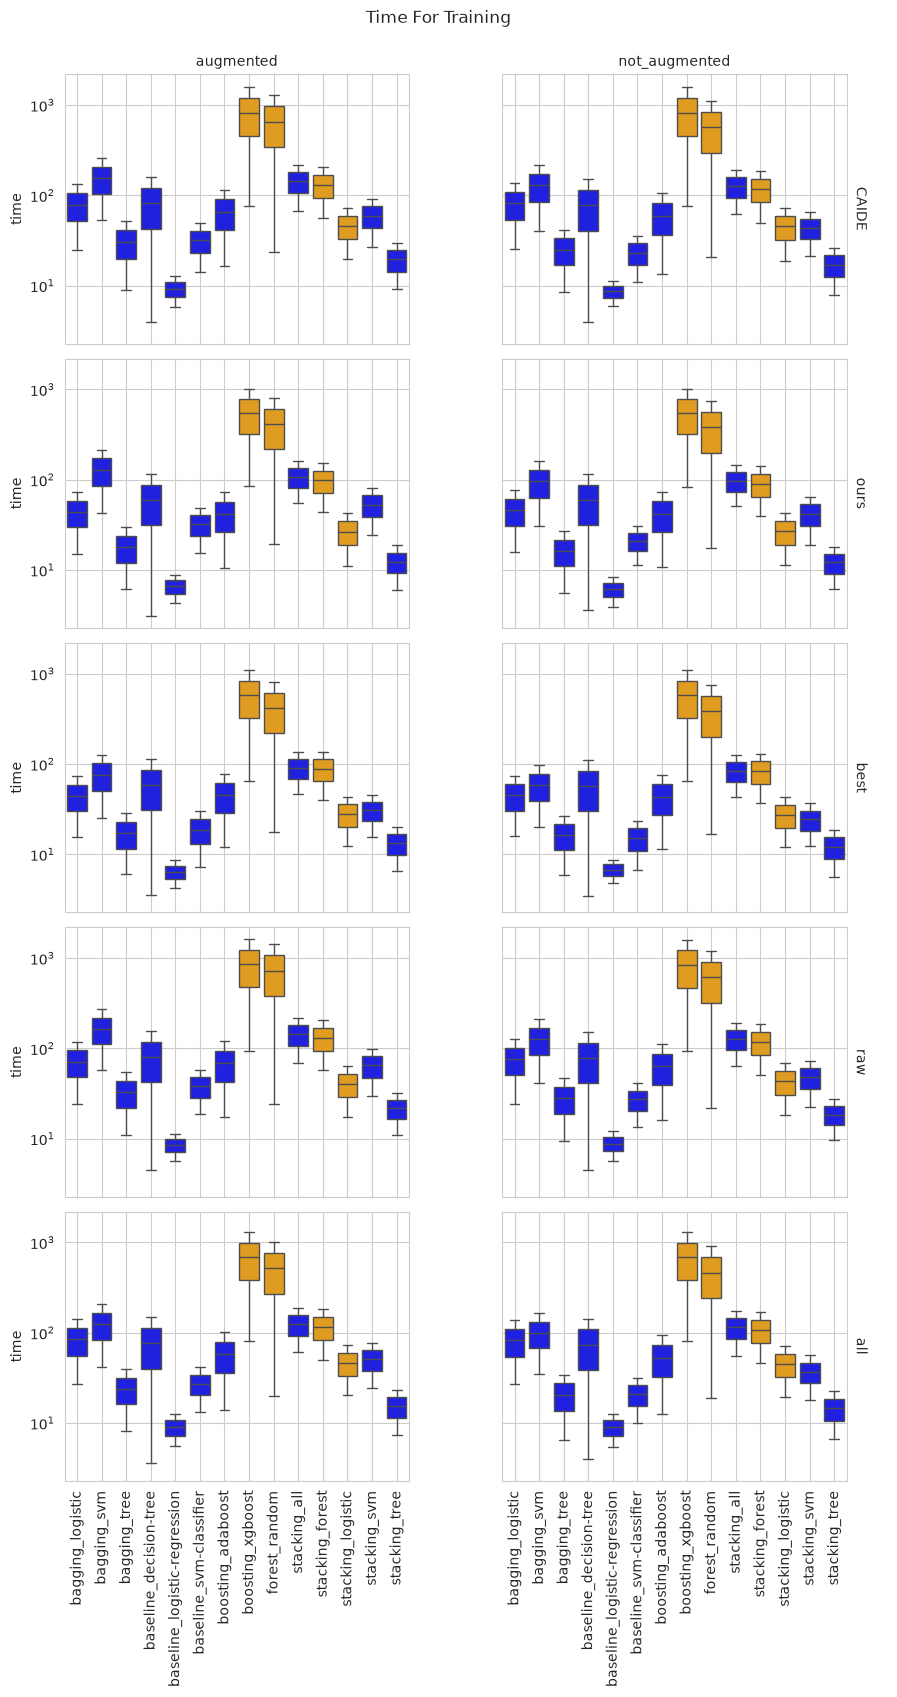

In [104]:
g = sns.FacetGrid(perf_df.loc[perf_df['task'] == 'train'], col="dataset_type", row="columns", margin_titles=True, despine=False, aspect=1.5)
g.map_dataframe(sns.boxplot, x="model", y="time", palette=c_pallete)
g.set(yscale="log")
g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.set_axis_labels('', 'time')

for ax in g.axes.flat:
    ax.tick_params(axis='x', labelrotation=90)
    ax.grid(True, axis="x") 

g._legend_data['Best Model'] = 
g._legend_data['Best Result (best params)'] = best_params
g._legend.remove()
g.add_legend()

plt.suptitle("Time For Training",y=1.02)
plt.savefig(PLOTS_PATH("time_training.png"), dpi=300, bbox_inches="tight")
plt.show()

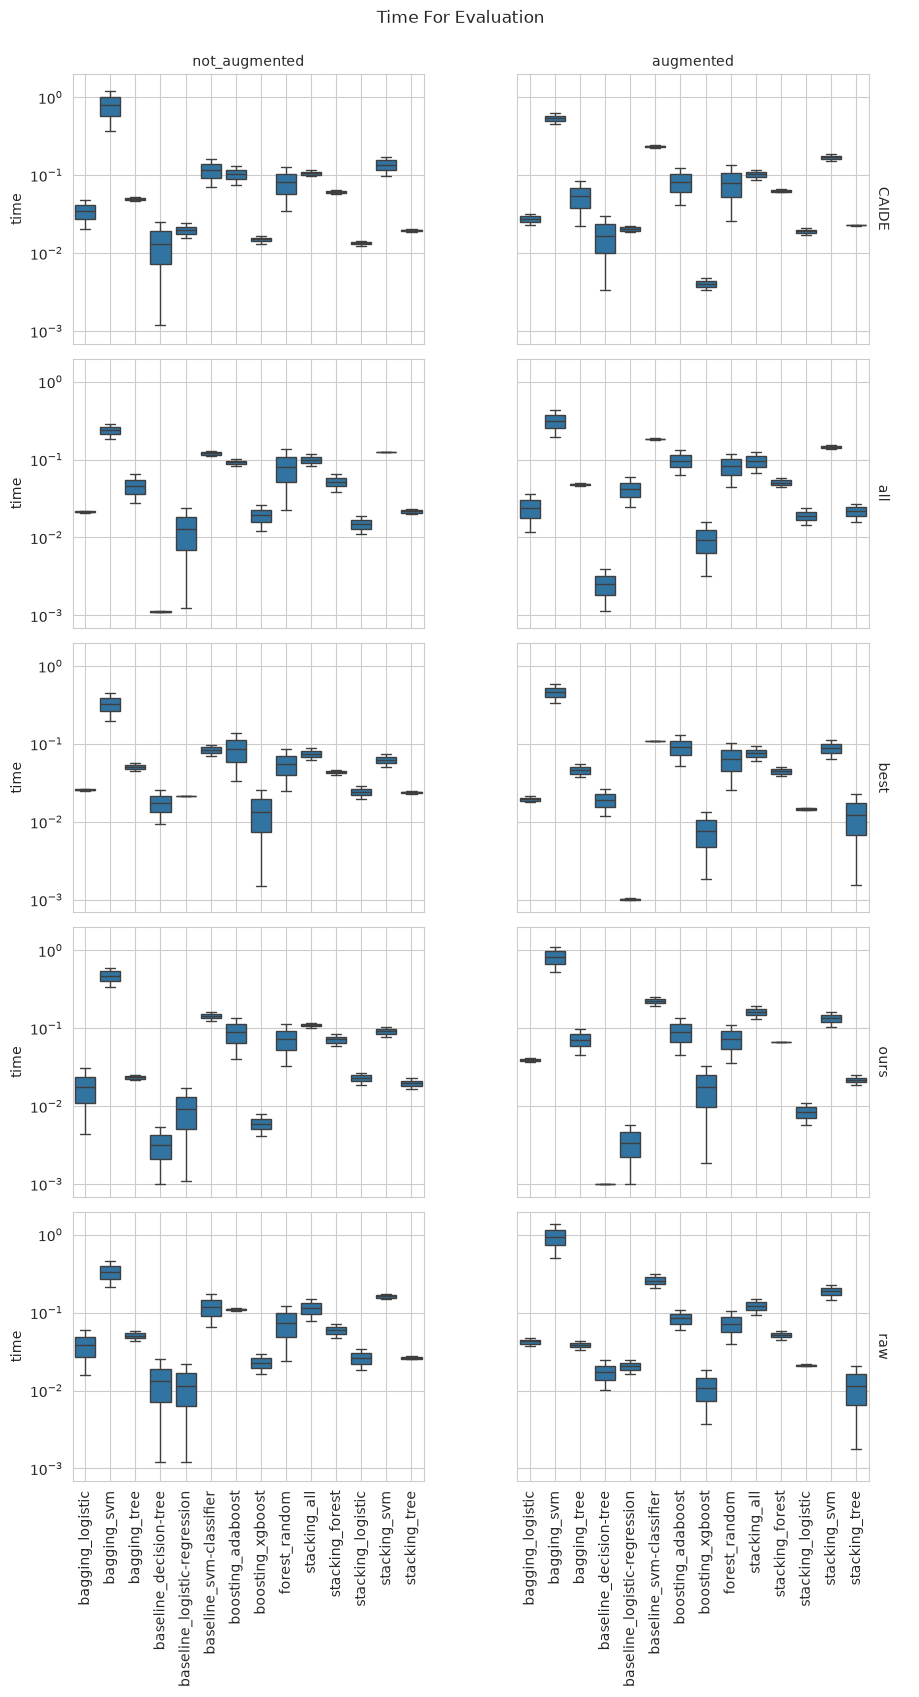

In [88]:
g = sns.FacetGrid(perf_df.loc[perf_df['task'] == 'eval'], col="dataset_type", row="columns", margin_titles=True, despine=False, aspect=1.5)
g.map_dataframe(sns.boxplot, x="model", y="time")
g.add_legend()
g.set(yscale="log")
g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.set_axis_labels('', 'time')

for ax in g.axes.flat:
    ax.tick_params(axis='x', labelrotation=90)
    ax.grid(True, axis="x") 

plt.suptitle("Time For Evaluation",y=1.02)
plt.show()